## DADOS PAINEL - TESE FERNANDO

##### **Problema**

Como os retornos econômicos esperados e o ambiente institucional condicionam a taxa de conversão da vegetação nativa em Mato Grosso, e em que medida essa relação varia conforme a capacidade produtiva local da terra, as atividades agropecuárias e os biomas?

##### **Hipótese**

H1: A conversão de vegetação nativa para usos agropecuários aumenta quando se eleva o retorno econômico esperado desses usos.

##### **Função**

\begin{equation}
\text{Conversão da vegetação nativa} = f(\text{preços agropecuários}, \text{produtividade da terra}, \text{ambiente institucional})
\end{equation}

##### **Resumo**

O artigo busca explicar, compreender e mensurar se:

1. Aumentos nos preços dos produtos agropecuários se traduzem em maior conversão onde a capacidade produtiva da terra para esses usos é mais elevada; 
2. As condições institucionais modificam a intensidade dessa resposta; 
3. Essas relações entre expectativas e respostas aos ambientes econômico e institucional variam conforme atividades agropecuárias e biomas. 

### 0. Setar ambiente

#### 0.1 Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### 0.2 Importar dados

In [2]:
caminho = r'C:\Users\ferna\Documents\dev\Tese USP\tese_eco_usp\2_INTI\chapters\chap1\stats\EDA\paineis\painel_tese_chap1_pt.csv'
df = pd.read_csv(caminho)

### 1. DATAFRAMES PT

In [3]:
# DICIONÁRIO DAS COLUNAS DE df e df2 (na ordem do CSV)
# aed_chap1_pt_DICIO.ipynb

#### 1.1 df1 (Completo)

In [4]:
# Versão completa do dataframe

In [5]:
df1 = df.copy()

In [6]:
# Transforma 'codigo_ibge' em string (ou 'category') garantindo 7 dígitos
df1['codigo_ibge'] = df1['codigo_ibge'].astype(str).str.zfill(7)

# Transforma em categoria
df1['codigo_ibge'] = df1['codigo_ibge'].astype(str).str.zfill(7).astype('category')

In [7]:
# Transforma 'ano' em formato datetime (padrão: YYYY-01-01)
df1['ano'] = pd.to_datetime(df1['ano'], format='%Y')

# Deixar apenas o ano
df1['ano'] = pd.to_datetime(df1['ano'], format='%Y').dt.to_period('Y')

##### Visão geral

In [8]:
df1.shape

(3384, 296)

In [9]:
df1.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 296 columns):
 #    Column                                                                                    Non-Null Count  Dtype        
---   ------                                                                                    --------------  -----        
 0    codigo_ibge                                                                               3384 non-null   category     
 1    ano                                                                                       3384 non-null   period[Y-DEC]
 2    conversao_ha__agricultura                                                                 2772 non-null   float64      
 3    conversao_ha__pastagem                                                                    2772 non-null   float64      
 4    taxa_conversao__agricultura                                                               2772 non-null   float64      
 5    taxa_conversao_

In [10]:
# Describe dados quantitativos, incluindo contagem de valores ausentes.
df1.describe()

,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,y_colecao,y_area_total_ha,y_area_valida_par_ha,y_area_nao_valida_par_ha,y_nativa_inicial_ha,y_fracao_area_valida_par,...,exposicao_real_x_pantanal__milho__pam_1991_2000_min7,exposicao_real_x_pantanal__soja__pam_1991_2000_min7,exposicao_real_x_pantanal__milho__gaez_sxHr0_mze,exposicao_real_x_pantanal__soja__gaez_sxHr0_soy,exposicao_real_x_pantanal__milho__gaez_sxLr0_mze,exposicao_real_x_pantanal__soja__gaez_sxLr0_soy,exposicao_real_x_pantanal__milho__gaez_yxHr0_mze,exposicao_real_x_pantanal__soja__gaez_yxHr0_soy,exposicao_real_x_pantanal__milho__gaez_yxLr0_mze,exposicao_real_x_pantanal__soja__gaez_yxLr0_soy
count,2772.000000,2772.000000,2772.000000,2772.000000,3.384000e+03,3.384000e+03,3.384000e+03,3384.000000,3.384000e+03,3384.000000,...,2808.000000,1128.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000
mean,297.697312,3257.588132,0.001122,0.011915,1.010000e+01,6.405727e+05,6.405388e+05,33.856158,4.168223e+05,0.999983,...,-0.172460,-0.049202,0.540661,0.239976,0.128428,0.177897,0.557612,0.220289,0.153728,0.189487
std,1015.382300,4832.176411,0.003751,0.014295,1.776619e-15,5.966349e+05,5.965491e+05,280.248085,4.956423e+05,0.000127,...,1.093186,0.556939,3.225393,1.319701,0.682116,0.942023,3.118690,1.122624,0.845597,1.007488
min,0.000000,0.953154,0.000000,0.000029,1.010000e+01,3.443212e+04,3.443212e+04,0.000000,6.485420e+03,0.998713,...,-10.663550,-3.839196,-0.011560,-0.048610,-0.005323,-0.000000,-0.000000,-0.086781,-0.182322,-0.185683
25%,3.114156,579.761195,0.000018,0.004291,1.010000e+01,2.291295e+05,2.291295e+05,0.000000,1.008952e+05,1.000000,...,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.000000,-0.000000,-0.000000
50%,26.987478,1644.679448,0.000143,0.007994,1.010000e+01,4.525278e+05,4.525278e+05,0.000000,2.508805e+05,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000
75%,173.347514,3769.385707,0.000761,0.014125,1.010000e+01,8.439029e+05,8.439029e+05,0.000000,4.384596e+05,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,18222.268087,56983.225434,0.079950,0.265411,1.010000e+01,2.796089e+06,2.796089e+06,3152.443287,2.737509e+06,1.000000,...,1.150761,1.352889,29.188575,12.656422,5.993453,8.806177,25.847390,8.250750,8.365882,8.575441


In [11]:
# Describe dados qualitativos, incluindo contagem de valores ausentes.
df1.describe(include=['object', 'category', 'bool', 'datetime', 'timedelta'])

C:\Users\ferna\AppData\Local\Temp\ipykernel_47444\2991025832.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df1.describe(include=['object', 'category', 'bool', 'datetime', 'timedelta'])


,codigo_ibge,y_malha,y_mascara_id,y_cobertura_completa,y_flag_denominador_zero,y_flag_denominador_ausente,flag_ano_nominal_incompleto__carne_bovina,flag_ano_nominal_incompleto__milho,flag_ano_nominal_incompleto__soja,flag_ano_real_incompleto__carne_bovina,...,flag_contagem_desmatamento_parcial__ibama_espacial,flag_soma_desmatamento_parcial__ibama_espacial,flag_soma_nominal_desmatamento_parcial__ibama_espacial,flag_sem_registro_identificado__ibama_espacial,flag_contagem_flora_parcial_lag1__ibama_espacial,flag_contagem_desmatamento_parcial_lag1__ibama_espacial,flag_soma_flora_parcial_lag1__ibama_espacial,flag_soma_desmatamento_parcial_lag1__ibama_espacial,flag_ano_incompleto,flag_ordem_invalida
count,3384,3384,3384,3384,3384,3384,3384,3384,3384,3384,...,1828,1828,1828,3384,1755,1755,1755,1755,3384,3384
unique,141,1,3384,2,1,1,1,1,1,1,...,2,2,2,2,2,2,2,2,1,1
top,5100102,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
freq,24,3384,1,2772,3384,3384,3384,3384,3384,3384,...,1159,1154,1154,1828,1449,1085,1428,1080,3384,3384


##### Agregar municípios

**df1a: perfil municipal descritivo — 2001–2024**

Uma linha por município. As médias usam os anos observados; as tabelas de cobertura mostram quantos e quais limites temporais sustentam cada resumo. A soma observada de conversões pode ser parcial; o total de 2001–2024 exige 24 anos válidos. A razão de somas é uma taxa anual média ponderada pela vegetação disponível, não um percentual acumulado de perda.

Estoques são preservados em datas exatas. Ausências continuam ausentes. Autos e multas representam registros observados, possivelmente parciais; multas estão em R$ de dezembro de 2024. Cada município recebe o mesmo peso nas descritivas entre municípios. Os resultados contextualizam o território e não estimam causalidade.


In [12]:
df1a = df1.copy()


In [13]:
df1a["ano"] = df1a["ano"].dt.year


In [14]:
# Nomes curtos apenas nesta cópia; unidades mantidas nos nomes e comentários.
df1a = df1a.rename(columns={
    'conversao_ha__agricultura': 'conv_agricultura_ha',
    'conversao_ha__pastagem': 'conv_pastagem_ha',
    'taxa_conversao__agricultura': 'taxa_agricultura',
    'taxa_conversao__pastagem': 'taxa_pastagem',
    'rendimento_medio_kg_ha__Soja (em grão)': 'prod_soja_kg_ha',
    'rendimento_medio_kg_ha__Milho (em grão)': 'prod_milho_kg_ha',
    'capacidade_valor__soja__pam_1991_2000_min7': 'cap_soja_kg_ha',
    'capacidade_valor__milho__pam_1991_2000_min7': 'cap_milho_kg_ha',
    'n_autos_desmatamento__ibama_informada': 'autos_desmat',
    'multas_desmatamento_reais_observadas__ibama_informada': 'multas_desmat_reais',
    'y_nativa_inicial_ha': 'nativa_inicio_ha',
    'agricultura_ha_lag1': 'agricultura_anterior_ha',
    'pastagem_ha_lag1': 'pastagem_anterior_ha',
    'biome_amazonia_share_i': 'amazonia_share',
    'biome_cerrado_share_i': 'cerrado_share',
    'biome_pantanal_share_i': 'pantanal_share',
    'precip_mm_anual': 'chuva_mm',
    'precip_zscore_1981_2000': 'chuva_z',
    'elevation_mean_m': 'elevacao_m',
    'y_cobertura_completa': 'cobertura_y',
    'flag_sem_registro_identificado__ibama_informada': 'sem_auto_identificado',
    'flag_contagem_desmatamento_parcial__ibama_informada': 'contagem_parcial',
    'flag_soma_desmatamento_parcial__ibama_informada': 'multa_parcial',
    'capacidade_valor__soja__gaez_sxHr0_soy': 'gaez_sx_soja_H',
    'capacidade_valor__milho__gaez_sxHr0_mze': 'gaez_sx_milho_H',
    'capacidade_valor__soja__gaez_sxLr0_soy': 'gaez_sx_soja_L',
    'capacidade_valor__milho__gaez_sxLr0_mze': 'gaez_sx_milho_L',
    'capacidade_valor__soja__gaez_yxHr0_soy': 'gaez_yx_soja_H',
    'capacidade_valor__milho__gaez_yxHr0_mze': 'gaez_yx_milho_H',
    'capacidade_valor__soja__gaez_yxLr0_soy': 'gaez_yx_soja_L',
    'capacidade_valor__milho__gaez_yxLr0_mze': 'gaez_yx_milho_L',
})


**1. Preparar cobertura, características fixas e fluxos**


In [15]:
# Cada destino usa o seu próprio conjunto de anos válidos.
df1a["ano_agricultura"] = df1a["ano"].where(df1a["conv_agricultura_ha"].notna())
df1a["ano_pastagem"] = df1a["ano"].where(df1a["conv_pastagem_ha"].notna())
df1a["nativa_exposta_agricultura"] = df1a["nativa_inicio_ha"].where(df1a["conv_agricultura_ha"].notna())
df1a["nativa_exposta_pastagem"] = df1a["nativa_inicio_ha"].where(df1a["conv_pastagem_ha"].notna())


In [16]:
fixas_1a = ['cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m', 'gaez_sx_soja_H', 'gaez_sx_milho_H', 'gaez_sx_soja_L', 'gaez_sx_milho_L', 'gaez_yx_soja_H', 'gaez_yx_milho_H', 'gaez_yx_soja_L', 'gaez_yx_milho_L']
grupo_1a = df1a.groupby("codigo_ibge", observed=True)


In [17]:
# Conferência: características fixas têm no máximo um valor válido por município.
constancia_1a = grupo_1a[fixas_1a].nunique()
constancia_1a.max()


cap_soja_kg_ha     1
cap_milho_kg_ha    1
amazonia_share     1
cerrado_share      1
pantanal_share     1
elevacao_m         1
gaez_sx_soja_H     1
gaez_sx_milho_H    1
gaez_sx_soja_L     1
gaez_sx_milho_L    1
gaez_yx_soja_H     1
gaez_yx_milho_H    1
gaez_yx_soja_L     1
gaez_yx_milho_L    1
dtype: int64

In [18]:
fixas_1a = grupo_1a[fixas_1a].first()


In [19]:
qualidade_1a = grupo_1a.agg(
    anos_grade=("ano", "size"),
    anos_y_agricultura=("ano_agricultura", "count"),
    primeiro_ano_y_agricultura=("ano_agricultura", "min"),
    ultimo_ano_y_agricultura=("ano_agricultura", "max"),
    anos_y_pastagem=("ano_pastagem", "count"),
    primeiro_ano_y_pastagem=("ano_pastagem", "min"),
    ultimo_ano_y_pastagem=("ano_pastagem", "max"),
    anos_sem_auto_identificado=("sem_auto_identificado", "sum"),
    anos_flag_contagem_conhecida=("contagem_parcial", "count"),
    anos_contagem_parcial=("contagem_parcial", "sum"),
    anos_flag_multa_conhecida=("multa_parcial", "count"),
    anos_multa_parcial=("multa_parcial", "sum")
)


In [20]:
qualidade_1a["y_24_anos"] = qualidade_1a["anos_y_agricultura"].eq(24) & qualidade_1a["anos_y_pastagem"].eq(24)
qualidade_1a["anos_flag_contagem_desconhecida"] = 24 - qualidade_1a["anos_flag_contagem_conhecida"]
qualidade_1a["anos_flag_multa_desconhecida"] = 24 - qualidade_1a["anos_flag_multa_conhecida"]


In [21]:
# min_count=1: grupos inteiramente ausentes não viram zero.
fluxos_1a = grupo_1a[["conv_agricultura_ha", "conv_pastagem_ha", "autos_desmat", "multas_desmat_reais"]].sum(min_count=1)
fluxos_1a = fluxos_1a.add_suffix("_soma_observada")
exposicao_1a = grupo_1a[["nativa_exposta_agricultura", "nativa_exposta_pastagem"]].sum(min_count=1)


In [22]:
fluxos_1a["taxa_agricultura_ponderada_pct"] = 100 * fluxos_1a["conv_agricultura_ha_soma_observada"] / exposicao_1a["nativa_exposta_agricultura"]
fluxos_1a["taxa_pastagem_ponderada_pct"] = 100 * fluxos_1a["conv_pastagem_ha_soma_observada"] / exposicao_1a["nativa_exposta_pastagem"]
fluxos_1a["conv_agricultura_total_2001_2024_ha"] = fluxos_1a["conv_agricultura_ha_soma_observada"].where(qualidade_1a["anos_y_agricultura"].eq(24))
fluxos_1a["conv_pastagem_total_2001_2024_ha"] = fluxos_1a["conv_pastagem_ha_soma_observada"].where(qualidade_1a["anos_y_pastagem"].eq(24))


In [23]:
taxas_1a = grupo_1a[["taxa_agricultura", "taxa_pastagem"]].mean()
taxas_1a = taxas_1a * 100
taxas_1a = taxas_1a.add_suffix("_media_pct")


**2. Resumir os anos observados e preservar as datas dos estoques**


In [24]:
medidas_1a = ["conv_agricultura_ha", "conv_pastagem_ha", "prod_soja_kg_ha", "prod_milho_kg_ha", "efetivo_bovino", "lotacao_cabecas_ha", "autos_desmat", "multas_desmat_reais", "chuva_mm", "chuva_z"]
estatisticas_1a = grupo_1a[medidas_1a].agg(["count", "mean", "median", "std"])
estatisticas_1a.columns = estatisticas_1a.columns.map("_".join)


In [25]:
chuva_extremos_1a = grupo_1a[["chuva_mm", "chuva_z"]].agg(["min", "max"])
chuva_extremos_1a.columns = chuva_extremos_1a.columns.map("_".join)


In [26]:
# Cobertura individual, sem eliminar conjuntamente linhas por ausência em outras medidas.
anos_1a = df1a[medidas_1a].notna()
anos_1a = anos_1a.mul(df1a["ano"], axis=0)
anos_1a = anos_1a.replace(0, np.nan)
anos_1a["codigo_ibge"] = df1a["codigo_ibge"]


In [27]:
grupo_anos_1a = anos_1a.groupby("codigo_ibge", observed=True)
cobertura_1a = grupo_anos_1a.agg(["count", "min", "max"])
cobertura_1a = cobertura_1a.stack(level=0)
cobertura_1a = cobertura_1a.rename(columns={"count": "anos_validos", "min": "primeiro_ano", "max": "ultimo_ano"})
cobertura_1a["anos_ausentes"] = 24 - cobertura_1a["anos_validos"]
cobertura_1a["lacunas_internas"] = cobertura_1a["ultimo_ano"] - cobertura_1a["primeiro_ano"] + 1 - cobertura_1a["anos_validos"]


In [28]:
# Área nativa do par de mapas: exigir cobertura completa para comparar estoques.
df1a["nativa_inicio_ha"] = df1a["nativa_inicio_ha"].where(df1a["cobertura_y"].eq(True))
# Estes campos representam t−1: linhas 2001 e 2024 contêm estoques de 2000 e 2023.
estoques_1a = ["nativa_inicio_ha", "agricultura_anterior_ha", "pastagem_anterior_ha"]
inicio_1a = df1a.loc[df1a["ano"].eq(2001), ["codigo_ibge"] + estoques_1a]
inicio_1a = inicio_1a.set_index("codigo_ibge")
fim_1a = df1a.loc[df1a["ano"].eq(2024), ["codigo_ibge"] + estoques_1a]
fim_1a = fim_1a.set_index("codigo_ibge")


In [29]:
mudanca_1a = fim_1a - inicio_1a
mudanca_1a = mudanca_1a.add_suffix("_mudanca_2000_2023")
inicio_1a = inicio_1a.add_suffix("_2000")
fim_1a = fim_1a.add_suffix("_2023")


In [30]:
# Datas exatas do rebanho; não usar first/last, que podem pular ausências.
rebanho_1a = df1a.loc[df1a["ano"].isin([2001, 2024]), ["codigo_ibge", "ano", "efetivo_bovino"]]
rebanho_1a = rebanho_1a.pivot(index="codigo_ibge", columns="ano", values="efetivo_bovino")
rebanho_1a = rebanho_1a.rename(columns={2001: "bovinos_2001", 2024: "bovinos_2024"})
rebanho_1a["bovinos_mudanca_2001_2024"] = rebanho_1a["bovinos_2024"] - rebanho_1a["bovinos_2001"]


Em `df1a`, os estoques contemporâneos permitem também comparar **2001 e 2024**, sempre dentro da mesma fonte de estoques. GAEZ: `sx` é índice 0–10.000; `yx` é kg de matéria seca/ha; H/L são cenários de alto/baixo insumo. As pendências de comparabilidade histórica e de temporalidade dessas fontes permanecem.


In [31]:
estoques_atuais_1a = ["nativa_ha", "agricultura_ha", "pastagem_ha"]
inicio_atual_1a = df1a.loc[df1a["ano"].eq(2001), ["codigo_ibge"] + estoques_atuais_1a]
inicio_atual_1a = inicio_atual_1a.set_index("codigo_ibge")
fim_atual_1a = df1a.loc[df1a["ano"].eq(2024), ["codigo_ibge"] + estoques_atuais_1a]
fim_atual_1a = fim_atual_1a.set_index("codigo_ibge")


In [32]:
mudanca_atual_1a = fim_atual_1a - inicio_atual_1a
mudanca_atual_1a = mudanca_atual_1a.add_suffix("_mudanca_2001_2024")
inicio_atual_1a = inicio_atual_1a.add_suffix("_2001")
fim_atual_1a = fim_atual_1a.add_suffix("_2024")


In [33]:
df1a = pd.concat([qualidade_1a, fluxos_1a, taxas_1a, estatisticas_1a, chuva_extremos_1a, fixas_1a, inicio_1a, fim_1a, mudanca_1a, rebanho_1a, inicio_atual_1a, fim_atual_1a, mudanca_atual_1a], axis=1)
df1a = df1a.reset_index()


In [34]:
df1a.shape


(141, 105)

In [35]:
df1a.head()


,codigo_ibge,anos_grade,anos_y_agricultura,primeiro_ano_y_agricultura,ultimo_ano_y_agricultura,anos_y_pastagem,primeiro_ano_y_pastagem,ultimo_ano_y_pastagem,anos_sem_auto_identificado,anos_flag_contagem_conhecida,...,bovinos_mudanca_2001_2024,nativa_ha_2001,agricultura_ha_2001,pastagem_ha_2001,nativa_ha_2024,agricultura_ha_2024,pastagem_ha_2024,nativa_ha_mudanca_2001_2024,agricultura_ha_mudanca_2001_2024,pastagem_ha_mudanca_2001_2024
0,5100102,24,24,2001.0,2024.0,24,2001.0,2024.0,14,10,...,22717.0,58880.226410,86.115860,23903.061806,51393.515662,319.273265,30110.148195,-7486.710749,233.157405,6207.086389
1,5100201,24,24,2001.0,2024.0,24,2001.0,2024.0,5,19,...,-36920.0,354366.080543,41049.694763,345644.440653,310491.440556,177369.670210,203773.662917,-43874.639986,136319.975447,-141870.777737
2,5100250,24,14,2009.0,2024.0,14,2009.0,2024.0,0,24,...,151779.0,515887.901520,2132.966484,368751.582648,425626.849714,62080.326512,395926.464859,-90261.051807,59947.360028,27174.882211
3,5100300,24,24,2001.0,2024.0,24,2001.0,2024.0,4,20,...,29585.0,293461.790884,17800.152268,217004.528510,273168.085101,46054.423490,183250.409070,-20293.705782,28254.271222,-33754.119441
4,5100359,24,24,2001.0,2024.0,24,2001.0,2024.0,7,17,...,-12713.0,150328.569491,637.185678,73061.093937,86126.275605,42946.190971,92638.944053,-64202.293886,42309.005294,19577.850116


**3. Cobertura e estatísticas entre municípios**

`mean`, `median` e `std` nos nomes são resumos dos anos observados de cada município; `count` é o número desses anos. A tabela abaixo descreve a distribuição desses resumos entre municípios, com N e ausências por medida. Não há exclusão conjunta de casos, imputação, testes ou intervalos de confiança. Os totais completos têm suporte menor que as somas parciais.


In [36]:
descrever_1a = ['taxa_agricultura_media_pct', 'taxa_pastagem_media_pct', 'taxa_agricultura_ponderada_pct', 'taxa_pastagem_ponderada_pct', 'conv_agricultura_total_2001_2024_ha', 'conv_pastagem_total_2001_2024_ha', 'prod_soja_kg_ha_mean', 'prod_milho_kg_ha_mean', 'efetivo_bovino_mean', 'lotacao_cabecas_ha_mean', 'autos_desmat_mean', 'multas_desmat_reais_mean', 'chuva_mm_mean', 'chuva_mm_std', 'chuva_z_min', 'chuva_z_max', 'cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m']


In [37]:
descritiva_1a = df1a[descrever_1a].describe(percentiles=[0.25, 0.5, 0.75])
descritiva_1a = descritiva_1a.T
descritiva_1a["ausentes"] = len(df1a) - descritiva_1a["count"]
descritiva_1a["IQR"] = descritiva_1a["75%"] - descritiva_1a["25%"]
descritiva_1a.round(3)


,count,mean,std,min,25%,50%,75%,max,ausentes,IQR
taxa_agricultura_media_pct,137.0,0.112,0.192,0.000,0.008,0.034,0.126,1.238000e+00,4.0,0.118
taxa_pastagem_media_pct,137.0,1.190,0.785,0.095,0.625,1.069,1.468,4.389000e+00,4.0,0.843
taxa_agricultura_ponderada_pct,137.0,0.120,0.219,0.000,0.008,0.034,0.133,1.528000e+00,4.0,0.124
taxa_pastagem_ponderada_pct,137.0,1.225,0.828,0.097,0.632,1.069,1.509,4.459000e+00,4.0,0.876
conv_agricultura_total_2001_2024_ha,95.0,6018.255,10634.153,0.776,290.240,1297.081,4542.552,4.838944e+04,46.0,4252.312
conv_pastagem_total_2001_2024_ha,95.0,62324.647,75188.467,1519.421,14029.368,44311.446,80288.131,5.889647e+05,46.0,66258.763
prod_soja_kg_ha_mean,136.0,3139.312,175.935,2648.867,3055.844,3130.208,3200.031,3.767500e+03,5.0,144.188
prod_milho_kg_ha_mean,141.0,4206.873,784.453,1863.368,3768.500,4268.050,4717.000,6.115250e+03,0.0,948.500
efetivo_bovino_mean,141.0,202589.903,185675.451,14341.350,73124.500,141447.208,290373.500,1.006741e+06,0.0,217249.000
lotacao_cabecas_ha_mean,141.0,1.471,0.502,0.355,1.141,1.435,1.771,3.814000e+00,0.0,0.629


In [38]:
# Distribuição da cobertura de cada medida: municípios × número de anos válidos.
tabela_cobertura_1a = cobertura_1a.reset_index()
tabela_cobertura_1a = pd.crosstab(tabela_cobertura_1a["level_1"], tabela_cobertura_1a["anos_validos"])
tabela_cobertura_1a


anos_validos,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
level_1,,,,,,,,,,,,,,,,,,,,,
autos_desmat,2,4,9,6,8,6,9,8,3,5,...,2,5,4,5,9,8,11,7,3,4
chuva_mm,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
chuva_z,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
conv_agricultura_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
conv_pastagem_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
efetivo_bovino,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
lotacao_cabecas_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
multas_desmat_reais,2,4,9,6,8,6,10,7,3,6,...,2,5,4,5,10,7,11,7,3,4
prod_milho_kg_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,4,3,6,4,121


In [39]:
# Parcialidade conhecida e desconhecida deve acompanhar a leitura do IBAMA.
df1a[["codigo_ibge", "autos_desmat_count", "multas_desmat_reais_count", "anos_contagem_parcial", "anos_flag_contagem_desconhecida", "anos_multa_parcial", "anos_flag_multa_desconhecida"]].head(10)


,codigo_ibge,autos_desmat_count,multas_desmat_reais_count,anos_contagem_parcial,anos_flag_contagem_desconhecida,anos_multa_parcial,anos_flag_multa_desconhecida
0,5100102,7,7,7,14,7,14
1,5100201,12,12,11,5,11,5
2,5100250,22,22,19,0,19,0
3,5100300,14,14,16,4,16,4
4,5100359,13,13,11,7,11,7
5,5100409,8,8,13,8,13,8
6,5100508,4,4,4,17,4,17
7,5100607,9,9,8,9,8,9
8,5100805,20,20,19,0,19,0
9,5101001,13,13,17,3,17,3


In [40]:
# Comparação de Y com janela comum: conserva apenas os 24 anos completos nesta tabela.
completos_1a = df1a.loc[df1a["y_24_anos"]].copy()
completos_1a[["taxa_agricultura_ponderada_pct", "taxa_pastagem_ponderada_pct"]].describe().T


,count,mean,std,min,25%,50%,75%,max
taxa_agricultura_ponderada_pct,95.0,0.118497,0.220837,0.000450,0.008456,0.030111,0.134457,1.528089
taxa_pastagem_ponderada_pct,95.0,1.197875,0.808300,0.096504,0.623780,1.079040,1.495796,4.458761


As figuras de Y com janela comum usam os municípios com 24 anos válidos. Essa seleção melhora a comparabilidade temporal, mas não representa automaticamente os 141 municípios. Valores extremos são mantidos; os pontos dos boxplots não são descartes.


**4. Figuras: distribuição das taxas, produtividade e contexto de preços**


In [41]:
grafico_1a = df1a[["taxa_agricultura_ponderada_pct", "y_24_anos"]].copy()
grafico_1a["Cobertura"] = np.where(grafico_1a["y_24_anos"], "24 anos", "Menos de 24 anos")
grafico_1a = grafico_1a.dropna(subset=["taxa_agricultura_ponderada_pct"])


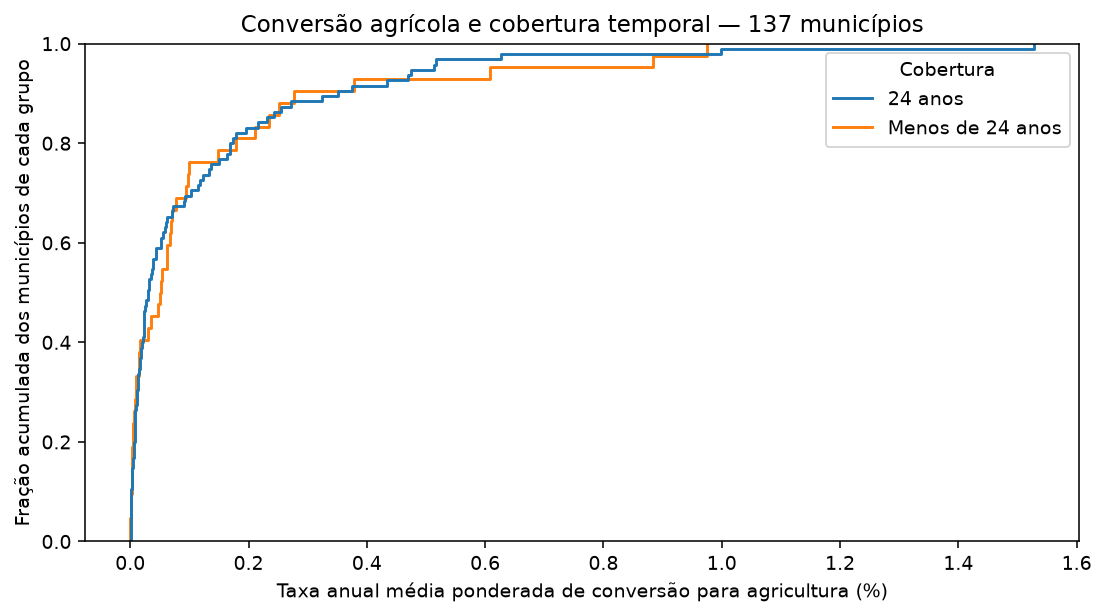

In [42]:
plt.figure(figsize=(8, 4.5), dpi=140)
sns.ecdfplot(data=grafico_1a, x="taxa_agricultura_ponderada_pct", hue="Cobertura")
plt.xlabel("Taxa anual média ponderada de conversão para agricultura (%)")
plt.ylabel("Fração acumulada dos municípios de cada grupo")
plt.title(f"Conversão agrícola e cobertura temporal — {len(grafico_1a)} municípios")
plt.tight_layout()
plt.show()


A curva com cobertura incompleta descreve os anos disponíveis, que variam entre municípios; não é uma comparação de períodos idênticos. Os quatro municípios sem Y não aparecem na curva.


In [43]:
produtividade_1a = df1a[["prod_soja_kg_ha_mean", "prod_milho_kg_ha_mean"]].copy()
produtividade_1a["prod_soja_kg_ha_mean"] = produtividade_1a["prod_soja_kg_ha_mean"].where(df1a["prod_soja_kg_ha_count"].eq(24))
produtividade_1a["prod_milho_kg_ha_mean"] = produtividade_1a["prod_milho_kg_ha_mean"].where(df1a["prod_milho_kg_ha_count"].eq(24))
produtividade_1a = produtividade_1a.rename(columns={"prod_soja_kg_ha_mean": "Soja", "prod_milho_kg_ha_mean": "Milho"})


In [44]:
produtividade_1a.count()


Soja      66
Milho    121
dtype: int64

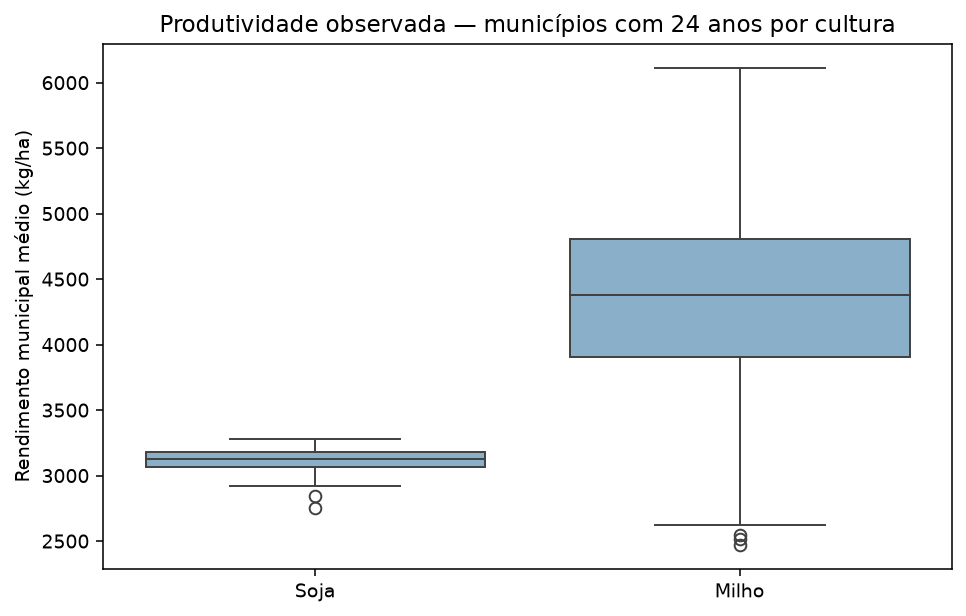

In [45]:
plt.figure(figsize=(7, 4.5), dpi=140)
sns.boxplot(data=produtividade_1a, color="#80b1d3")
plt.ylabel("Rendimento municipal médio (kg/ha)")
plt.title("Produtividade observada — municípios com 24 anos por cultura")
plt.tight_layout()
plt.show()


Os números de municípios por cultura estão na tabela anterior. As amostras podem diferir; a média de produtividade observada não é capacidade predeterminada nem efeito da conversão.


In [46]:
# Preços comuns: uma observação por ano; não entram como médias espaciais em df1a.
colunas_precos_1a = ["preco_real_usd2024_media_anual__soja", "preco_real_usd2024_media_anual__milho", "preco_real_usd2024_media_anual__carne_bovina"]
precos_1a = df1[["ano"] + colunas_precos_1a].drop_duplicates()
precos_1a = precos_1a.sort_values("ano")
precos_1a["ano"] = precos_1a["ano"].dt.year
precos_1a = precos_1a.set_index("ano")
precos_1a.columns = ["Soja (US$ 2024/t)", "Milho (US$ 2024/t)", "Carne (US$ 2024/kg)"]


In [47]:
precos_1a.round(2)


,Soja (US$ 2024/t),Milho (US$ 2024/t),Carne (US$ 2024/kg)
ano,,,
2001,346.97,158.85,3.73
2002,370.67,173.03,3.68
2003,450.06,179.71,3.63
2004,509.72,185.82,4.44
2005,441.48,158.50,4.39
2006,418.05,189.56,4.12
2007,578.86,247.65,4.08
2008,759.38,324.58,4.71
2009,619.20,242.06,3.99


In [48]:
indices_precos_1a = precos_1a.div(precos_1a.loc[2001])
indices_precos_1a = indices_precos_1a * 100
indices_precos_1a.columns = ["Soja", "Milho", "Carne bovina"]


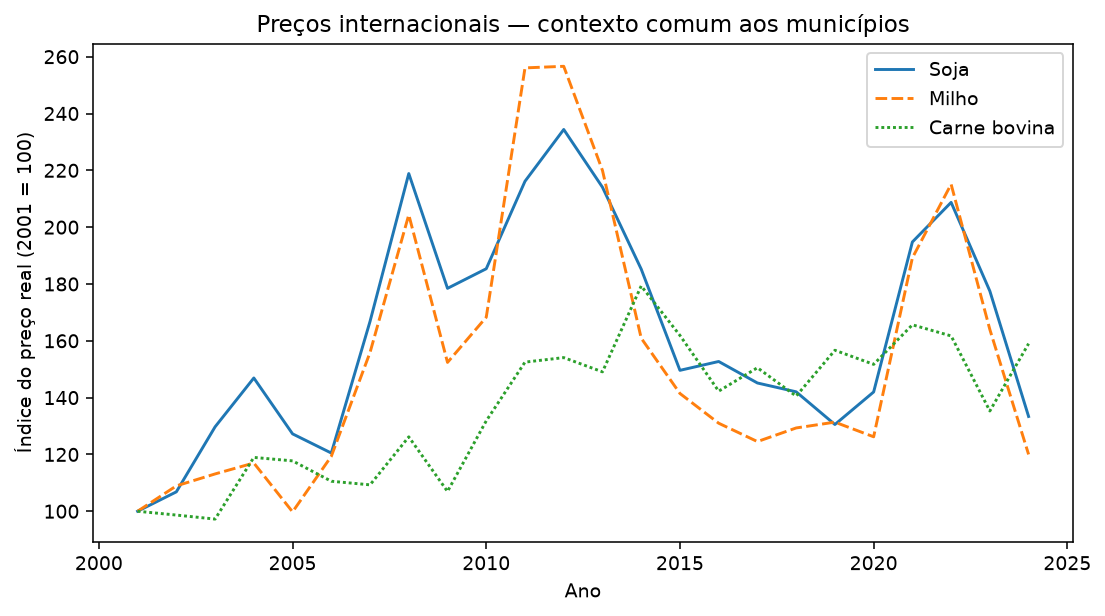

In [49]:
plt.figure(figsize=(8, 4.5), dpi=140)
sns.lineplot(data=indices_precos_1a)
plt.xlabel("Ano")
plt.ylabel("Índice do preço real (2001 = 100)")
plt.title("Preços internacionais — contexto comum aos municípios")
plt.tight_layout()
plt.show()


In [50]:
# Cenários biofísicos separados: sx em índice 0–10.000; yx em kg de matéria seca/ha.
descritiva_gaez_1a = df1a.filter(regex="^gaez_")
descritiva_gaez_1a = descritiva_gaez_1a.describe()
descritiva_gaez_1a.T


,count,mean,std,min,25%,50%,75%,max
gaez_sx_soja_H,141.0,4984.728548,689.401652,2957.916148,4643.772889,5035.043181,5312.297693,6490.347647
gaez_sx_milho_H,141.0,2992.379072,538.782035,1807.545099,2725.614888,3036.648127,3232.097767,5615.814507
gaez_sx_soja_L,141.0,2134.382390,379.454710,1200.559205,1815.676130,2091.100590,2411.345280,3296.448079
gaez_sx_milho_L,141.0,2219.049275,445.370311,1284.132818,1907.368867,2178.400222,2520.525961,4194.654552
gaez_yx_soja_H,141.0,2921.531214,380.929988,1753.346682,2595.856713,2832.162697,3270.367615,3733.417170
gaez_yx_milho_H,141.0,3303.268993,781.291513,1969.714991,2863.587789,3144.184983,3467.729252,7008.442922
gaez_yx_soja_L,141.0,302.574885,70.139817,111.580027,268.413006,302.181454,343.315793,512.229209
gaez_yx_milho_L,141.0,890.826527,211.449067,389.494389,768.662488,869.009790,1008.395804,1580.565073


In [51]:
# Variação líquida de estoques na fonte de classes; não é conversão bruta.
df1a[["nativa_ha_2001", "nativa_ha_2024", "nativa_ha_mudanca_2001_2024", "agricultura_ha_2024", "pastagem_ha_2024"]].describe().T


,count,mean,std,min,25%,50%,75%,max
nativa_ha_2001,141.0,458675.893825,530010.119299,7973.320564,113662.880497,291033.247881,508109.322547,2.721688e+06
nativa_ha_2024,141.0,389638.750078,473010.163938,6517.857145,94291.555521,227163.947394,410087.254348,2.207162e+06
nativa_ha_mudanca_2001_2024,141.0,-69037.143747,80265.942141,-530418.207444,-87333.009862,-45451.806531,-12204.297348,5.272550e+04
agricultura_ha_2024,141.0,88067.816651,118744.580117,58.863846,6134.344871,41316.213228,121915.261531,6.089837e+05
pastagem_ha_2024,141.0,143297.291181,130429.295930,4074.424030,50488.466135,105385.807900,206548.609815,6.794286e+05


#### 1.2 df2 (Sintético)

In [52]:
# Versão sintética do dataframe

In [53]:
### df2 — seleção para análise preliminar

# Base: `../HIPOTESES TESE - CHAP1.txt`. Período confirmado: **2001–2024**.
# São **30 colunas: 2 identificadoras, 24 medidas e 4 indicadores de qualidade**.
# A seleção serve à descrição inicial; não define uma especificação econométrica.

# - **Y:** conversão em hectares e taxa em proporção, com agricultura e pastagem separadas.
# - **X1:** preços médios anuais reais, na unidade de cada produto. São referências internacionais comuns aos municípios. Nesta leitura, usam-se valores do próprio ano, sem interpretá-los como expectativa de retorno.
# - **X2:** rendimentos observados da PAM e médias históricas de 1991–2000 (mínimo de 7 anos válidos). A capacidade histórica tem cobertura seletiva, sobretudo para soja. Os cenários GAEZ ficam em `df` para uma comparação posterior.
# - **X3:** contagem e multas reais de Desmatamento/Desmatamento e Queimada, pelo município informado no auto. As flags acompanham essas medidas porque há contagens/somas parciais. Valor autuado não é pagamento, e autuações não medem diretamente efetividade da fiscalização.
# - **X4–X6:** rebanho, lotação aparente, vegetação nativa inicial na máscara de Y, usos instalados em t−1 e frações dos três biomas.
# - **X8–X9:** chuva anual, anomalia padronizada com referência 1981–2000 e elevação média.

# Custos (X7) e embargos ainda não têm medidas prontas no painel. Logs, diferenças de logs,
# interações, demais defasagens e alternativas territoriais permanecem em `df`.
# `df2` conserva nomes, valores, linhas e ausências; não aplica imputação nem exclusão de casos incompletos.


In [54]:
# Seleção simplificada do roteiro H1: 141 municípios de MT, 2001–2024.
# Cada produto/destino permanece separado. Proporções não estão em %.
# As flags de qualidade acompanham Y e IBAMA; não são controles do modelo.

colunas_df2 = [
    # Identificação
    'codigo_ibge',  # Código municipal IBGE.
    'ano',  # Ano civil.

    # Y — conversão de vegetação nativa entre t−1 e t (municipal, anual)
    'conversao_ha__agricultura',  # ha convertidos para agricultura.
    'conversao_ha__pastagem',  # ha convertidos para pastagem.
    'taxa_conversao__agricultura',  # Proporção da vegetação nativa inicial.
    'taxa_conversao__pastagem',  # Proporção da vegetação nativa inicial.

    # X1 — preços internacionais reais, médias anuais do ano t
    'preco_real_usd2024_media_anual__soja',  # US$ de 2024/t.
    'preco_real_usd2024_media_anual__milho',  # US$ de 2024/t.
    'preco_real_usd2024_media_anual__carne_bovina',  # US$ de 2024/kg.

    # X2 — produtividade PAM observada e histórica (municipal; kg/ha)
    'rendimento_medio_kg_ha__Soja (em grão)',  # Rendimento observado no ano.
    'rendimento_medio_kg_ha__Milho (em grão)',  # Rendimento observado no ano.
    'capacidade_valor__soja__pam_1991_2000_min7',  # Média histórica fixa.
    'capacidade_valor__milho__pam_1991_2000_min7',  # Média histórica fixa.

    # X3 — IBAMA, tema desmatamento, município informado, ano da lavratura
    'n_autos_desmatamento__ibama_informada',  # Quantidade de autos.
    'multas_desmatamento_reais_observadas__ibama_informada',  # R$ de dez./2024 autuados.

    # X4 — pecuária (municipal, anual)
    'efetivo_bovino',  # Cabeças de bovinos (PPM).
    'lotacao_cabecas_ha',  # Cabeças/ha de pastagem; lotação aparente.

    # X5 — vegetação inicial e usos instalados (municipal; ha em t−1)
    'y_nativa_inicial_ha',  # Estoque nativo na mesma máscara das transições de Y.
    'agricultura_ha_lag1',  # Estoque de área agrícola no ano anterior.
    'pastagem_ha_lag1',  # Estoque de área de pastagem no ano anterior.

    # X6 — composição de biomas (municipal, fixa; proporções 0–1)
    'biome_amazonia_share_i',
    'biome_cerrado_share_i',
    'biome_pantanal_share_i',

    # X8 — chuva CHIRPS (municipal, anual)
    'precip_mm_anual',  # Precipitação acumulada no ano civil; mm.
    'precip_zscore_1981_2000',  # Anomalia em desvios-padrão; adimensional.

    # X9 — relevo (municipal, fixo)
    'elevation_mean_m',  # Elevação média da superfície (DSM); m.

    # Qualidade — True indica a condição descrita; ausência não equivale a False.
    'y_cobertura_completa',  # Par de mapas com cobertura integral para Y.
    'flag_sem_registro_identificado__ibama_informada',  # Sem auto identificado.
    'flag_contagem_desmatamento_parcial__ibama_informada',  # Contagem parcial.
    'flag_soma_desmatamento_parcial__ibama_informada',  # Soma de multas reais parcial.
]

df2 = df.loc[:, colunas_df2].copy()

In [55]:
# Transforma 'codigo_ibge' em string (ou 'category') garantindo 7 dígitos
df2['codigo_ibge'] = df2['codigo_ibge'].astype(str).str.zfill(7)

# Transforma em categoria
df2['codigo_ibge'] = df2['codigo_ibge'].astype(str).str.zfill(7).astype('category')

In [56]:
# Transforma 'ano' em formato datetime (padrão: YYYY-01-01)
df2['ano'] = pd.to_datetime(df2['ano'], format='%Y')

# Deixar apenas o ano
df2['ano'] = pd.to_datetime(df2['ano'], format='%Y').dt.to_period('Y')

##### Visão geral

In [57]:
df2.shape

(3384, 30)

In [58]:
df2.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 30 columns):
 #   Column                                                 Non-Null Count  Dtype        
---  ------                                                 --------------  -----        
 0   codigo_ibge                                            3384 non-null   category     
 1   ano                                                    3384 non-null   period[Y-DEC]
 2   conversao_ha__agricultura                              2772 non-null   float64      
 3   conversao_ha__pastagem                                 2772 non-null   float64      
 4   taxa_conversao__agricultura                            2772 non-null   float64      
 5   taxa_conversao__pastagem                               2772 non-null   float64      
 6   preco_real_usd2024_media_anual__soja                   3384 non-null   float64      
 7   preco_real_usd2024_media_anual__milho                  3384 non-null   float64      
 8  

In [59]:
# Describe dados quantitativos, incluindo contagem de valores ausentes.
df2.describe()

,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,preco_real_usd2024_media_anual__soja,preco_real_usd2024_media_anual__milho,preco_real_usd2024_media_anual__carne_bovina,rendimento_medio_kg_ha__Soja (em grão),rendimento_medio_kg_ha__Milho (em grão),capacidade_valor__soja__pam_1991_2000_min7,...,lotacao_cabecas_ha,y_nativa_inicial_ha,agricultura_ha_lag1,pastagem_ha_lag1,biome_amazonia_share_i,biome_cerrado_share_i,biome_pantanal_share_i,precip_mm_anual,precip_zscore_1981_2000,elevation_mean_m
count,2772.000000,2772.000000,2772.000000,2772.000000,3384.000000,3384.000000,3384.000000,2615.000000,3318.000000,1128.000000,...,3376.000000,3.384000e+03,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000,3384.000000
mean,297.697312,3257.588132,0.001122,0.011915,564.811723,245.199191,5.093596,3116.528107,4219.090717,2492.238129,...,1.470776,4.168223e+05,64451.787068,143597.824620,0.529147,0.442483,0.028354,1728.719389,-0.141756,354.818208
std,1015.382300,4832.176411,0.003751,0.014295,129.059773,72.432632,0.883185,379.187713,1509.842385,173.464064,...,0.693924,4.956423e+05,104419.380122,120347.816570,0.449139,0.442866,0.137976,367.019152,1.322443,123.210289
min,0.000000,0.953154,0.000000,0.000029,346.971098,158.498215,3.626947,900.000000,600.000000,2117.100000,...,0.069283,6.485420e+03,0.000000,3958.176720,0.000000,0.000000,0.000000,665.267759,-5.712556,120.106876
25%,3.114156,579.761195,0.000018,0.004291,460.261568,190.353931,4.324344,2992.000000,3000.000000,2347.600000,...,1.066957,1.008952e+05,1600.214075,54470.659872,0.000000,0.000000,0.000000,1465.602065,-0.931399,275.598470
50%,26.987478,1644.679448,0.000143,0.007994,524.462840,216.679294,5.274027,3120.000000,4136.500000,2489.000000,...,1.397384,2.508805e+05,16151.843687,111152.027868,0.711130,0.252627,0.000000,1702.990964,-0.179526,338.721026
75%,173.347514,3769.385707,0.000761,0.014125,651.309836,275.632105,5.770997,3300.000000,5490.250000,2620.300000,...,1.741431,4.384596e+05,74939.625521,202325.293603,1.000000,1.000000,0.000000,1982.263489,0.631314,411.357121
max,18222.268087,56983.225434,0.079950,0.265411,813.211356,407.619924,6.687605,4600.000000,8355.000000,2913.500000,...,8.491291,2.737509e+06,608255.137072,683014.513040,1.000000,1.000000,0.997371,3038.987243,6.308761,810.711629


In [60]:
# Describe dados qualitativos, incluindo contagem de valores ausentes.
df2.describe(include=['object', 'category', 'bool', 'datetime', 'timedelta'])

,codigo_ibge,y_cobertura_completa,flag_sem_registro_identificado__ibama_informada,flag_contagem_desmatamento_parcial__ibama_informada,flag_soma_desmatamento_parcial__ibama_informada
count,3384,3384,3384,2284,2284
unique,141,2,2,2,2
top,5100102,True,False,True,True
freq,24,2772,2284,1606,1611


##### Agregar municípios

**df2a: perfil municipal descritivo — 2001–2024**

Uma linha por município. As médias usam os anos observados; as tabelas de cobertura mostram quantos e quais limites temporais sustentam cada resumo. A soma observada de conversões pode ser parcial; o total de 2001–2024 exige 24 anos válidos. A razão de somas é uma taxa anual média ponderada pela vegetação disponível, não um percentual acumulado de perda.

Estoques são preservados em datas exatas. Ausências continuam ausentes. Autos e multas representam registros observados, possivelmente parciais; multas estão em R$ de dezembro de 2024. Cada município recebe o mesmo peso nas descritivas entre municípios. Os resultados contextualizam o território e não estimam causalidade.


In [61]:
df2a = df2.copy()


In [62]:
df2a["ano"] = df2a["ano"].dt.year


In [63]:
# Nomes curtos apenas nesta cópia; unidades mantidas nos nomes e comentários.
df2a = df2a.rename(columns={
    'conversao_ha__agricultura': 'conv_agricultura_ha',
    'conversao_ha__pastagem': 'conv_pastagem_ha',
    'taxa_conversao__agricultura': 'taxa_agricultura',
    'taxa_conversao__pastagem': 'taxa_pastagem',
    'rendimento_medio_kg_ha__Soja (em grão)': 'prod_soja_kg_ha',
    'rendimento_medio_kg_ha__Milho (em grão)': 'prod_milho_kg_ha',
    'capacidade_valor__soja__pam_1991_2000_min7': 'cap_soja_kg_ha',
    'capacidade_valor__milho__pam_1991_2000_min7': 'cap_milho_kg_ha',
    'n_autos_desmatamento__ibama_informada': 'autos_desmat',
    'multas_desmatamento_reais_observadas__ibama_informada': 'multas_desmat_reais',
    'y_nativa_inicial_ha': 'nativa_inicio_ha',
    'agricultura_ha_lag1': 'agricultura_anterior_ha',
    'pastagem_ha_lag1': 'pastagem_anterior_ha',
    'biome_amazonia_share_i': 'amazonia_share',
    'biome_cerrado_share_i': 'cerrado_share',
    'biome_pantanal_share_i': 'pantanal_share',
    'precip_mm_anual': 'chuva_mm',
    'precip_zscore_1981_2000': 'chuva_z',
    'elevation_mean_m': 'elevacao_m',
    'y_cobertura_completa': 'cobertura_y',
    'flag_sem_registro_identificado__ibama_informada': 'sem_auto_identificado',
    'flag_contagem_desmatamento_parcial__ibama_informada': 'contagem_parcial',
    'flag_soma_desmatamento_parcial__ibama_informada': 'multa_parcial',
})


**1. Preparar cobertura, características fixas e fluxos**


In [64]:
# Cada destino usa o seu próprio conjunto de anos válidos.
df2a["ano_agricultura"] = df2a["ano"].where(df2a["conv_agricultura_ha"].notna())
df2a["ano_pastagem"] = df2a["ano"].where(df2a["conv_pastagem_ha"].notna())
df2a["nativa_exposta_agricultura"] = df2a["nativa_inicio_ha"].where(df2a["conv_agricultura_ha"].notna())
df2a["nativa_exposta_pastagem"] = df2a["nativa_inicio_ha"].where(df2a["conv_pastagem_ha"].notna())


In [65]:
fixas_2a = ['cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m']
grupo_2a = df2a.groupby("codigo_ibge", observed=True)


In [66]:
# Conferência: características fixas têm no máximo um valor válido por município.
constancia_2a = grupo_2a[fixas_2a].nunique()
constancia_2a.max()


cap_soja_kg_ha     1
cap_milho_kg_ha    1
amazonia_share     1
cerrado_share      1
pantanal_share     1
elevacao_m         1
dtype: int64

In [67]:
fixas_2a = grupo_2a[fixas_2a].first()


In [68]:
qualidade_2a = grupo_2a.agg(
    anos_grade=("ano", "size"),
    anos_y_agricultura=("ano_agricultura", "count"),
    primeiro_ano_y_agricultura=("ano_agricultura", "min"),
    ultimo_ano_y_agricultura=("ano_agricultura", "max"),
    anos_y_pastagem=("ano_pastagem", "count"),
    primeiro_ano_y_pastagem=("ano_pastagem", "min"),
    ultimo_ano_y_pastagem=("ano_pastagem", "max"),
    anos_sem_auto_identificado=("sem_auto_identificado", "sum"),
    anos_flag_contagem_conhecida=("contagem_parcial", "count"),
    anos_contagem_parcial=("contagem_parcial", "sum"),
    anos_flag_multa_conhecida=("multa_parcial", "count"),
    anos_multa_parcial=("multa_parcial", "sum")
)


In [69]:
qualidade_2a["y_24_anos"] = qualidade_2a["anos_y_agricultura"].eq(24) & qualidade_2a["anos_y_pastagem"].eq(24)
qualidade_2a["anos_flag_contagem_desconhecida"] = 24 - qualidade_2a["anos_flag_contagem_conhecida"]
qualidade_2a["anos_flag_multa_desconhecida"] = 24 - qualidade_2a["anos_flag_multa_conhecida"]


In [70]:
# min_count=1: grupos inteiramente ausentes não viram zero.
fluxos_2a = grupo_2a[["conv_agricultura_ha", "conv_pastagem_ha", "autos_desmat", "multas_desmat_reais"]].sum(min_count=1)
fluxos_2a = fluxos_2a.add_suffix("_soma_observada")
exposicao_2a = grupo_2a[["nativa_exposta_agricultura", "nativa_exposta_pastagem"]].sum(min_count=1)


In [71]:
fluxos_2a["taxa_agricultura_ponderada_pct"] = 100 * fluxos_2a["conv_agricultura_ha_soma_observada"] / exposicao_2a["nativa_exposta_agricultura"]
fluxos_2a["taxa_pastagem_ponderada_pct"] = 100 * fluxos_2a["conv_pastagem_ha_soma_observada"] / exposicao_2a["nativa_exposta_pastagem"]
fluxos_2a["conv_agricultura_total_2001_2024_ha"] = fluxos_2a["conv_agricultura_ha_soma_observada"].where(qualidade_2a["anos_y_agricultura"].eq(24))
fluxos_2a["conv_pastagem_total_2001_2024_ha"] = fluxos_2a["conv_pastagem_ha_soma_observada"].where(qualidade_2a["anos_y_pastagem"].eq(24))


In [72]:
taxas_2a = grupo_2a[["taxa_agricultura", "taxa_pastagem"]].mean()
taxas_2a = taxas_2a * 100
taxas_2a = taxas_2a.add_suffix("_media_pct")


**2. Resumir os anos observados e preservar as datas dos estoques**


In [73]:
medidas_2a = ["conv_agricultura_ha", "conv_pastagem_ha", "prod_soja_kg_ha", "prod_milho_kg_ha", "efetivo_bovino", "lotacao_cabecas_ha", "autos_desmat", "multas_desmat_reais", "chuva_mm", "chuva_z"]
estatisticas_2a = grupo_2a[medidas_2a].agg(["count", "mean", "median", "std"])
estatisticas_2a.columns = estatisticas_2a.columns.map("_".join)


In [74]:
chuva_extremos_2a = grupo_2a[["chuva_mm", "chuva_z"]].agg(["min", "max"])
chuva_extremos_2a.columns = chuva_extremos_2a.columns.map("_".join)


In [75]:
# Cobertura individual, sem eliminar conjuntamente linhas por ausência em outras medidas.
anos_2a = df2a[medidas_2a].notna()
anos_2a = anos_2a.mul(df2a["ano"], axis=0)
anos_2a = anos_2a.replace(0, np.nan)
anos_2a["codigo_ibge"] = df2a["codigo_ibge"]


In [76]:
grupo_anos_2a = anos_2a.groupby("codigo_ibge", observed=True)
cobertura_2a = grupo_anos_2a.agg(["count", "min", "max"])
cobertura_2a = cobertura_2a.stack(level=0)
cobertura_2a = cobertura_2a.rename(columns={"count": "anos_validos", "min": "primeiro_ano", "max": "ultimo_ano"})
cobertura_2a["anos_ausentes"] = 24 - cobertura_2a["anos_validos"]
cobertura_2a["lacunas_internas"] = cobertura_2a["ultimo_ano"] - cobertura_2a["primeiro_ano"] + 1 - cobertura_2a["anos_validos"]


In [77]:
# Área nativa do par de mapas: exigir cobertura completa para comparar estoques.
df2a["nativa_inicio_ha"] = df2a["nativa_inicio_ha"].where(df2a["cobertura_y"].eq(True))
# Estes campos representam t−1: linhas 2001 e 2024 contêm estoques de 2000 e 2023.
estoques_2a = ["nativa_inicio_ha", "agricultura_anterior_ha", "pastagem_anterior_ha"]
inicio_2a = df2a.loc[df2a["ano"].eq(2001), ["codigo_ibge"] + estoques_2a]
inicio_2a = inicio_2a.set_index("codigo_ibge")
fim_2a = df2a.loc[df2a["ano"].eq(2024), ["codigo_ibge"] + estoques_2a]
fim_2a = fim_2a.set_index("codigo_ibge")


In [78]:
mudanca_2a = fim_2a - inicio_2a
mudanca_2a = mudanca_2a.add_suffix("_mudanca_2000_2023")
inicio_2a = inicio_2a.add_suffix("_2000")
fim_2a = fim_2a.add_suffix("_2023")


In [79]:
# Datas exatas do rebanho; não usar first/last, que podem pular ausências.
rebanho_2a = df2a.loc[df2a["ano"].isin([2001, 2024]), ["codigo_ibge", "ano", "efetivo_bovino"]]
rebanho_2a = rebanho_2a.pivot(index="codigo_ibge", columns="ano", values="efetivo_bovino")
rebanho_2a = rebanho_2a.rename(columns={2001: "bovinos_2001", 2024: "bovinos_2024"})
rebanho_2a["bovinos_mudanca_2001_2024"] = rebanho_2a["bovinos_2024"] - rebanho_2a["bovinos_2001"]


In [80]:
df2a = pd.concat([qualidade_2a, fluxos_2a, taxas_2a, estatisticas_2a, chuva_extremos_2a, fixas_2a, inicio_2a, fim_2a, mudanca_2a, rebanho_2a], axis=1)
df2a = df2a.reset_index()


In [81]:
df2a.shape


(141, 88)

In [82]:
df2a.head()


,codigo_ibge,anos_grade,anos_y_agricultura,primeiro_ano_y_agricultura,ultimo_ano_y_agricultura,anos_y_pastagem,primeiro_ano_y_pastagem,ultimo_ano_y_pastagem,anos_sem_auto_identificado,anos_flag_contagem_conhecida,...,pastagem_anterior_ha_2000,nativa_inicio_ha_2023,agricultura_anterior_ha_2023,pastagem_anterior_ha_2023,nativa_inicio_ha_mudanca_2000_2023,agricultura_anterior_ha_mudanca_2000_2023,pastagem_anterior_ha_mudanca_2000_2023,bovinos_2001,bovinos_2024,bovinos_mudanca_2001_2024
0,5100102,24,24,2001.0,2024.0,24,2001.0,2024.0,14,10,...,23112.083108,52971.812603,319.877942,28746.088476,-6514.483129,172.873232,5634.005367,32000.0,54717.0,22717.0
1,5100201,24,24,2001.0,2024.0,24,2001.0,2024.0,5,19,...,342885.596462,314235.941750,176821.243918,212313.878634,-42456.055608,135364.217487,-130571.717828,351920.0,315000.0,-36920.0
2,5100250,24,14,2009.0,2024.0,14,2009.0,2024.0,0,24,...,356868.579215,426698.981299,61802.487459,395006.653077,NaN,59958.489896,38138.073862,539676.0,691455.0,151779.0
3,5100300,24,24,2001.0,2024.0,24,2001.0,2024.0,4,20,...,215243.169510,273920.948080,45873.778571,189214.447470,-23159.071512,30773.548306,-26028.722039,140838.0,170423.0,29585.0
4,5100359,24,24,2001.0,2024.0,24,2001.0,2024.0,7,17,...,70111.057978,86962.726237,40428.046200,94755.237706,-66239.846953,39765.981322,24644.179728,59444.0,46731.0,-12713.0


**3. Cobertura e estatísticas entre municípios**

`mean`, `median` e `std` nos nomes são resumos dos anos observados de cada município; `count` é o número desses anos. A tabela abaixo descreve a distribuição desses resumos entre municípios, com N e ausências por medida. Não há exclusão conjunta de casos, imputação, testes ou intervalos de confiança. Os totais completos têm suporte menor que as somas parciais.


In [83]:
descrever_2a = ['taxa_agricultura_media_pct', 'taxa_pastagem_media_pct', 'taxa_agricultura_ponderada_pct', 'taxa_pastagem_ponderada_pct', 'conv_agricultura_total_2001_2024_ha', 'conv_pastagem_total_2001_2024_ha', 'prod_soja_kg_ha_mean', 'prod_milho_kg_ha_mean', 'efetivo_bovino_mean', 'lotacao_cabecas_ha_mean', 'autos_desmat_mean', 'multas_desmat_reais_mean', 'chuva_mm_mean', 'chuva_mm_std', 'chuva_z_min', 'chuva_z_max', 'cap_soja_kg_ha', 'cap_milho_kg_ha', 'amazonia_share', 'cerrado_share', 'pantanal_share', 'elevacao_m']


In [84]:
descritiva_2a = df2a[descrever_2a].describe(percentiles=[0.25, 0.5, 0.75])
descritiva_2a = descritiva_2a.T
descritiva_2a["ausentes"] = len(df2a) - descritiva_2a["count"]
descritiva_2a["IQR"] = descritiva_2a["75%"] - descritiva_2a["25%"]
descritiva_2a.round(3)


,count,mean,std,min,25%,50%,75%,max,ausentes,IQR
taxa_agricultura_media_pct,137.0,0.112,0.192,0.000,0.008,0.034,0.126,1.238000e+00,4.0,0.118
taxa_pastagem_media_pct,137.0,1.190,0.785,0.095,0.625,1.069,1.468,4.389000e+00,4.0,0.843
taxa_agricultura_ponderada_pct,137.0,0.120,0.219,0.000,0.008,0.034,0.133,1.528000e+00,4.0,0.124
taxa_pastagem_ponderada_pct,137.0,1.225,0.828,0.097,0.632,1.069,1.509,4.459000e+00,4.0,0.876
conv_agricultura_total_2001_2024_ha,95.0,6018.255,10634.153,0.776,290.240,1297.081,4542.552,4.838944e+04,46.0,4252.312
conv_pastagem_total_2001_2024_ha,95.0,62324.647,75188.467,1519.421,14029.368,44311.446,80288.131,5.889647e+05,46.0,66258.763
prod_soja_kg_ha_mean,136.0,3139.312,175.935,2648.867,3055.844,3130.208,3200.031,3.767500e+03,5.0,144.188
prod_milho_kg_ha_mean,141.0,4206.873,784.453,1863.368,3768.500,4268.050,4717.000,6.115250e+03,0.0,948.500
efetivo_bovino_mean,141.0,202589.903,185675.451,14341.350,73124.500,141447.208,290373.500,1.006741e+06,0.0,217249.000
lotacao_cabecas_ha_mean,141.0,1.471,0.502,0.355,1.141,1.435,1.771,3.814000e+00,0.0,0.629


In [85]:
# Distribuição da cobertura de cada medida: municípios × número de anos válidos.
tabela_cobertura_2a = cobertura_2a.reset_index()
tabela_cobertura_2a = pd.crosstab(tabela_cobertura_2a["level_1"], tabela_cobertura_2a["anos_validos"])
tabela_cobertura_2a


anos_validos,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
level_1,,,,,,,,,,,,,,,,,,,,,
autos_desmat,2,4,9,6,8,6,9,8,3,5,...,2,5,4,5,9,8,11,7,3,4
chuva_mm,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
chuva_z,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,141
conv_agricultura_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
conv_pastagem_ha,4,3,1,7,2,0,0,1,1,2,...,1,2,1,3,0,2,4,3,0,95
efetivo_bovino,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
lotacao_cabecas_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,2,0,0,0,139
multas_desmat_reais,2,4,9,6,8,6,10,7,3,6,...,2,5,4,5,10,7,11,7,3,4
prod_milho_kg_ha,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,4,3,6,4,121


In [86]:
# Parcialidade conhecida e desconhecida deve acompanhar a leitura do IBAMA.
df2a[["codigo_ibge", "autos_desmat_count", "multas_desmat_reais_count", "anos_contagem_parcial", "anos_flag_contagem_desconhecida", "anos_multa_parcial", "anos_flag_multa_desconhecida"]].head(10)


,codigo_ibge,autos_desmat_count,multas_desmat_reais_count,anos_contagem_parcial,anos_flag_contagem_desconhecida,anos_multa_parcial,anos_flag_multa_desconhecida
0,5100102,7,7,7,14,7,14
1,5100201,12,12,11,5,11,5
2,5100250,22,22,19,0,19,0
3,5100300,14,14,16,4,16,4
4,5100359,13,13,11,7,11,7
5,5100409,8,8,13,8,13,8
6,5100508,4,4,4,17,4,17
7,5100607,9,9,8,9,8,9
8,5100805,20,20,19,0,19,0
9,5101001,13,13,17,3,17,3


In [87]:
# Comparação de Y com janela comum: conserva apenas os 24 anos completos nesta tabela.
completos_2a = df2a.loc[df2a["y_24_anos"]].copy()
completos_2a[["taxa_agricultura_ponderada_pct", "taxa_pastagem_ponderada_pct"]].describe().T


,count,mean,std,min,25%,50%,75%,max
taxa_agricultura_ponderada_pct,95.0,0.118497,0.220837,0.000450,0.008456,0.030111,0.134457,1.528089
taxa_pastagem_ponderada_pct,95.0,1.197875,0.808300,0.096504,0.623780,1.079040,1.495796,4.458761


As figuras de Y com janela comum usam os municípios com 24 anos válidos. Essa seleção melhora a comparabilidade temporal, mas não representa automaticamente os 141 municípios. Valores extremos são mantidos; os pontos dos boxplots não são descartes.


**4. Figuras: cobertura e perfis de conversão**


In [88]:
frequencia_2a = df2a["anos_y_agricultura"].value_counts()
frequencia_2a = frequencia_2a.reindex(range(25), fill_value=0)
frequencia_2a


anos_y_agricultura
0      4
1      3
2      1
3      7
4      2
5      0
6      0
7      1
8      1
9      2
10     0
11     1
12     2
13     2
14     4
15     1
16     2
17     1
18     3
19     0
20     2
21     4
22     3
23     0
24    95
Name: count, dtype: int64

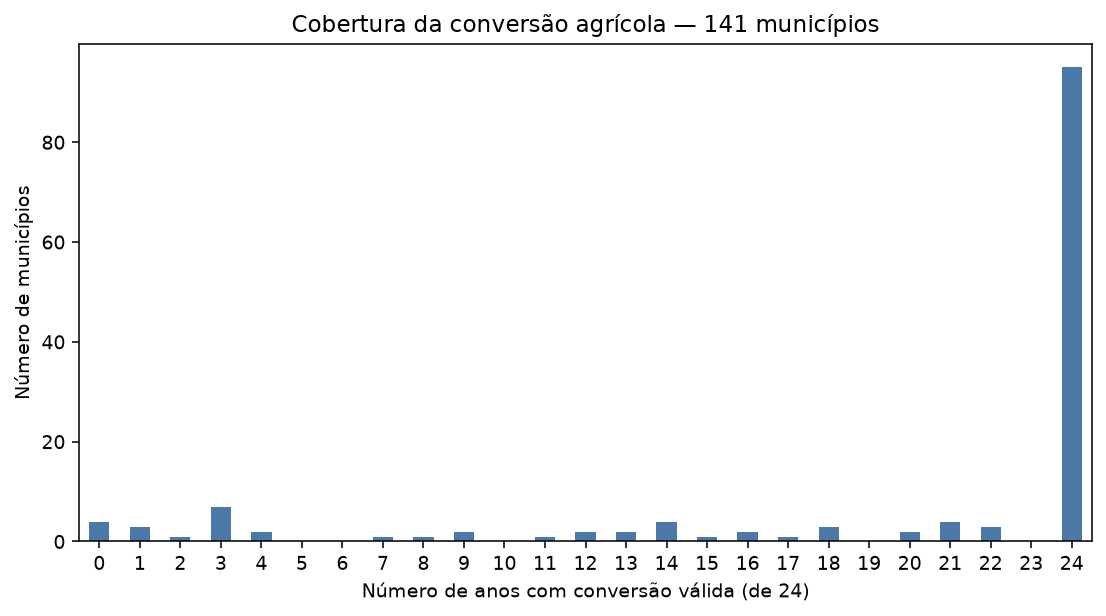

In [89]:
plt.figure(figsize=(8, 4.5), dpi=140)
frequencia_2a.plot.bar(color="#4c78a8")
plt.xlabel("Número de anos com conversão válida (de 24)")
plt.ylabel("Número de municípios")
plt.title(f"Cobertura da conversão agrícola — {len(df2a)} municípios")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [90]:
taxas_grafico_2a = completos_2a[["taxa_agricultura_ponderada_pct", "taxa_pastagem_ponderada_pct"]].copy()
taxas_grafico_2a.columns = ["Agricultura", "Pastagem"]


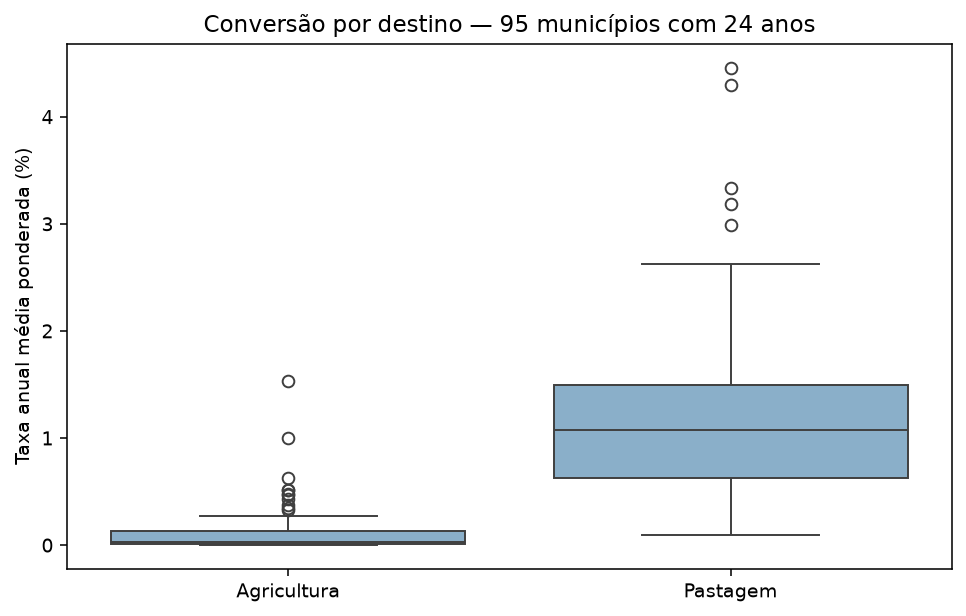

In [91]:
plt.figure(figsize=(7, 4.5), dpi=140)
sns.boxplot(data=taxas_grafico_2a, color="#80b1d3")
plt.ylabel("Taxa anual média ponderada (%)")
plt.title(f"Conversão por destino — {len(completos_2a)} municípios com 24 anos")
plt.tight_layout()
plt.show()


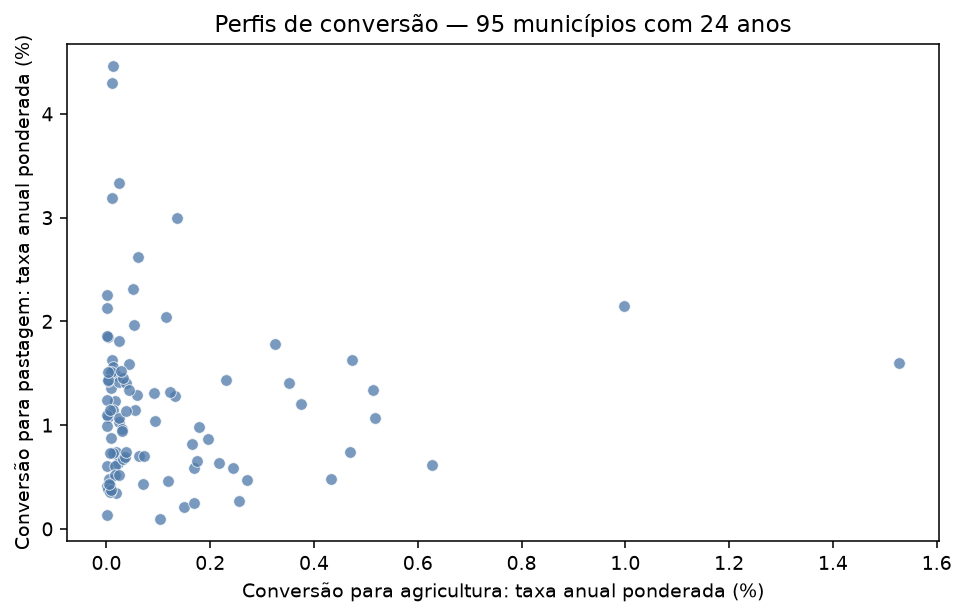

In [92]:
plt.figure(figsize=(7, 4.5), dpi=140)
sns.scatterplot(data=completos_2a, x="taxa_agricultura_ponderada_pct", y="taxa_pastagem_ponderada_pct", color="#4c78a8", alpha=0.75)
plt.xlabel("Conversão para agricultura: taxa anual ponderada (%)")
plt.ylabel("Conversão para pastagem: taxa anual ponderada (%)")
plt.title(f"Perfis de conversão — {len(completos_2a)} municípios com 24 anos")
plt.tight_layout()
plt.show()


Cada ponto representa um município. A dispersão descreve a composição das taxas médias por destino; não identifica substituição causal entre agricultura e pastagem. Os dois destinos são conversões diretas de vegetação nativa.


In [93]:
# Estoques defasados: datas efetivas 2000 e 2023, sem deslocamento implícito para 2024.
df2a[["nativa_inicio_ha_2000", "nativa_inicio_ha_2023", "nativa_inicio_ha_mudanca_2000_2023", "bovinos_2001", "bovinos_2024"]].describe().T


,count,mean,std,min,25%,50%,75%,max
nativa_inicio_ha_2000,117.0,422159.092121,507987.074403,8634.778290,113944.317489,282228.411602,438062.293564,2.737509e+06
nativa_inicio_ha_2023,136.0,371293.961759,451196.555317,6485.419932,89921.140733,226381.214575,395572.689422,2.210134e+06
nativa_inicio_ha_mudanca_2000_2023,116.0,-66647.708733,79166.829129,-532745.698994,-88333.151731,-42369.218221,-11157.228150,2.922997e+03
bovinos_2001,139.0,143320.971223,135721.767754,4115.000000,52731.500000,105000.000000,192539.500000,7.407760e+05
bovinos_2024,141.0,233002.609929,219645.140656,15000.000000,93747.000000,149344.000000,323335.000000,1.365224e+06


### 2. DATAFRAMES Y--X

Recortes do **df1 completo (PT)** conforme as colunas relacionadas no catálogo `paineis/variaveis_por_candidato_pt-gm_chap1.md`. Cada DataFrame mantém as chaves `codigo_ibge` e `ano`, as linhas município–ano, os tipos e as ausências de `df1`. Incluem-se vínculos principais, secundários e diagnósticos. Os nomes originais ficam nos títulos; os identificadores Python usam underscores no lugar dos hífens.

A seleção organiza as medidas disponíveis; não altera fórmulas, agrega observações ou define a especificação do modelo.

In [94]:
chaves_yx = ["codigo_ibge", "ano"]
assert not df1.duplicated(chaves_yx).any(), "Chave município–ano duplicada em df1."

#### 2.1 Y_conv (Conversão de vegetação nativa)

##### --- (a) Y_conv ---

Identificador Python: `Y_conv`. 15 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [ ]:
# Y_conv = conversão bruta de vegetação nativa para agricultura e pastagem, ha, municipal, anual*

###### Criar

In [95]:
# Recorte fiel, preservando a base

In [96]:
Y_conv = df1.loc[:, chaves_yx + [
    'conversao_ha__agricultura',
    'conversao_ha__pastagem',
    'taxa_conversao__agricultura',
    'taxa_conversao__pastagem',
    'y_colecao',
    'y_malha',
    'y_mascara_id',
    'y_area_total_ha',
    'y_area_valida_par_ha',
    'y_area_nao_valida_par_ha',
    'y_nativa_inicial_ha',
    'y_cobertura_completa',
    'y_fracao_area_valida_par',
    'y_flag_denominador_zero',
    'y_flag_denominador_ausente',
]].copy()
Y_conv.head()

,codigo_ibge,ano,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,y_colecao,y_malha,y_mascara_id,y_area_total_ha,y_area_valida_par_ha,y_area_nao_valida_par_ha,y_nativa_inicial_ha,y_cobertura_completa,y_fracao_area_valida_par,y_flag_denominador_zero,y_flag_denominador_ausente
0,5100102,2001,5.093917,1030.491067,0.000086,0.017323,10.1,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,85075.640222,85075.640222,0.0,59486.295731,True,1.0,False,False
1,5100102,2002,1.468305,693.661899,0.000025,0.011781,10.1,IBGE_MT_2023_141,5807cd2f641779260fa4559cbed36ba1758c805727c9ac...,85075.640222,85075.640222,0.0,58878.434055,True,1.0,False,False
2,5100102,2003,0.172670,791.607567,0.000003,0.013461,10.1,IBGE_MT_2023_141,87e1efe7cc9af76935236018b19355ab089f5ed333ff2c...,85075.640222,85075.640222,0.0,58805.484389,True,1.0,False,False
3,5100102,2004,0.000000,778.872226,0.000000,0.013255,10.1,IBGE_MT_2023_141,cb73fabdf74ffdec0a72c86f9512fbb2b3ec6eebb880fc...,85075.640222,85075.640222,0.0,58759.069254,True,1.0,False,False
4,5100102,2005,1.208967,615.813542,0.000021,0.010526,10.1,IBGE_MT_2023_141,9b9c3f1ac4a2aaa976d1f8022532f78a75bd38db951809...,85075.640222,85075.640222,0.0,58501.389359,True,1.0,False,False


In [97]:
Y_conv.columns.tolist()

['codigo_ibge',
 'ano',
 'conversao_ha__agricultura',
 'conversao_ha__pastagem',
 'taxa_conversao__agricultura',
 'taxa_conversao__pastagem',
 'y_colecao',
 'y_malha',
 'y_mascara_id',
 'y_area_total_ha',
 'y_area_valida_par_ha',
 'y_area_nao_valida_par_ha',
 'y_nativa_inicial_ha',
 'y_cobertura_completa',
 'y_fracao_area_valida_par',
 'y_flag_denominador_zero',
 'y_flag_denominador_ausente']

In [98]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#3 - conversao_ha__agricultura: Vegetação nativa em t−1 convertida em agricultura em t (MapBiomas) | ha | municipal (MT), anual.

#4 - conversao_ha__pastagem: Vegetação nativa em t−1 convertida em pastagem em t (MapBiomas) | ha | municipal (MT), anual.

#5 - taxa_conversao__agricultura: Conversão para agricultura / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#6 - taxa_conversao__pastagem: Conversão para pastagem / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#7 - y_colecao: Versão da coleção MapBiomas usada em Y (10.1) | categoria | referência comum ao painel municipal de MT.

#8 - y_malha: Referência territorial usada em Y (IBGE MT 2023, 141 municípios) | identificador textual | referência comum ao painel municipal de MT.

#9 - y_mascara_id: Identificador da máscara espacial usada nas transições de Y | hash textual | municipal (MT), anual.

#10 - y_area_total_ha: Área total da máscara municipal usada em Y | ha | municipal (MT), anual.

#11 - y_area_valida_par_ha: Área com classificação válida nos dois mapas (t−1 e t) | ha | municipal (MT), anual.

#12 - y_area_nao_valida_par_ha: Área sem classificação válida em pelo menos um dos dois mapas | ha | municipal (MT), anual.

#13 - y_nativa_inicial_ha: Vegetação nativa em t−1 na máscara das transições; denominador de Y | ha | municipal (MT), anual.

#14 - y_cobertura_completa: Indica cobertura completa do par de mapas usado em Y | booleano (True/False) | municipal (MT), anual.

#15 - y_fracao_area_valida_par: Área válida nos dois mapas / área total da máscara de Y | proporção (0–1) | municipal (MT), anual.

#16 - y_flag_denominador_zero: Indica vegetação nativa inicial de Y igual a zero | booleano (True/False) | municipal (MT), anual.

#17 - y_flag_denominador_ausente: Indica ausência do denominador de Y | booleano (True/False) | municipal (MT), anual.


###### Estrutura

In [99]:
# Dimensões, tipos, chaves e domínios

In [100]:
Y_conv.shape

(3384, 17)

In [101]:
Y_conv.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype        
---  ------                       --------------  -----        
 0   codigo_ibge                  3384 non-null   category     
 1   ano                          3384 non-null   period[Y-DEC]
 2   conversao_ha__agricultura    2772 non-null   float64      
 3   conversao_ha__pastagem       2772 non-null   float64      
 4   taxa_conversao__agricultura  2772 non-null   float64      
 5   taxa_conversao__pastagem     2772 non-null   float64      
 6   y_colecao                    3384 non-null   float64      
 7   y_malha                      3384 non-null   str          
 8   y_mascara_id                 3384 non-null   str          
 9   y_area_total_ha              3384 non-null   float64      
 10  y_area_valida_par_ha         3384 non-null   float64      
 11  y_area_nao_valida_par_ha     3384 non-null   float64      
 12  y_n

###### Qualidade dos dados

In [102]:
# Ausências, zeros, flags e suporte territorial/temporal

In [103]:
# Contar valores ausentes (NaN / None) por coluna
Y_conv.isna().sum()

codigo_ibge                      0
ano                              0
conversao_ha__agricultura      612
conversao_ha__pastagem         612
taxa_conversao__agricultura    612
taxa_conversao__pastagem       612
y_colecao                        0
y_malha                          0
y_mascara_id                     0
y_area_total_ha                  0
y_area_valida_par_ha             0
y_area_nao_valida_par_ha         0
y_nativa_inicial_ha              0
y_cobertura_completa             0
y_fracao_area_valida_par         0
y_flag_denominador_zero          0
y_flag_denominador_ausente       0
dtype: int64

In [104]:
# Contar zeros numéricos (0 ou 0.0) por coluna
(Y_conv == 0).sum()

codigo_ibge                       0
ano                               0
conversao_ha__agricultura       265
conversao_ha__pastagem            0
taxa_conversao__agricultura     265
taxa_conversao__pastagem          0
y_colecao                         0
y_malha                           0
y_mascara_id                      0
y_area_total_ha                   0
y_area_valida_par_ha              0
y_area_nao_valida_par_ha       2772
y_nativa_inicial_ha               0
y_cobertura_completa            612
y_fracao_area_valida_par          0
y_flag_denominador_zero        3384
y_flag_denominador_ausente     3384
dtype: int64

In [105]:
(3384)-(612)

#  2   conversao_ha__agricultura    2772 non-null   float64      
#  3   conversao_ha__pastagem       2772 non-null   float64      
#  4   taxa_conversao__agricultura  2772 non-null   float64      
#  5   taxa_conversao__pastagem     2772 non-null   float64 

# Valores 0 são válidos, mas não são ausentes. A contagem de valores ausentes é de 612, o que significa que há 612 registros com valores nulos (NaN) nessas colunas.

2772

In [106]:
# Valores duplicados

In [107]:
Y_conv.duplicated().sum()

np.int64(0)

###### Descritiva

In [108]:
# Descritiva inicial. Resumos apropriados ao papel e à unidade da coluna.

In [109]:
# Estatísticas descritivas dos dados quantitativos (considera os valores 0 nos cálculos e ignora os NaN).
Y_conv.describe().T

,count,mean,std,min,25%,50%,75%,max
conversao_ha__agricultura,2772.0,297.697312,1.015382e+03,0.000000,3.114156,26.987478,173.347514,1.822227e+04
conversao_ha__pastagem,2772.0,3257.588132,4.832176e+03,0.953154,579.761195,1644.679448,3769.385707,5.698323e+04
taxa_conversao__agricultura,2772.0,0.001122,3.750688e-03,0.000000,0.000018,0.000143,0.000761,7.995015e-02
taxa_conversao__pastagem,2772.0,0.011915,1.429543e-02,0.000029,0.004291,0.007994,0.014125,2.654108e-01
y_colecao,3384.0,10.100000,1.776619e-15,10.100000,10.100000,10.100000,10.100000,1.010000e+01
y_area_total_ha,3384.0,640572.702137,5.966349e+05,34432.115967,229129.505382,452527.754377,843902.909442,2.796089e+06
y_area_valida_par_ha,3384.0,640538.845979,5.965491e+05,34432.115967,229129.505382,452527.754377,843902.909442,2.796089e+06
y_area_nao_valida_par_ha,3384.0,33.856158,2.802481e+02,0.000000,0.000000,0.000000,0.000000,3.152443e+03
y_nativa_inicial_ha,3384.0,416822.259062,4.956423e+05,6485.419932,100895.152377,250880.514449,438459.568205,2.737509e+06
y_fracao_area_valida_par,3384.0,0.999983,1.272582e-04,0.998713,1.000000,1.000000,1.000000,1.000000e+00


In [110]:
# Excluir valores ausentes e zeros para análise descritiva
Y_conv_limpo = Y_conv[Y_conv.notna() & (Y_conv != 0)]
Y_conv_limpo.describe().T

,count,mean,std,min,25%,50%,75%,max
conversao_ha__agricultura,2507.0,329.165118,1.062856e+03,1.048119e-02,6.723911,37.947104,212.478732,1.822227e+04
conversao_ha__pastagem,2772.0,3257.588132,4.832176e+03,9.531544e-01,579.761195,1644.679448,3769.385707,5.698323e+04
taxa_conversao__agricultura,2507.0,0.001241,3.925300e-03,1.221478e-07,0.000038,0.000198,0.000915,7.995015e-02
taxa_conversao__pastagem,2772.0,0.011915,1.429543e-02,2.906923e-05,0.004291,0.007994,0.014125,2.654108e-01
y_colecao,3384.0,10.100000,1.776619e-15,1.010000e+01,10.100000,10.100000,10.100000,1.010000e+01
y_area_total_ha,3384.0,640572.702137,5.966349e+05,3.443212e+04,229129.505382,452527.754377,843902.909442,2.796089e+06
y_area_valida_par_ha,3384.0,640538.845979,5.965491e+05,3.443212e+04,229129.505382,452527.754377,843902.909442,2.796089e+06
y_area_nao_valida_par_ha,612.0,187.204641,6.372614e+02,7.414286e-03,0.088025,0.263729,1.286044,3.152443e+03
y_nativa_inicial_ha,3384.0,416822.259062,4.956423e+05,6.485420e+03,100895.152377,250880.514449,438459.568205,2.737509e+06
y_fracao_area_valida_par,3384.0,0.999983,1.272582e-04,9.987133e-01,1.000000,1.000000,1.000000,1.000000e+00


In [111]:
# Estatísticas descritivas de variáveis não numéricas (qualitativas e temporais), ignorando NaN.
Y_conv.describe(exclude=['number']).T

,count,unique,top,freq
codigo_ibge,3384,141,5100102,24
ano,3384,24,2001,141
y_malha,3384,1,IBGE_MT_2023_141,3384
y_mascara_id,3384,3384,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,1
y_cobertura_completa,3384,2,True,2772
y_flag_denominador_zero,3384,1,False,3384
y_flag_denominador_ausente,3384,1,False,3384


###### Análise Univariada

In [112]:
# Aprofundamento posterior das distribuições e trajetórias

**1. Quais observações sustentam as distribuições?**

Esta leitura parte de `Y_conv`, preservando os zeros válidos e as ausências. A tabela anterior de `Y_conv_limpo` descreve valores positivos por coluna; não é a base destas análises. As quatro medidas substantivas são os dois fluxos em hectares e as duas taxas derivadas. Denominador e áreas apoiam sua interpretação; flags e metadados documentam qualidade e proveniência.

O painel completo e os perfis de cobertura já foram apresentados em `df1a`/`df2a`. Aqui se recupera apenas o suporte necessário às comparações. Percentuais das taxas são calculados em cópias de apresentação, sem alterar as proporções originais.


In [113]:
from IPython.display import display, Markdown

def yconv_mostrar(tabela, casas=3):
    # Formatação local: não muda opções de exibição das outras seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', None,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

yconv_aed = Y_conv.copy()
yconv_destinos = ['agricultura', 'pastagem']
yconv_rotulos = {'agricultura': 'Agricultura', 'pastagem': 'Pastagem'}
yconv_cores = {'agricultura': '#4c78a8', 'pastagem': '#e09136'}
yconv_fluxos = [f'conversao_ha__{d}' for d in yconv_destinos]
yconv_taxas = [f'taxa_conversao__{d}' for d in yconv_destinos]
yconv_medidas = yconv_fluxos + yconv_taxas
yconv_aed['ano'] = yconv_aed['ano'].dt.year

assert not yconv_aed.duplicated(['codigo_ibge', 'ano']).any()
assert not yconv_aed[['codigo_ibge', 'ano']].isna().any().any()
assert yconv_aed[yconv_medidas].isna().eq(yconv_aed[yconv_medidas[0]].isna(), axis=0).all().all()
assert yconv_aed[yconv_medidas[0]].isna().equals(~yconv_aed['y_cobertura_completa'])
yconv_validos = yconv_aed.dropna(subset=yconv_medidas).copy()
assert np.isfinite(yconv_validos[yconv_medidas].to_numpy()).all()
assert yconv_validos[yconv_fluxos].ge(0).all().all()
assert yconv_validos[yconv_taxas].ge(0).all().all() and yconv_validos[yconv_taxas].le(1).all().all()
assert yconv_validos['y_nativa_inicial_ha'].gt(0).all()
for destino in yconv_destinos:
    assert np.allclose(yconv_validos[f'taxa_conversao__{destino}'], yconv_validos[f'conversao_ha__{destino}'] / yconv_validos['y_nativa_inicial_ha'])
assert yconv_validos[yconv_fluxos].sum(axis=1).le(yconv_validos['y_nativa_inicial_ha'] + 1e-4).all()
assert np.allclose(yconv_aed['y_area_valida_par_ha'] + yconv_aed['y_area_nao_valida_par_ha'], yconv_aed['y_area_total_ha'], rtol=1e-8, atol=1e-4)

yconv_anos_grade = yconv_aed['ano'].nunique()
yconv_cobertura_mun = yconv_aed.groupby('codigo_ibge', observed=True)[yconv_medidas[0]].count()
assert yconv_aed.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(yconv_anos_grade).all()
yconv_municipios_completos = yconv_cobertura_mun.index[yconv_cobertura_mun.eq(yconv_anos_grade)]
yconv_completos = yconv_validos.loc[yconv_validos['codigo_ibge'].isin(yconv_municipios_completos)].copy()
yconv_suporte = pd.DataFrame({
    'Observações': [len(yconv_aed), len(yconv_validos), len(yconv_aed) - len(yconv_validos), len(yconv_completos)],
    'Municípios': [yconv_aed['codigo_ibge'].nunique(), yconv_validos['codigo_ibge'].nunique(), yconv_aed.loc[yconv_aed[yconv_medidas[0]].isna(), 'codigo_ibge'].nunique(), len(yconv_municipios_completos)],
    'Anos representados': [yconv_aed['ano'].nunique(), yconv_validos['ano'].nunique(), yconv_aed.loc[yconv_aed[yconv_medidas[0]].isna(), 'ano'].nunique(), yconv_completos['ano'].nunique()]
}, index=['Grade', 'Y observado', 'Y ausente', 'Janela completa por município'])
display(yconv_suporte)
display(Markdown(f"As quatro medidas têm **{len(yconv_validos):,} pares válidos** e **{len(yconv_aed) - len(yconv_validos):,} ausentes** ({100 * (1 - len(yconv_validos) / len(yconv_aed)):.2f}% da grade). Há **{len(yconv_municipios_completos)} municípios completos**, **{yconv_cobertura_mun.between(1, yconv_anos_grade - 1).sum()} parciais** e **{yconv_cobertura_mun.eq(0).sum()} sem Y observado**. A janela completa é usada apenas nas comparações que exigem os mesmos municípios ao longo do tempo."))


,Observações,Municípios,Anos representados
Grade,3384,141,24
Y observado,2772,137,24
Y ausente,612,46,24
Janela completa por município,2280,95,24


As quatro medidas têm **2,772 pares válidos** e **612 ausentes** (18.09% da grade). Há **95 municípios completos**, **42 parciais** e **4 sem Y observado**. A janela completa é usada apenas nas comparações que exigem os mesmos municípios ao longo do tempo.

In [114]:
# False é um estado observado da flag; não é ausência nem zero de conversão.
yconv_flags = ['y_cobertura_completa', 'y_flag_denominador_zero', 'y_flag_denominador_ausente']
yconv_estados_flags = pd.DataFrame({
    'True': [int(yconv_aed[c].eq(True).sum()) for c in yconv_flags],
    'False': [int(yconv_aed[c].eq(False).sum()) for c in yconv_flags],
    'Ausente': [int(yconv_aed[c].isna().sum()) for c in yconv_flags]
}, index=yconv_flags)
display(yconv_estados_flags)
display(pd.DataFrame({
    'Valores distintos': [yconv_aed[c].nunique() for c in ['y_colecao', 'y_malha', 'y_mascara_id']],
    'Interpretação': [str(yconv_aed['y_colecao'].unique().tolist()), ', '.join(yconv_aed['y_malha'].unique()), 'Identificador do município e par de mapas; não é uma medida de conversão.']
}, index=['y_colecao', 'y_malha', 'y_mascara_id']))


,True,False,Ausente
y_cobertura_completa,2772,612,0
y_flag_denominador_zero,0,3384,0
y_flag_denominador_ausente,0,3384,0


,Valores distintos,Interpretação
y_colecao,1,[10.1]
y_malha,1,IBGE_MT_2023_141
y_mascara_id,3384,Identificador do município e par de mapas; não...


As ausências de Y coincidem com cobertura incompleta, embora o denominador esteja preenchido. As duas flags de denominador são falsas no painel atual. Os hashes distintos identificam os pares espaciais/temporais; não significam malhas territoriais diferentes. Coleção, malha e flags não entram como medidas quantitativas nas distribuições abaixo.


**2. Onde se concentram os valores e quão longas são as caudas?**

Além da descritiva anterior, observam-se zeros, quantis superiores, IQR e assimetria. Cada linha é uma medida; a unidade está no rótulo. Os N referem-se a pares município–ano, não a observações independentes para inferência.


In [115]:
yconv_distribuicao = []
for destino in yconv_destinos:
    for prefixo, escala, unidade in [('conversao_ha', 1, 'ha'), ('taxa_conversao', 100, '%')]:
        serie = yconv_aed[f'{prefixo}__{destino}'].dropna() * escala
        yconv_distribuicao.append({
            'Medida': f'{yconv_rotulos[destino]} ({unidade})', 'N': len(serie),
            'Zeros': int(serie.eq(0).sum()), 'Zeros / válidos (%)': 100 * serie.eq(0).mean(),
            'Média': serie.mean(), 'Mediana': serie.median(),
            'IQR': serie.quantile(.75) - serie.quantile(.25),
            'P95': serie.quantile(.95), 'P99': serie.quantile(.99),
            'Máximo': serie.max(), 'Assimetria': serie.skew()
        })
yconv_distribuicao = pd.DataFrame(yconv_distribuicao).set_index('Medida')
yconv_mostrar(yconv_distribuicao[['N', 'Zeros', 'Zeros / válidos (%)']])
yconv_mostrar(yconv_distribuicao.drop(columns=['N', 'Zeros', 'Zeros / válidos (%)']))


,N,Zeros,Zeros / válidos (%)
Medida,,,
Agricultura (ha),2772,265,9.560
Agricultura (%),2772,265,9.560
Pastagem (ha),2772,0,0.000
Pastagem (%),2772,0,0.000


,Média,Mediana,IQR,P95,P99,Máximo,Assimetria
Medida,,,,,,,
Agricultura (ha),297.697,26.987,170.233,"1,244.557","5,273.086","18,222.268",8.080
Agricultura (%),0.112,0.014,0.074,0.473,1.722,7.995,10.051
Pastagem (ha),"3,257.588","1,644.679","3,189.625","12,000.873","24,037.665","56,983.225",3.852
Pastagem (%),1.192,0.799,0.983,3.609,6.362,26.541,5.948


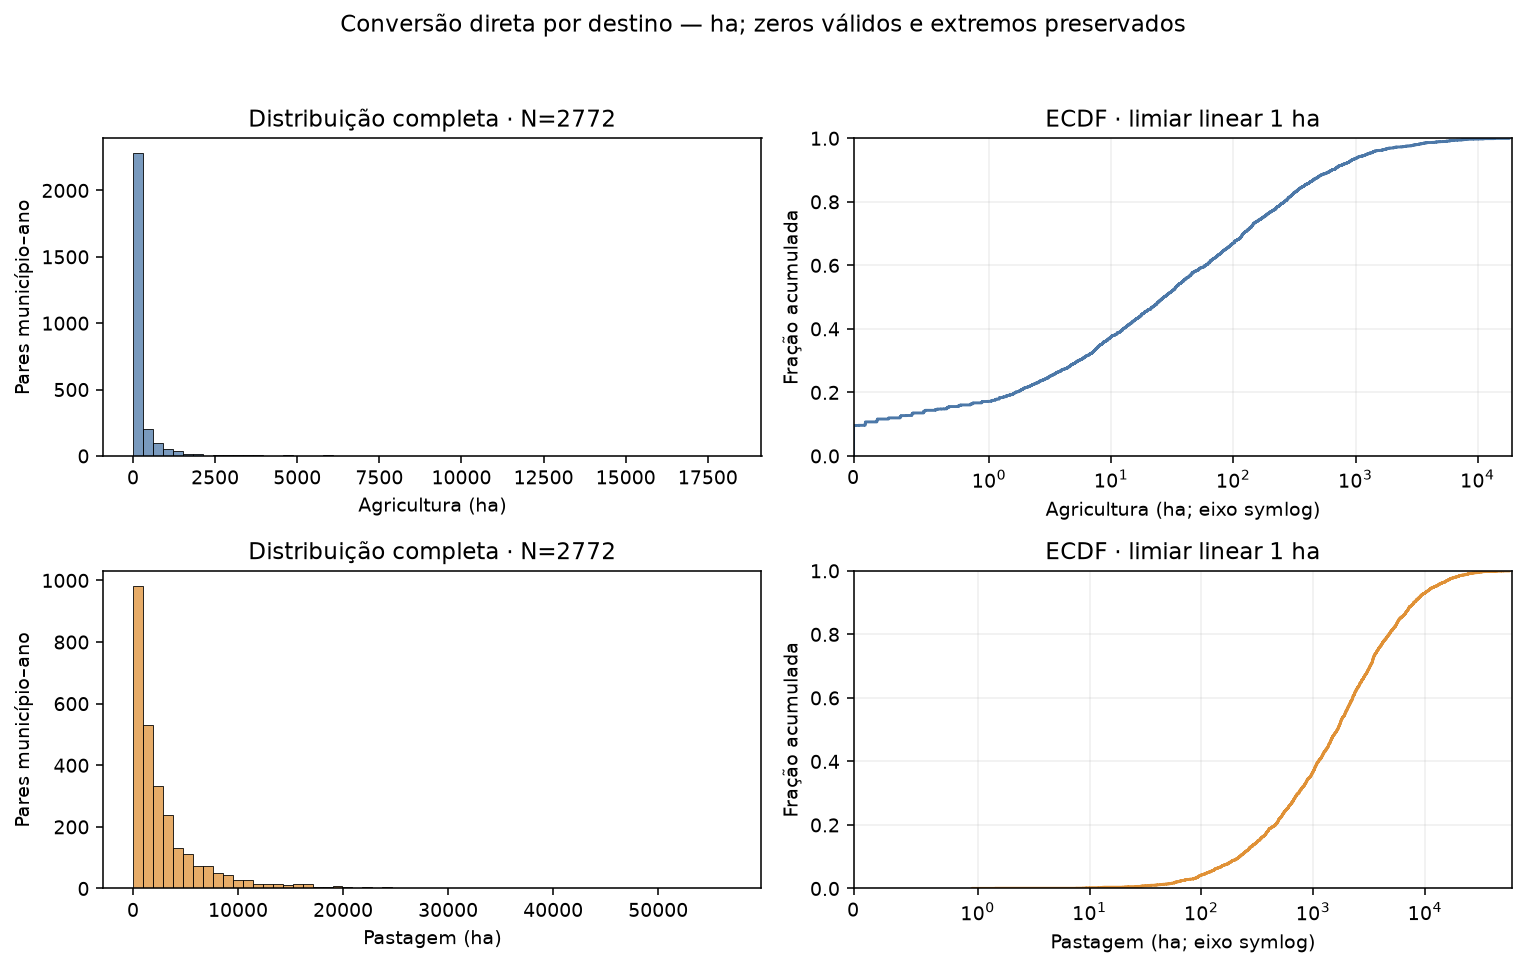

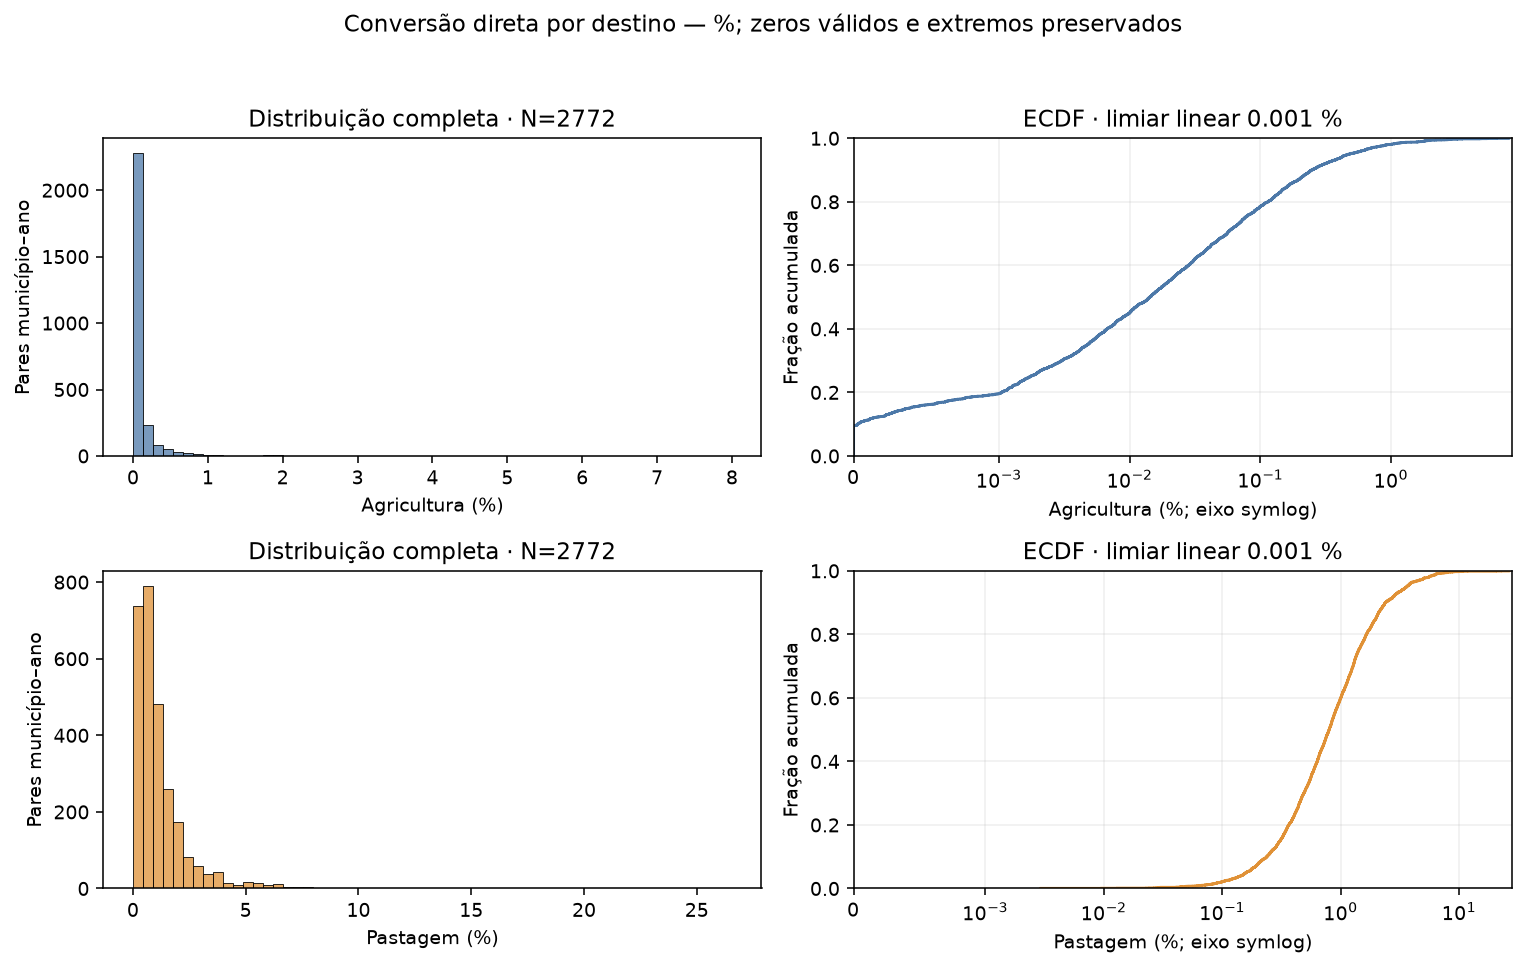

In [116]:
# Histogramas em escala original; ECDF com eixo symlog para mostrar zero e cauda.
for prefixo, escala, unidade, limiar in [('conversao_ha', 1, 'ha', 1), ('taxa_conversao', 100, '%', .001)]:
    fig, eixos = plt.subplots(2, 2, figsize=(11, 7), dpi=140)
    for linha, destino in enumerate(yconv_destinos):
        valores = yconv_aed[f'{prefixo}__{destino}'].dropna() * escala
        cor = yconv_cores[destino]
        bins = min(60, max(10, len(np.histogram_bin_edges(valores, bins='fd')) - 1))
        sns.histplot(x=valores, bins=bins, color=cor, ax=eixos[linha, 0])
        eixos[linha, 0].set(xlabel=f'{yconv_rotulos[destino]} ({unidade})', ylabel='Pares município–ano', title=f'Distribuição completa · N={len(valores)}')
        sns.ecdfplot(x=valores, color=cor, ax=eixos[linha, 1])
        eixos[linha, 1].set_xscale('symlog', linthresh=limiar)
        eixos[linha, 1].set_xlim(0, valores.max() * 1.05)
        eixos[linha, 1].set_ylim(0, 1)
        eixos[linha, 1].set(xlabel=f'{yconv_rotulos[destino]} ({unidade}; eixo symlog)', ylabel='Fração acumulada', title=f'ECDF · limiar linear {limiar:g} {unidade}')
        eixos[linha, 1].grid(alpha=.2)
    fig.suptitle(f'Conversão direta por destino — {unidade}; zeros válidos e extremos preservados', fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, .95))
    plt.show()


As duas distribuições têm cauda à direita. A média da taxa agrícola (aproximadamente 0,112%) supera bastante sua mediana (0,014%); para pastagem, são 1,192% e 0,799%. Os 265 zeros agrícolas representam cerca de 9,56% dos valores válidos; não há zeros de pastagem no suporte observado. A ausência de conversão agrícola não implica ausência de conversão para outro destino ou decisão ativa de conservação.

Os histogramas mantêm a escala original e toda a amplitude. A ECDF facilita examinar valores pequenos e extremos no mesmo painel: o eixo symlog tem trecho linear perto de zero e trecho logarítmico fora dele. Isso modifica apenas a apresentação. Média, mediana e quantis devem ser lidos conjuntamente; os extremos foram mantidos e não são classificados como erros apenas por serem altos.


**3. Os maiores fluxos e as maiores taxas aparecem nos mesmos pares?**

A tabela localiza os cinco maiores valores de cada medida, com código municipal, ano, hectares, taxa e vegetação nativa inicial. Serve à investigação dos extremos; não é ranking de efeito econômico.


In [117]:
yconv_extremos = []
for destino in yconv_destinos:
    for coluna, criterio in [(f'conversao_ha__{destino}', 'Maior fluxo (ha)'), (f'taxa_conversao__{destino}', 'Maior taxa')]:
        maiores = yconv_validos.nlargest(5, coluna)
        for _, linha in maiores.iterrows():
            yconv_extremos.append({'Destino': yconv_rotulos[destino], 'Critério': criterio,
                'Código IBGE': str(linha['codigo_ibge']), 'Ano': int(linha['ano']),
                'Conversão (ha)': linha[f'conversao_ha__{destino}'],
                'Taxa (%)': 100 * linha[f'taxa_conversao__{destino}'],
                'Nativa inicial (ha)': linha['y_nativa_inicial_ha']})
yconv_extremos = pd.DataFrame(yconv_extremos)
yconv_mostrar(yconv_extremos, casas=4)


,Destino,Critério,Código IBGE,Ano,Conversão (ha),Taxa (%),Nativa inicial (ha)
0,Agricultura,Maior fluxo (ha),5107941,2003,"18,222.2681",2.8221,"645,710.2070"
1,Agricultura,Maior fluxo (ha),5104526,2003,"13,675.0671",7.9950,"171,044.9270"
2,Agricultura,Maior fluxo (ha),5106802,2003,"13,619.8099",2.6747,"509,202.1164"
3,Agricultura,Maior fluxo (ha),5108501,2003,"11,293.8233",6.4141,"176,077.7452"
4,Agricultura,Maior fluxo (ha),5104526,2001,"11,256.2296",5.4202,"207,673.4242"
5,Agricultura,Maior taxa,5104526,2003,"13,675.0671",7.9950,"171,044.9270"
6,Agricultura,Maior taxa,5108501,2003,"11,293.8233",6.4141,"176,077.7452"
7,Agricultura,Maior taxa,5104526,2001,"11,256.2296",5.4202,"207,673.4242"
8,Agricultura,Maior taxa,5104526,2004,"7,283.9551",4.8755,"149,399.1393"
9,Agricultura,Maior taxa,5108501,2004,"7,287.6164",4.7271,"154,165.6257"


Os máximos de hectares e de taxa pertencem a pares diferentes em ambos os destinos. Por exemplo, a maior taxa de pastagem é aproximadamente 26,54% (5106232, 2022), enquanto o maior fluxo é aproximadamente 56.983 ha (5103254, 2004). Volume convertido e fração da vegetação disponível respondem a perguntas diferentes. Esses pares merecem conferência de fonte e trajetória antes de qualquer tratamento de extremos.


**4. Como a conversão evolui quando os municípios comparados são os mesmos?**

Usam-se os municípios com Y observado em todos os anos da grade, como nas figuras de janela comum de `df1a`/`df2a`. As taxas são médias e medianas municipais de cada ano, com peso igual por município. As somas de hectares são observadas nessa seleção e não representam o total de Mato Grosso.


In [118]:
yconv_anual = yconv_completos.groupby('ano').agg(
    municipios=('codigo_ibge', 'nunique'),
    agricultura_ha=('conversao_ha__agricultura', 'sum'),
    pastagem_ha=('conversao_ha__pastagem', 'sum'),
    agricultura_media=('taxa_conversao__agricultura', 'mean'),
    agricultura_mediana=('taxa_conversao__agricultura', 'median'),
    pastagem_media=('taxa_conversao__pastagem', 'mean'),
    pastagem_mediana=('taxa_conversao__pastagem', 'median')
)
yconv_anual_pct = yconv_anual.copy()
yconv_anual_pct[yconv_anual_pct.filter(regex='media|mediana').columns] *= 100
yconv_mostrar(yconv_anual_pct.rename(columns={'municipios': 'Municípios', 'agricultura_ha': 'Agricultura (ha)', 'pastagem_ha': 'Pastagem (ha)', 'agricultura_media': 'Agricultura: média (%)', 'agricultura_mediana': 'Agricultura: mediana (%)', 'pastagem_media': 'Pastagem: média (%)', 'pastagem_mediana': 'Pastagem: mediana (%)'}))


,Municípios,Agricultura (ha),Pastagem (ha),Agricultura: média (%),Agricultura: mediana (%),Pastagem: média (%),Pastagem: mediana (%)
ano,,,,,,,
2001,95,"51,074.401","338,419.344",0.188,0.008,1.769,1.226
2002,95,"41,331.032","433,899.816",0.161,0.013,1.890,1.337
2003,95,"104,327.476","543,749.323",0.428,0.030,2.391,1.965
2004,95,"95,172.659","510,264.858",0.422,0.037,2.096,1.604
2005,95,"54,259.990","421,859.027",0.256,0.048,1.812,1.420
2006,95,"23,802.954","302,316.946",0.098,0.023,1.165,0.926
2007,95,"8,408.392","218,310.127",0.055,0.016,1.013,0.817
2008,95,"13,276.805","221,013.157",0.067,0.014,1.053,0.858
2009,95,"8,976.670","139,198.752",0.050,0.008,0.880,0.522


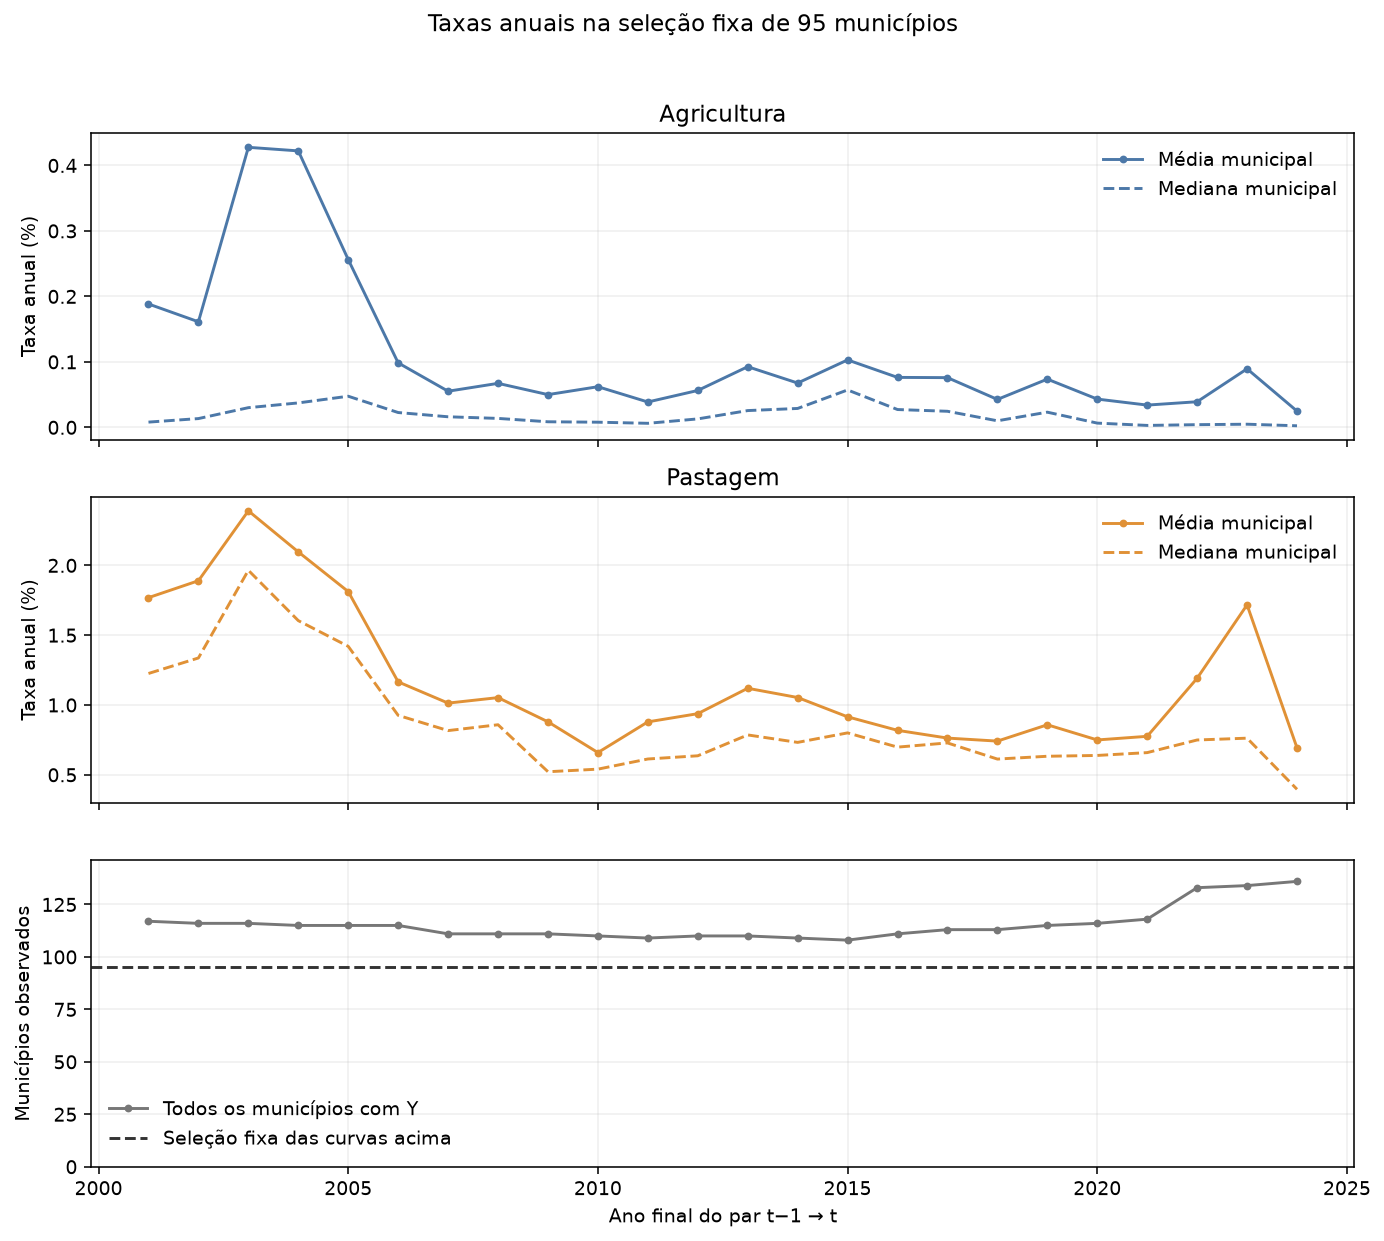

In [119]:
fig, eixos = plt.subplots(3, 1, figsize=(10, 9), dpi=140, sharex=True)
for eixo, destino in zip(eixos[:2], yconv_destinos):
    eixo.plot(yconv_anual_pct.index, yconv_anual_pct[f'{destino}_media'], color=yconv_cores[destino], label='Média municipal', marker='o', markersize=3)
    eixo.plot(yconv_anual_pct.index, yconv_anual_pct[f'{destino}_mediana'], color=yconv_cores[destino], label='Mediana municipal', linestyle='--')
    eixo.set(ylabel='Taxa anual (%)', title=yconv_rotulos[destino])
    eixo.legend(frameon=False)
    eixo.grid(alpha=.2)
yconv_cobertura_anual = yconv_validos.groupby('ano')['codigo_ibge'].nunique()
eixos[2].plot(yconv_cobertura_anual.index, yconv_cobertura_anual, color='#777777', label='Todos os municípios com Y', marker='o', markersize=3)
eixos[2].axhline(len(yconv_municipios_completos), color='#333333', linestyle='--', label='Seleção fixa das curvas acima')
eixos[2].set(xlabel='Ano final do par t−1 → t', ylabel='Municípios observados', ylim=(0, yconv_aed['codigo_ibge'].nunique() + 5))
eixos[2].legend(frameon=False)
eixos[2].grid(alpha=.2)
fig.suptitle(f'Taxas anuais na seleção fixa de {len(yconv_municipios_completos)} municípios', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, .96))
plt.show()


Na seleção fixa, as médias de ambos os destinos atingem seu máximo em 2003. Em 2024, são menores que em 2001, mas as trajetórias não são monotônicas. Essa comparação evita que a entrada de municípios na amostra observada determine a mudança das curvas; continua, contudo, condicionada à seleção dos municípios completos.

As médias das taxas não equivalem à razão entre a soma dos fluxos e a soma da vegetação inicial. Tampouco são percentuais acumulados de perda. As curvas descrevem conversão observada e não identificam o papel de preços, capacidade produtiva ou instituições.


###### Análise Multivariada

In [120]:
# Relações previstas em H1 e cobertura conjunta das medidas

**1. Como os dois destinos se relacionam em hectares e em taxas?**

Esta etapa examina relações internas de `Y_conv`. As dispersões são bivariadas; a estratificação posterior acrescenta tamanho territorial e tempo. Não há estimação dos determinantes de H1. Usam-se pares observados nos dois destinos, sem excluir zeros nem exigir completude em colunas externas ao bloco.


,Pares município–ano,Municípios,Primeiro ano,Último ano
Dispersões gerais e denominador,2772,137,2001,2024
Estratificação e comparação entre níveis,2280,95,2001,2024


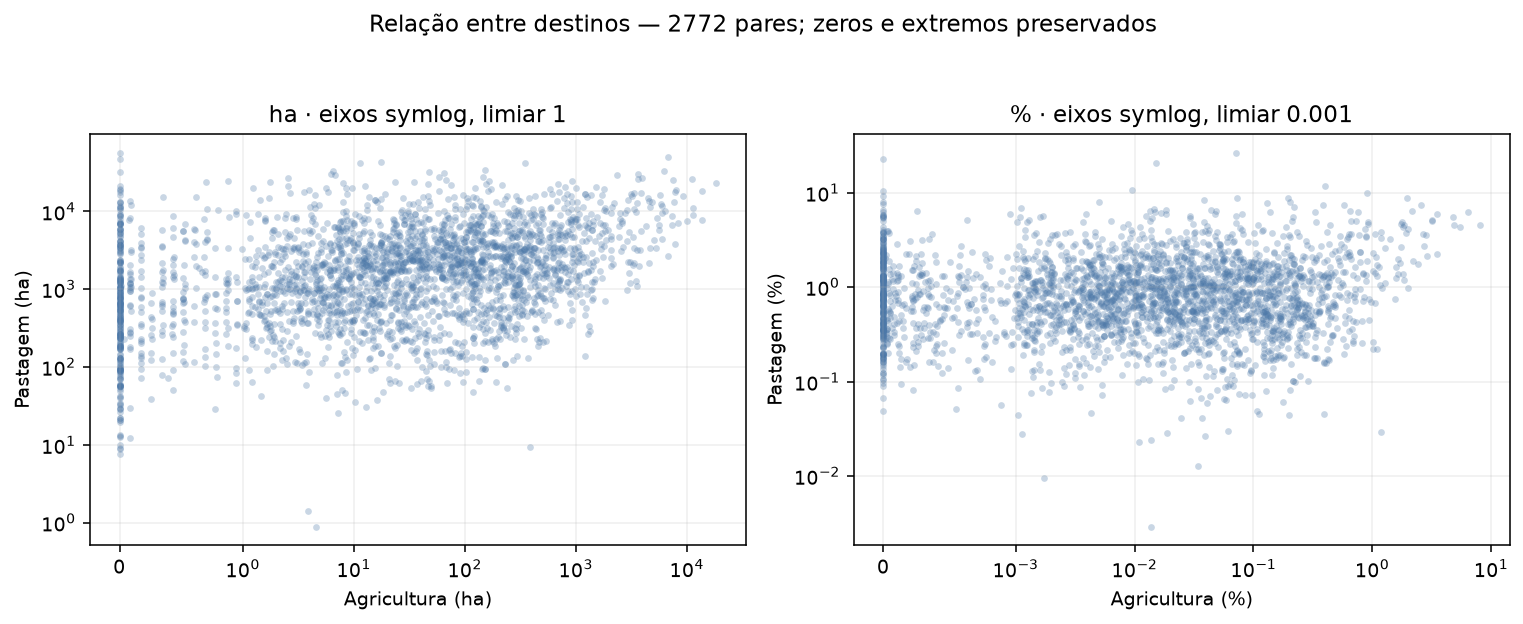

In [121]:
yconv_pares = yconv_validos.copy()
yconv_suporte_relacoes = pd.DataFrame({
    'Pares município–ano': [len(yconv_pares), len(yconv_completos)],
    'Municípios': [yconv_pares['codigo_ibge'].nunique(), yconv_completos['codigo_ibge'].nunique()],
    'Primeiro ano': [yconv_pares['ano'].min(), yconv_completos['ano'].min()],
    'Último ano': [yconv_pares['ano'].max(), yconv_completos['ano'].max()]
}, index=['Dispersões gerais e denominador', 'Estratificação e comparação entre níveis'])
display(yconv_suporte_relacoes)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5), dpi=140)
for eixo, prefixo, escala, unidade, limiar in zip(eixos, ['conversao_ha', 'taxa_conversao'], [1, 100], ['ha', '%'], [1, .001]):
    eixo.scatter(yconv_pares[f'{prefixo}__agricultura'] * escala, yconv_pares[f'{prefixo}__pastagem'] * escala, s=12, alpha=.3, color='#4c78a8', linewidths=0)
    eixo.set_xscale('symlog', linthresh=limiar)
    eixo.set_yscale('symlog', linthresh=limiar)
    eixo.set(xlabel=f'Agricultura ({unidade})', ylabel=f'Pastagem ({unidade})', title=f'{unidade} · eixos symlog, limiar {limiar:g}')
    eixo.grid(alpha=.2)
fig.suptitle(f'Relação entre destinos — {len(yconv_pares)} pares; zeros e extremos preservados', fontsize=12)
fig.tight_layout(rect=(0, 0, 1, .94))
plt.show()


O contraste entre os painéis distingue escala física e intensidade relativa. Em hectares, municípios com mais vegetação disponível podem apresentar fluxos maiores em ambos os destinos. Nas taxas, os dois numeradores compartilham o mesmo denominador. Assim, uma associação entre destinos não demonstra substituição, competição ou mecanismo econômico independente. O eixo symlog conserva os zeros; distâncias visuais não representam incrementos lineares em toda a escala.


**2. A relação muda quando distinguimos tamanho territorial e ano?**

Nos municípios completos, confere-se a constância numérica da área total no tempo (tolerância absoluta de 0,000001 ha). A área do primeiro ano da grade define quatro grupos fixos por quartis, somente para descrição. Q1 inclui o mínimo; os demais intervalos são abertos à esquerda e fechados à direita. Cada ponto é um par município–ano; a cor representa o ano. Os mesmos limites dos eixos permitem comparar os grupos. Área municipal e vegetação nativa disponível são conceitos distintos.


In [122]:
yconv_area_constante = yconv_completos.groupby('codigo_ibge', observed=True)['y_area_total_ha'].agg(['min', 'max'])
assert yconv_area_constante['max'].sub(yconv_area_constante['min']).le(1e-6).all()
yconv_area_mun = yconv_completos.loc[yconv_completos['ano'].eq(yconv_completos['ano'].min())].set_index('codigo_ibge')['y_area_total_ha']
yconv_grupo_area_mun, yconv_limites_area = pd.qcut(yconv_area_mun, 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], retbins=True)
yconv_contexto = yconv_completos.copy()
yconv_contexto['Quartil de área municipal'] = yconv_contexto['codigo_ibge'].map(yconv_grupo_area_mun).astype('category')
yconv_grupos_area = yconv_contexto.groupby('Quartil de área municipal', observed=True).agg(
    municipios=('codigo_ibge', 'nunique'), pares=('ano', 'size'),
    agricultura_mediana=('taxa_conversao__agricultura', 'median'),
    pastagem_mediana=('taxa_conversao__pastagem', 'median')
)
yconv_grupos_area['Área: limite inferior (ha)'] = yconv_limites_area[:-1]
yconv_grupos_area['Área: limite superior (ha)'] = yconv_limites_area[1:]
yconv_grupos_area[['agricultura_mediana', 'pastagem_mediana']] *= 100
yconv_mostrar(yconv_grupos_area.rename(columns={'municipios': 'Municípios', 'pares': 'Pares', 'agricultura_mediana': 'Mediana agricultura (%)', 'pastagem_mediana': 'Mediana pastagem (%)'}))


,Municípios,Pares,Mediana agricultura (%),Mediana pastagem (%),Área: limite inferior (ha),Área: limite superior (ha)
Quartil de área municipal,,,,,,
Q1,24,576,0.006,1.056,"34,432.116","187,471.926"
Q2,24,576,0.019,0.756,"187,471.926","384,165.385"
Q3,23,552,0.017,0.828,"384,165.385","555,780.505"
Q4,24,576,0.012,0.622,"555,780.505","2,796,089.259"


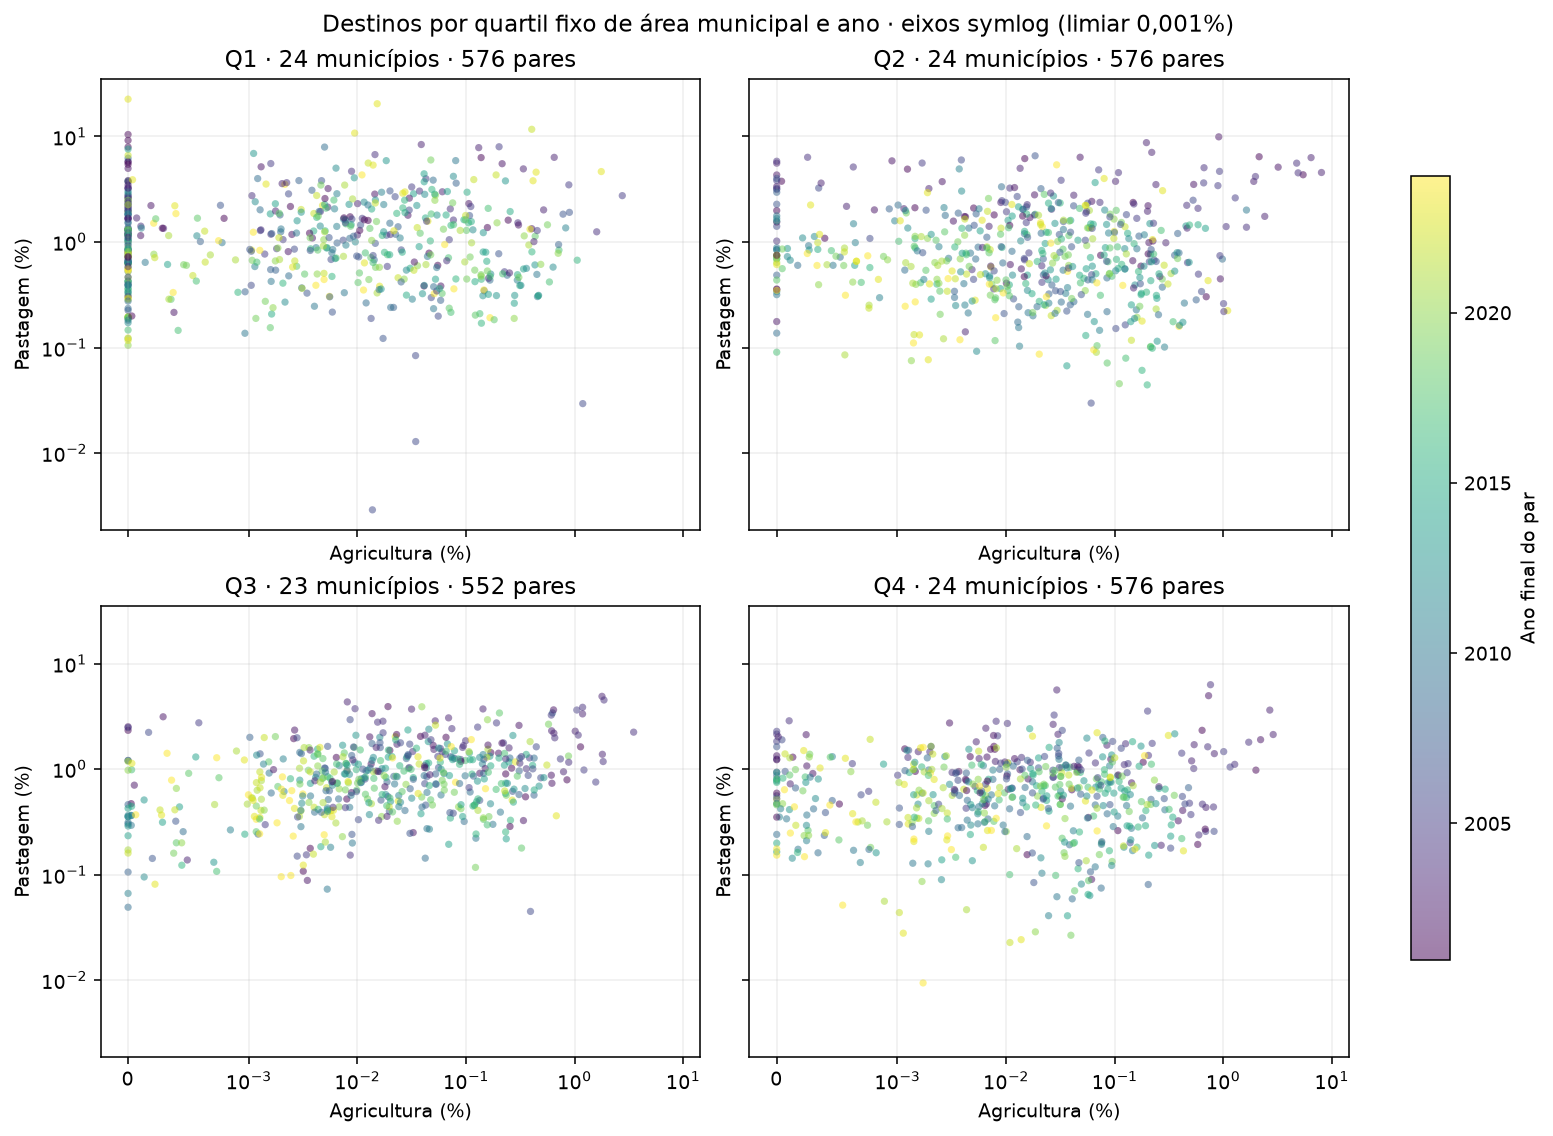

In [123]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 8), dpi=140, sharex=True, sharey=True, layout='constrained')
norma_anos = plt.Normalize(yconv_contexto['ano'].min(), yconv_contexto['ano'].max())
for eixo, quartil in zip(eixos.flat, ['Q1', 'Q2', 'Q3', 'Q4']):
    trecho = yconv_contexto.loc[yconv_contexto['Quartil de área municipal'].eq(quartil)]
    pontos = eixo.scatter(100 * trecho['taxa_conversao__agricultura'], 100 * trecho['taxa_conversao__pastagem'], c=trecho['ano'], cmap='viridis', norm=norma_anos, s=14, alpha=.5, linewidths=0)
    eixo.set_xscale('symlog', linthresh=.001)
    eixo.set_yscale('symlog', linthresh=.001)
    eixo.set(title=f'{quartil} · {trecho.codigo_ibge.nunique()} municípios · {len(trecho)} pares', xlabel='Agricultura (%)', ylabel='Pastagem (%)')
    eixo.grid(alpha=.2)
barra = fig.colorbar(pontos, ax=eixos.ravel().tolist(), shrink=.8)
barra.set_label('Ano final do par')
fig.suptitle('Destinos por quartil fixo de área municipal e ano · eixos symlog (limiar 0,001%)', fontsize=12)
plt.show()


As nuvens não ficam ordenadas em uma relação única entre os destinos. A estratificação permite observar heterogeneidade territorial e temporal sem atribuir a ela um efeito identificado. Os grupos têm limites explícitos e se referem à área total dos municípios selecionados; não são classes de capacidade produtiva, bioma ou vegetação remanescente. Não se pode inferir, por estas facetas, o condicionamento institucional previsto em H1.


**3. A normalização pela vegetação disponível muda a leitura dos fluxos?**

Os quartis abaixo são da vegetação nativa inicial nos pares observados. Um mesmo município pode ocupar grupos diferentes ao longo do tempo. Trata-se de diagnóstico da relação entre numerador e denominador, não de um efeito da vegetação inicial sobre a decisão de converter.


In [124]:
yconv_pares['Quartil de nativa inicial'], yconv_limites_nativa = pd.qcut(yconv_pares['y_nativa_inicial_ha'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], retbins=True)
yconv_grupos_nativa = yconv_pares.groupby('Quartil de nativa inicial', observed=True).agg(
    pares=('ano', 'size'), municipios=('codigo_ibge', 'nunique'), anos=('ano', 'nunique'),
    nativa_mediana=('y_nativa_inicial_ha', 'median'),
    agricultura_ha=('conversao_ha__agricultura', 'mean'), pastagem_ha=('conversao_ha__pastagem', 'mean'),
    agricultura_taxa=('taxa_conversao__agricultura', 'mean'), pastagem_taxa=('taxa_conversao__pastagem', 'mean')
)
yconv_grupos_nativa[['agricultura_taxa', 'pastagem_taxa']] *= 100
yconv_grupos_nativa['Limite inferior (ha)'] = yconv_limites_nativa[:-1]
yconv_grupos_nativa['Limite superior (ha)'] = yconv_limites_nativa[1:]
yconv_mostrar(yconv_grupos_nativa[['pares', 'municipios', 'anos', 'Limite inferior (ha)', 'Limite superior (ha)', 'nativa_mediana']].rename(columns={'pares': 'Pares', 'municipios': 'Municípios', 'anos': 'Anos', 'nativa_mediana': 'Nativa: mediana (ha)'}))
yconv_mostrar(yconv_grupos_nativa[['agricultura_ha', 'pastagem_ha', 'agricultura_taxa', 'pastagem_taxa']].rename(columns={'agricultura_ha': 'Agricultura: média (ha)', 'pastagem_ha': 'Pastagem: média (ha)', 'agricultura_taxa': 'Agricultura: média (%)', 'pastagem_taxa': 'Pastagem: média (%)'}))

yconv_associacao_denominador = pd.DataFrame({
    'N por par': [len(yconv_pares)] * len(yconv_medidas),
    'Spearman com nativa inicial': [yconv_pares[[c, 'y_nativa_inicial_ha']].corr(method='spearman').iloc[0, 1] for c in yconv_medidas]
}, index=['Agricultura (ha)', 'Pastagem (ha)', 'Agricultura (taxa)', 'Pastagem (taxa)'])
yconv_mostrar(yconv_associacao_denominador)


,Pares,Municípios,Anos,Limite inferior (ha),Limite superior (ha),Nativa: mediana (ha)
Quartil de nativa inicial,,,,,,
Q1,693,36,24,"6,485.420","93,485.199","34,597.958"
Q2,693,40,24,"93,485.199","229,870.718","137,228.267"
Q3,693,46,24,"229,870.718","395,158.077","295,947.242"
Q4,693,47,24,"395,158.077","2,737,508.696","826,639.957"


,Agricultura: média (ha),Pastagem: média (ha),Agricultura: média (%),Pastagem: média (%)
Quartil de nativa inicial,,,,
Q1,32.828,612.518,0.078,1.642
Q2,299.220,"1,813.059",0.185,1.161
Q3,322.819,"3,442.463",0.107,1.155
Q4,535.923,"7,162.312",0.079,0.807


,N por par,Spearman com nativa inicial
Agricultura (ha),2772,0.369
Pastagem (ha),2772,0.729
Agricultura (taxa),2772,0.020
Pastagem (taxa),2772,-0.199


O fluxo de pastagem acompanha mais fortemente o tamanho do estoque nativo inicial (Spearman aproximadamente 0,729) do que sua taxa, cuja associação com o denominador é negativa (aproximadamente −0,199). Para agricultura, a associação em hectares é positiva (0,369), enquanto a associação da taxa com o denominador é próxima de zero (0,020).

Esses contrastes mostram por que hectares e taxas não são intercambiáveis. Como o estoque inicial compõe a própria fórmula da taxa, esta tabela diagnostica a normalização; não oferece evidência independente sobre um determinante de H1. A distribuição dos municípios e dos anos também pode variar entre quartis.


**4. A associação depende de misturar diferenças entre municípios e mudanças no tempo?**

Compara-se a associação empilhada, a associação entre médias municipais e a associação entre desvios de cada medida à sua média municipal. Os três últimos contextos usam os mesmos municípios completos. Pearson resume associação linear; Spearman, associação de postos. Não se calculam p-valores ou intervalos que pressuponham independência dos pares do painel.


In [125]:
yconv_medias_mun = yconv_completos.groupby('codigo_ibge', observed=True)[yconv_medidas].mean()
yconv_desvios_mun = yconv_completos[yconv_medidas] - yconv_completos.groupby('codigo_ibge', observed=True)[yconv_medidas].transform('mean')
yconv_bases_associacao = [
    ('Todos os pares observados', yconv_validos[yconv_medidas], yconv_validos.codigo_ibge.nunique(), yconv_validos.ano.nunique()),
    ('Pares dos municípios completos', yconv_completos[yconv_medidas], len(yconv_medias_mun), yconv_anos_grade),
    ('Médias municipais na janela completa', yconv_medias_mun, len(yconv_medias_mun), yconv_anos_grade),
    ('Desvios à média municipal na janela completa', yconv_desvios_mun, len(yconv_medias_mun), yconv_anos_grade)
]
yconv_associacoes = []
for contexto, base, municipios, anos in yconv_bases_associacao:
    for prefixo, representacao in [('conversao_ha', 'Hectares'), ('taxa_conversao', 'Taxas')]:
        par = base[[f'{prefixo}__agricultura', f'{prefixo}__pastagem']].dropna()
        yconv_associacoes.append({'Contexto': contexto, 'Representação': representacao,
            'N por par': len(par), 'Municípios': municipios, 'Anos da janela': anos,
            'Pearson': par.iloc[:, 0].corr(par.iloc[:, 1], method='pearson'),
            'Spearman': par.corr(method='spearman').iloc[0, 1]})
yconv_associacoes = pd.DataFrame(yconv_associacoes)
yconv_mostrar(yconv_associacoes)


,Contexto,Representação,N por par,Municípios,Anos da janela,Pearson,Spearman
0,Todos os pares observados,Hectares,2772,137,24,0.291,0.330
1,Todos os pares observados,Taxas,2772,137,24,0.208,0.061
2,Pares dos municípios completos,Hectares,2280,95,24,0.219,0.317
3,Pares dos municípios completos,Taxas,2280,95,24,0.185,0.040
4,Médias municipais na janela completa,Hectares,95,95,24,0.091,0.338
5,Médias municipais na janela completa,Taxas,95,95,24,-0.044,-0.062
6,Desvios à média municipal na janela completa,Hectares,2280,95,24,0.337,0.353
7,Desvios à média municipal na janela completa,Taxas,2280,95,24,0.277,0.275


Nas taxas dos municípios completos, Spearman é aproximadamente 0,040 nos pares empilhados, −0,062 entre médias municipais e 0,275 entre desvios às médias municipais. Portanto, uma única correlação empilhada não resume todas as escalas de variação observadas.

Retirar a média municipal é uma transformação descritiva explicitada nesta tabela: não equivale a estimar o modelo de H1 nem elimina tendências e choques comuns de ano. O denominador compartilhado também permanece. As relações apresentadas descrevem os destinos e ajudam a avaliar representação e suporte; a resposta a preços, capacidade produtiva e instituições depende da análise posterior com X e de uma estratégia empírica própria.


###### Síntese

In [126]:
# Justificativa, alternativas, limitações e decisões pendentes

**Candidatas à modelagem.** Conforme o desenho prévio e o catálogo, recomenda-se levar as seguintes medidas à comparação de especificações preliminares, mantendo agricultura e pastagem separadas:

| Colunas | Papel no catálogo | Encaminhamento |
|---|---|---|
| `conversao_ha__agricultura` e `conversao_ha__pastagem` | G1; medidas diretas e principais de `Y_conv` | Melhores candidatas deste grupo para representar a magnitude física da conversão, em hectares, como variáveis dependentes por destino. |
| `taxa_conversao__agricultura` e `taxa_conversao__pastagem` | G1; principais em `Y_tx-conv` e derivadas secundárias em `Y_conv` | Prioritárias como resultados candidatos para a pergunta de H1, que enfatiza a parcela da vegetação disponível convertida. Os hectares oferecem uma representação alternativa; não são quatro resultados independentes. |
| `y_nativa_inicial_ha` | Denominador compatível; vínculo também com X5 | Preservar como insumo de construção e interpretação das taxas. Sua presença no denominador não justifica inclusão automática como controle exógeno. |
| Flags, áreas de cobertura, coleção, malha e máscara | G4; qualidade e proveniência | Acompanhar a elegibilidade e a rastreabilidade das observações; não incluir automaticamente como regressoras. |

`codigo_ibge` e `ano` identificam o painel. A recomendação acima organiza candidatas e funções; a escolha da representação, da amostra e da especificação permanece em aberto.

**Intuição e indícios.** No suporte observado, a conversão para pastagem apresenta taxas médias e medianas superiores às agrícolas. Ambos os destinos têm distribuições assimétricas à direita, e os 265 zeros agrícolas são observações válidas. Os maiores fluxos não coincidem com as maiores taxas, reforçando que escala territorial e intensidade relativa precisam ser distinguidas. Nos 95 municípios completos, as médias anuais atingem seu máximo em 2003 e são menores em 2024 que em 2001, sem trajetória monotônica.

As associações entre destinos mudam conforme se examinam pares empilhados, médias municipais ou desvios às médias municipais. Isso recomenda considerar a dimensão territorial e temporal na etapa econométrica. As relações com a vegetação inicial também refletem escala e a própria construção das taxas; não demonstram substituição entre destinos nem um mecanismo econômico identificado.

**Suporte e alcance.** Há 2.772 pares válidos e 612 ausentes (18,09% da grade), associados à cobertura incompleta. Os 95 municípios completos constituem uma seleção, não uma amostra final já definida. Esses resultados orientam representação, tratamento dos zeros e avaliação da cobertura; sem relacionar Y aos preços, à capacidade produtiva e às instituições sob uma estratégia empírica, não testam nem confirmam H1.


=======

##### --- (b) Y_tx-conv ---

Identificador Python: `Y_tx_conv`. 20 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

###### Criar


In [127]:
# Recorte fiel, preservando a base


In [128]:
Y_tx_conv = df1.loc[:, chaves_yx + [
    'conversao_ha__agricultura',
    'conversao_ha__pastagem',
    'taxa_conversao__agricultura',
    'taxa_conversao__pastagem',
    'y_colecao',
    'y_malha',
    'y_mascara_id',
    'y_area_total_ha',
    'y_area_valida_par_ha',
    'y_area_nao_valida_par_ha',
    'y_nativa_inicial_ha',
    'y_cobertura_completa',
    'y_fracao_area_valida_par',
    'y_flag_denominador_zero',
    'y_flag_denominador_ausente',
    'nativa_ha_lag1',
    'native_veg_ha_lag1',
    'native_veg_share_lag1',
    'flag_denominador_nulo',
    'flag_denominador_ausente',
]].copy()
Y_tx_conv.head()

,codigo_ibge,ano,conversao_ha__agricultura,conversao_ha__pastagem,taxa_conversao__agricultura,taxa_conversao__pastagem,y_colecao,y_malha,y_mascara_id,y_area_total_ha,...,y_nativa_inicial_ha,y_cobertura_completa,y_fracao_area_valida_par,y_flag_denominador_zero,y_flag_denominador_ausente,nativa_ha_lag1,native_veg_ha_lag1,native_veg_share_lag1,flag_denominador_nulo,flag_denominador_ausente
0,5100102,2001,5.093917,1030.491067,0.000086,0.017323,10.1,IBGE_MT_2023_141,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,85075.640222,...,59486.295731,True,1.0,False,False,59487.907621,59487.907621,0.699229,False,False
1,5100102,2002,1.468305,693.661899,0.000025,0.011781,10.1,IBGE_MT_2023_141,5807cd2f641779260fa4559cbed36ba1758c805727c9ac...,85075.640222,...,58878.434055,True,1.0,False,False,58880.226410,58880.226410,0.692087,False,False
2,5100102,2003,0.172670,791.607567,0.000003,0.013461,10.1,IBGE_MT_2023_141,87e1efe7cc9af76935236018b19355ab089f5ed333ff2c...,85075.640222,...,58805.484389,True,1.0,False,False,58807.306528,58807.306528,0.691230,False,False
3,5100102,2004,0.000000,778.872226,0.000000,0.013255,10.1,IBGE_MT_2023_141,cb73fabdf74ffdec0a72c86f9512fbb2b3ec6eebb880fc...,85075.640222,...,58759.069254,True,1.0,False,False,58761.225260,58761.225260,0.690688,False,False
4,5100102,2005,1.208967,615.813542,0.000021,0.010526,10.1,IBGE_MT_2023_141,9b9c3f1ac4a2aaa976d1f8022532f78a75bd38db951809...,85075.640222,...,58501.389359,True,1.0,False,False,58503.781528,58503.781528,0.687662,False,False


In [129]:
Y_tx_conv.columns.tolist()


['codigo_ibge',
 'ano',
 'conversao_ha__agricultura',
 'conversao_ha__pastagem',
 'taxa_conversao__agricultura',
 'taxa_conversao__pastagem',
 'y_colecao',
 'y_malha',
 'y_mascara_id',
 'y_area_total_ha',
 'y_area_valida_par_ha',
 'y_area_nao_valida_par_ha',
 'y_nativa_inicial_ha',
 'y_cobertura_completa',
 'y_fracao_area_valida_par',
 'y_flag_denominador_zero',
 'y_flag_denominador_ausente',
 'nativa_ha_lag1',
 'native_veg_ha_lag1',
 'native_veg_share_lag1',
 'flag_denominador_nulo',
 'flag_denominador_ausente']

In [130]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Numeração original do dicionário df: 1–17, 158 e 176–179.
# Os números indicam a posição na origem, não a posição neste recorte.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#3 - conversao_ha__agricultura: Vegetação nativa em t−1 convertida em agricultura em t (MapBiomas) | ha | municipal (MT), anual.

#4 - conversao_ha__pastagem: Vegetação nativa em t−1 convertida em pastagem em t (MapBiomas) | ha | municipal (MT), anual.

#5 - taxa_conversao__agricultura: Conversão para agricultura / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#6 - taxa_conversao__pastagem: Conversão para pastagem / vegetação nativa inicial na mesma máscara | proporção (0–1) | municipal (MT), anual.

#7 - y_colecao: Versão da coleção MapBiomas usada em Y (10.1) | categoria | referência comum ao painel municipal de MT.

#8 - y_malha: Referência territorial usada em Y (IBGE MT 2023, 141 municípios) | identificador textual | referência comum ao painel municipal de MT.

#9 - y_mascara_id: Identificador da máscara espacial usada nas transições de Y | hash textual | municipal (MT), anual.

#10 - y_area_total_ha: Área total da máscara municipal usada em Y | ha | municipal (MT), anual.

#11 - y_area_valida_par_ha: Área com classificação válida nos dois mapas (t−1 e t) | ha | municipal (MT), anual.

#12 - y_area_nao_valida_par_ha: Área sem classificação válida em pelo menos um dos dois mapas | ha | municipal (MT), anual.

#13 - y_nativa_inicial_ha: Vegetação nativa em t−1 na máscara das transições; denominador de Y | ha | municipal (MT), anual.

#14 - y_cobertura_completa: Indica cobertura completa do par de mapas usado em Y | booleano (True/False) | municipal (MT), anual.

#15 - y_fracao_area_valida_par: Área válida nos dois mapas / área total da máscara de Y | proporção (0–1) | municipal (MT), anual.

#16 - y_flag_denominador_zero: Indica vegetação nativa inicial de Y igual a zero | booleano (True/False) | municipal (MT), anual.

#17 - y_flag_denominador_ausente: Indica ausência do denominador de Y | booleano (True/False) | municipal (MT), anual.

#18 - nativa_ha_lag1: Estoque de área de vegetação nativa no MapBiomas em t−1 | ha | municipal (MT), anual.

#19 - native_veg_ha_lag1: Estoque nativo em t−1 preservado da fonte; candidato distinto do denominador de Y | ha | municipal (MT), anual.

#20 - native_veg_share_lag1: Estoque nativo / área total mapeada em t−1, preservado da fonte | proporção (0–1) | municipal (MT), anual.

#21 - flag_denominador_nulo: Indica estoque candidato native_veg_ha_lag1 igual a zero | booleano (True/False) | municipal (MT), anual.

#22 - flag_denominador_ausente: Indica estoque candidato native_veg_ha_lag1 ausente | booleano (True/False) | municipal (MT), anual.


###### Estrutura


In [131]:
# Dimensões, tipos, chaves e domínios


In [132]:
Y_tx_conv.shape


(3384, 22)

In [133]:
Y_tx_conv.info(verbose=True, show_counts=True)


<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype        
---  ------                       --------------  -----        
 0   codigo_ibge                  3384 non-null   category     
 1   ano                          3384 non-null   period[Y-DEC]
 2   conversao_ha__agricultura    2772 non-null   float64      
 3   conversao_ha__pastagem       2772 non-null   float64      
 4   taxa_conversao__agricultura  2772 non-null   float64      
 5   taxa_conversao__pastagem     2772 non-null   float64      
 6   y_colecao                    3384 non-null   float64      
 7   y_malha                      3384 non-null   str          
 8   y_mascara_id                 3384 non-null   str          
 9   y_area_total_ha              3384 non-null   float64      
 10  y_area_valida_par_ha         3384 non-null   float64      
 11  y_area_nao_valida_par_ha     3384 non-null   float64      
 12  y_n

###### Qualidade dos dados


In [134]:
# Ausências, zeros, flags e suporte territorial/temporal
from IPython.display import display, Markdown

def ytx_mostrar(tabela, casas=3):
    # Formatação local: não muda opções de exibição das outras seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', None,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

ytx_chaves = ['codigo_ibge', 'ano']
ytx_fluxos = ['conversao_ha__agricultura', 'conversao_ha__pastagem']
ytx_taxas = ['taxa_conversao__agricultura', 'taxa_conversao__pastagem']
ytx_medidas = ytx_fluxos + ytx_taxas
ytx_areas_estoques = [
    'y_area_total_ha', 'y_area_valida_par_ha', 'y_area_nao_valida_par_ha',
    'y_nativa_inicial_ha', 'nativa_ha_lag1', 'native_veg_ha_lag1',
]
ytx_proporcoes_diagnosticas = ['y_fracao_area_valida_par', 'native_veg_share_lag1']
ytx_quantitativas = ytx_medidas + ytx_areas_estoques + ytx_proporcoes_diagnosticas
ytx_flags = [
    'y_cobertura_completa', 'y_flag_denominador_zero', 'y_flag_denominador_ausente',
    'flag_denominador_nulo', 'flag_denominador_ausente',
]
# Chaves, flags e y_colecao não compõem a lista de medidas quantitativas.


In [135]:
# Contar ausências em todas as colunas, sem eliminar observações.
ytx_ausentes = Y_tx_conv.isna().sum().to_frame('Ausentes')
ytx_ausentes['Ausentes (%)'] = 100 * Y_tx_conv.isna().mean()
ytx_mostrar(ytx_ausentes)


,Ausentes,Ausentes (%)
codigo_ibge,0,0.000
ano,0,0.000
conversao_ha__agricultura,612,18.085
conversao_ha__pastagem,612,18.085
taxa_conversao__agricultura,612,18.085
taxa_conversao__pastagem,612,18.085
y_colecao,0,0.000
y_malha,0,0.000
y_mascara_id,0,0.000
y_area_total_ha,0,0.000


In [136]:
# Contar zeros apenas em medidas quantitativas; False das flags não é zero de conversão.
ytx_zeros = Y_tx_conv[ytx_quantitativas].eq(0).sum().to_frame('Zeros')
ytx_zeros['Valores válidos'] = Y_tx_conv[ytx_quantitativas].notna().sum()
ytx_zeros['Zeros / válidos (%)'] = 100 * ytx_zeros['Zeros'] / ytx_zeros['Valores válidos'].replace(0, np.nan)
ytx_mostrar(ytx_zeros)


,Zeros,Valores válidos,Zeros / válidos (%)
conversao_ha__agricultura,265,2772,9.560
conversao_ha__pastagem,0,2772,0.000
taxa_conversao__agricultura,265,2772,9.560
taxa_conversao__pastagem,0,2772,0.000
y_area_total_ha,0,3384,0.000
y_area_valida_par_ha,0,3384,0.000
y_area_nao_valida_par_ha,2772,3384,81.915
y_nativa_inicial_ha,0,3384,0.000
nativa_ha_lag1,0,3384,0.000
native_veg_ha_lag1,0,3384,0.000


In [137]:
# True, False e ausência são estados distintos das flags.
ytx_estados_flags = pd.DataFrame({
    'True': [int(Y_tx_conv[ytx_coluna].eq(True).sum()) for ytx_coluna in ytx_flags],
    'False': [int(Y_tx_conv[ytx_coluna].eq(False).sum()) for ytx_coluna in ytx_flags],
    'Ausente': [int(Y_tx_conv[ytx_coluna].isna().sum()) for ytx_coluna in ytx_flags],
}, index=ytx_flags)
display(ytx_estados_flags)


,True,False,Ausente
y_cobertura_completa,2772,612,0
y_flag_denominador_zero,0,3384,0
y_flag_denominador_ausente,0,3384,0
flag_denominador_nulo,0,3384,0
flag_denominador_ausente,0,3384,0


Zeros quantitativos válidos não são ausências. As flags `y_flag_denominador_zero` e `y_flag_denominador_ausente` se referem ao denominador compatível de Y, `y_nativa_inicial_ha`; `flag_denominador_nulo` e `flag_denominador_ausente` acompanham o estoque candidato `native_veg_ha_lag1`. As duas famílias não são intercambiáveis e não substituem a verificação de `y_cobertura_completa`.


In [138]:
# Valores duplicados e completude da chave município–ano


In [139]:
ytx_duplicacao_chaves = pd.Series({
    'Linhas inteiras duplicadas': int(Y_tx_conv.duplicated().sum()),
    'Chaves município–ano duplicadas': int(Y_tx_conv.duplicated(ytx_chaves).sum()),
    'Linhas com chave incompleta': int(Y_tx_conv[ytx_chaves].isna().any(axis=1).sum()),
}, name='Contagem').to_frame()
display(ytx_duplicacao_chaves)


,Contagem
Linhas inteiras duplicadas,0
Chaves município–ano duplicadas,0
Linhas com chave incompleta,0


###### Descritiva


In [140]:
# Descritiva inicial. Resumos apropriados ao papel e à unidade da coluna.


In [141]:
# Resumo quantitativo principal: conserva zeros válidos e ignora NaN no cálculo de cada coluna.
# As taxas e frações permanecem em proporção; áreas e estoques estão em hectares.
ytx_descritiva_quantitativa = Y_tx_conv[ytx_quantitativas].describe().T
ytx_descritiva_quantitativa['Ausentes'] = Y_tx_conv[ytx_quantitativas].isna().sum()
ytx_mostrar(ytx_descritiva_quantitativa, casas=6)


,count,mean,std,min,25%,50%,75%,max,Ausentes
conversao_ha__agricultura,"2,772.000000",297.697312,"1,015.382300",0.000000,3.114156,26.987478,173.347514,"18,222.268087",612
conversao_ha__pastagem,"2,772.000000","3,257.588132","4,832.176411",0.953154,579.761195,"1,644.679448","3,769.385707","56,983.225434",612
taxa_conversao__agricultura,"2,772.000000",0.001122,0.003751,0.000000,0.000018,0.000143,0.000761,0.079950,612
taxa_conversao__pastagem,"2,772.000000",0.011915,0.014295,0.000029,0.004291,0.007994,0.014125,0.265411,612
y_area_total_ha,"3,384.000000","640,572.702137","596,634.853183","34,432.115967","229,129.505382","452,527.754377","843,902.909442","2,796,089.259072",0
y_area_valida_par_ha,"3,384.000000","640,538.845979","596,549.147694","34,432.115967","229,129.505382","452,527.754377","843,902.909442","2,796,089.259072",0
y_area_nao_valida_par_ha,"3,384.000000",33.856158,280.248085,0.000000,0.000000,0.000000,0.000000,"3,152.443287",0
y_nativa_inicial_ha,"3,384.000000","416,822.259062","495,642.256511","6,485.419932","100,895.152377","250,880.514449","438,459.568205","2,737,508.696322",0
nativa_ha_lag1,"3,384.000000","416,823.734975","495,643.598813","6,484.720236","100,898.708805","250,878.518833","438,465.890436","2,737,545.069287",0
native_veg_ha_lag1,"3,384.000000","416,823.734975","495,643.598813","6,484.720236","100,898.708805","250,878.518833","438,465.890436","2,737,545.069287",0


In [142]:
# Resumo complementar das duas taxas condicionado a valores positivos por coluna.
# Não altera Y_tx_conv, nem recodifica flags ou estoques.
ytx_positivos = Y_tx_conv[ytx_taxas].where(Y_tx_conv[ytx_taxas].gt(0))
ytx_mostrar(ytx_positivos.describe().T, casas=9)


,count,mean,std,min,25%,50%,75%,max
taxa_conversao__agricultura,"2,507.000000000",0.001240965,0.003925300,0.000000122,0.000037979,0.000198016,0.000915444,0.079950147
taxa_conversao__pastagem,"2,772.000000000",0.011915169,0.014295427,0.000029069,0.004291088,0.007994081,0.014125336,0.265410785


O resumo principal descreve pares município–ano observados em cada coluna, incluindo zeros válidos. O resumo de `ytx_positivos` é complementar e condicional a valores positivos de cada taxa; não define uma amostra conjunta nem a amostra final dos modelos. As ausências originais permanecem ausências. Estoques candidatos, denominador de Y e diagnósticos de cobertura conservam seus papéis distintos.


In [143]:
# Estatísticas descritivas de colunas não numéricas, incluindo chaves e flags.
ytx_descritiva_nao_numerica = Y_tx_conv.describe(exclude=['number']).T
display(ytx_descritiva_nao_numerica)


,count,unique,top,freq
codigo_ibge,3384,141,5100102,24
ano,3384,24,2001,141
y_malha,3384,1,IBGE_MT_2023_141,3384
y_mascara_id,3384,3384,0a4085a11f99daf93ca8e40b98365646a9c789aedaba87...,1
y_cobertura_completa,3384,2,True,2772
y_flag_denominador_zero,3384,1,False,3384
y_flag_denominador_ausente,3384,1,False,3384
flag_denominador_nulo,3384,1,False,3384
flag_denominador_ausente,3384,1,False,3384


In [144]:
# y_colecao é um identificador de versão, mesmo quando importado como número.
ytx_colecao_frequencia = Y_tx_conv['y_colecao'].value_counts(dropna=False).rename_axis('Coleção').to_frame('Observações')
display(ytx_colecao_frequencia)
display(Markdown('`y_colecao` documenta a versão da coleção MapBiomas; não é uma medida quantitativa contínua. `y_malha` e `y_mascara_id` documentam a referência territorial e a máscara das transições.'))


,Observações
Coleção,
10.1,3384


`y_colecao` documenta a versão da coleção MapBiomas; não é uma medida quantitativa contínua. `y_malha` e `y_mascara_id` documentam a referência territorial e a máscara das transições.

###### Análise Univariada


In [145]:
# Aprofundamento das distribuições, denominadores e trajetórias


**1. Quais observações sustentam as distribuições?**

A base desta etapa é uma cópia fiel de `Y_tx_conv`, com zeros válidos e ausências preservados. As duas taxas são os resultados principais deste candidato; os fluxos são seus numeradores. Os três estoques em hectares e a participação nativa defasada são insumos distintos, a comparar antes de qualquer escolha para modelagem. As medidas compartilhadas com `Y_conv` são conferidas, sem repetir as distribuições dos fluxos já apresentadas.

As taxas e a participação nativa são apresentadas em % somente em cópias. Cada observação continua sendo um par município–ano; a repetição no painel não equivale a observações independentes para inferência.


In [146]:
ytx_aed = Y_tx_conv.copy()
ytx_destinos = ['agricultura', 'pastagem']
ytx_rotulos = {'agricultura': 'Agricultura', 'pastagem': 'Pastagem'}
ytx_cores = {'agricultura': '#4c78a8', 'pastagem': '#e09136'}
ytx_estoques = ['y_nativa_inicial_ha', 'nativa_ha_lag1', 'native_veg_ha_lag1']
ytx_share = 'native_veg_share_lag1'

# Conferência das colunas comuns antes de converter o ano na cópia de análise.
pd.testing.assert_frame_equal(Y_tx_conv.loc[:, Y_conv.columns], Y_conv)
ytx_aed['ano'] = ytx_aed['ano'].dt.year
assert not ytx_aed.duplicated(ytx_chaves).any()
assert not ytx_aed[ytx_chaves].isna().any().any()
assert np.isfinite(ytx_aed[ytx_quantitativas].dropna().to_numpy()).all()
assert not np.isinf(ytx_aed[ytx_quantitativas].to_numpy()).any()
assert ytx_aed[ytx_medidas].isna().eq(ytx_aed[ytx_medidas[0]].isna(), axis=0).all().all()
assert ytx_aed[ytx_medidas[0]].notna().equals(ytx_aed['y_cobertura_completa'])
assert ytx_aed[ytx_areas_estoques].ge(0).all().all()
assert ytx_aed[ytx_proporcoes_diagnosticas].ge(0).all().all()
assert ytx_aed[ytx_proporcoes_diagnosticas].le(1).all().all()
assert ytx_aed['y_flag_denominador_zero'].equals(ytx_aed['y_nativa_inicial_ha'].eq(0))
assert ytx_aed['y_flag_denominador_ausente'].equals(ytx_aed['y_nativa_inicial_ha'].isna())
assert ytx_aed['flag_denominador_nulo'].equals(ytx_aed['native_veg_ha_lag1'].eq(0))
assert ytx_aed['flag_denominador_ausente'].equals(ytx_aed['native_veg_ha_lag1'].isna())
assert np.allclose(ytx_aed['y_area_valida_par_ha'] + ytx_aed['y_area_nao_valida_par_ha'],
                   ytx_aed['y_area_total_ha'], rtol=1e-8, atol=1e-4)

ytx_validos = ytx_aed.dropna(subset=ytx_medidas).copy()
assert ytx_validos[ytx_fluxos].ge(0).all().all()
assert ytx_validos[ytx_taxas].ge(0).all().all() and ytx_validos[ytx_taxas].le(1).all().all()
assert ytx_validos['y_nativa_inicial_ha'].gt(0).all()
assert ytx_validos[ytx_fluxos].sum(axis=1).le(ytx_validos['y_nativa_inicial_ha'] + 1e-4).all()
for ytx_destino in ytx_destinos:
    # Correspondência da fórmula, sem reconstruir/substituir as taxas originais.
    assert np.allclose(ytx_validos[f'taxa_conversao__{ytx_destino}'],
                       ytx_validos[f'conversao_ha__{ytx_destino}'] / ytx_validos['y_nativa_inicial_ha'],
                       rtol=1e-10, atol=1e-12)

ytx_n_anos = ytx_aed['ano'].nunique()
ytx_cobertura_mun = ytx_aed.groupby('codigo_ibge', observed=True)[ytx_taxas[0]].count()
assert ytx_aed.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(ytx_n_anos).all()
ytx_municipios_completos = ytx_cobertura_mun.index[ytx_cobertura_mun.eq(ytx_n_anos)]
ytx_completos = ytx_validos.loc[ytx_validos['codigo_ibge'].isin(ytx_municipios_completos)].copy()
ytx_suporte = pd.DataFrame({
    'Pares município–ano': [len(ytx_aed), len(ytx_validos), len(ytx_aed) - len(ytx_validos), len(ytx_completos)],
    'Municípios': [ytx_aed['codigo_ibge'].nunique(), ytx_validos['codigo_ibge'].nunique(),
                   ytx_aed.loc[ytx_aed[ytx_taxas[0]].isna(), 'codigo_ibge'].nunique(), len(ytx_municipios_completos)],
    'Anos': [ytx_n_anos, ytx_validos['ano'].nunique(),
             ytx_aed.loc[ytx_aed[ytx_taxas[0]].isna(), 'ano'].nunique(), ytx_completos['ano'].nunique()],
}, index=['Grade 2001–2024', 'Taxas observadas', 'Taxas ausentes', 'Municípios com 24 anos de Y'])
display(ytx_suporte)
display(Markdown(f"São **{len(ytx_validos):,} pares válidos** e **{len(ytx_aed)-len(ytx_validos):,} ausentes** "
                 f"({100*(1-len(ytx_validos)/len(ytx_aed)):.2f}% da grade). Há **{len(ytx_municipios_completos)} municípios completos**, "
                 f"**{ytx_cobertura_mun.between(1,ytx_n_anos-1).sum()} parciais** e **{ytx_cobertura_mun.eq(0).sum()} sem Y**. "
                 "Os estoques disponíveis nas linhas sem taxa não recuperam as transições ausentes."))


,Pares município–ano,Municípios,Anos
Grade 2001–2024,3384,141,24
Taxas observadas,2772,137,24
Taxas ausentes,612,46,24
Municípios com 24 anos de Y,2280,95,24


São **2,772 pares válidos** e **612 ausentes** (18.09% da grade). Há **95 municípios completos**, **42 parciais** e **4 sem Y**. Os estoques disponíveis nas linhas sem taxa não recuperam as transições ausentes.

**2. Onde se concentram as taxas e quão longas são as caudas?**

Complementam-se os resumos anteriores com zeros, quantis superiores, IQR e assimetria. Os histogramas usam 40 classes de igual largura, comuns aos dois destinos, sobre toda a amplitude conjunta. As ECDF usam os mesmos limites e eixo symlog, com trecho linear até 0,001 ponto percentual, para conservar zero e tornar a cauda legível. Essa escala afeta a figura, não as medidas.


,N,Zeros,Zeros / válidos (%),Média (%),Mediana (%),IQR (p.p.),P95 (%),P99 (%),Máximo (%),Assimetria
Destino,,,,,,,,,,
Agricultura,2772,265,9.5599,0.1122,0.0143,0.0743,0.4733,1.7224,7.9950,10.0507
Pastagem,2772,0,0.0000,1.1915,0.7994,0.9834,3.6088,6.3619,26.5411,5.9476


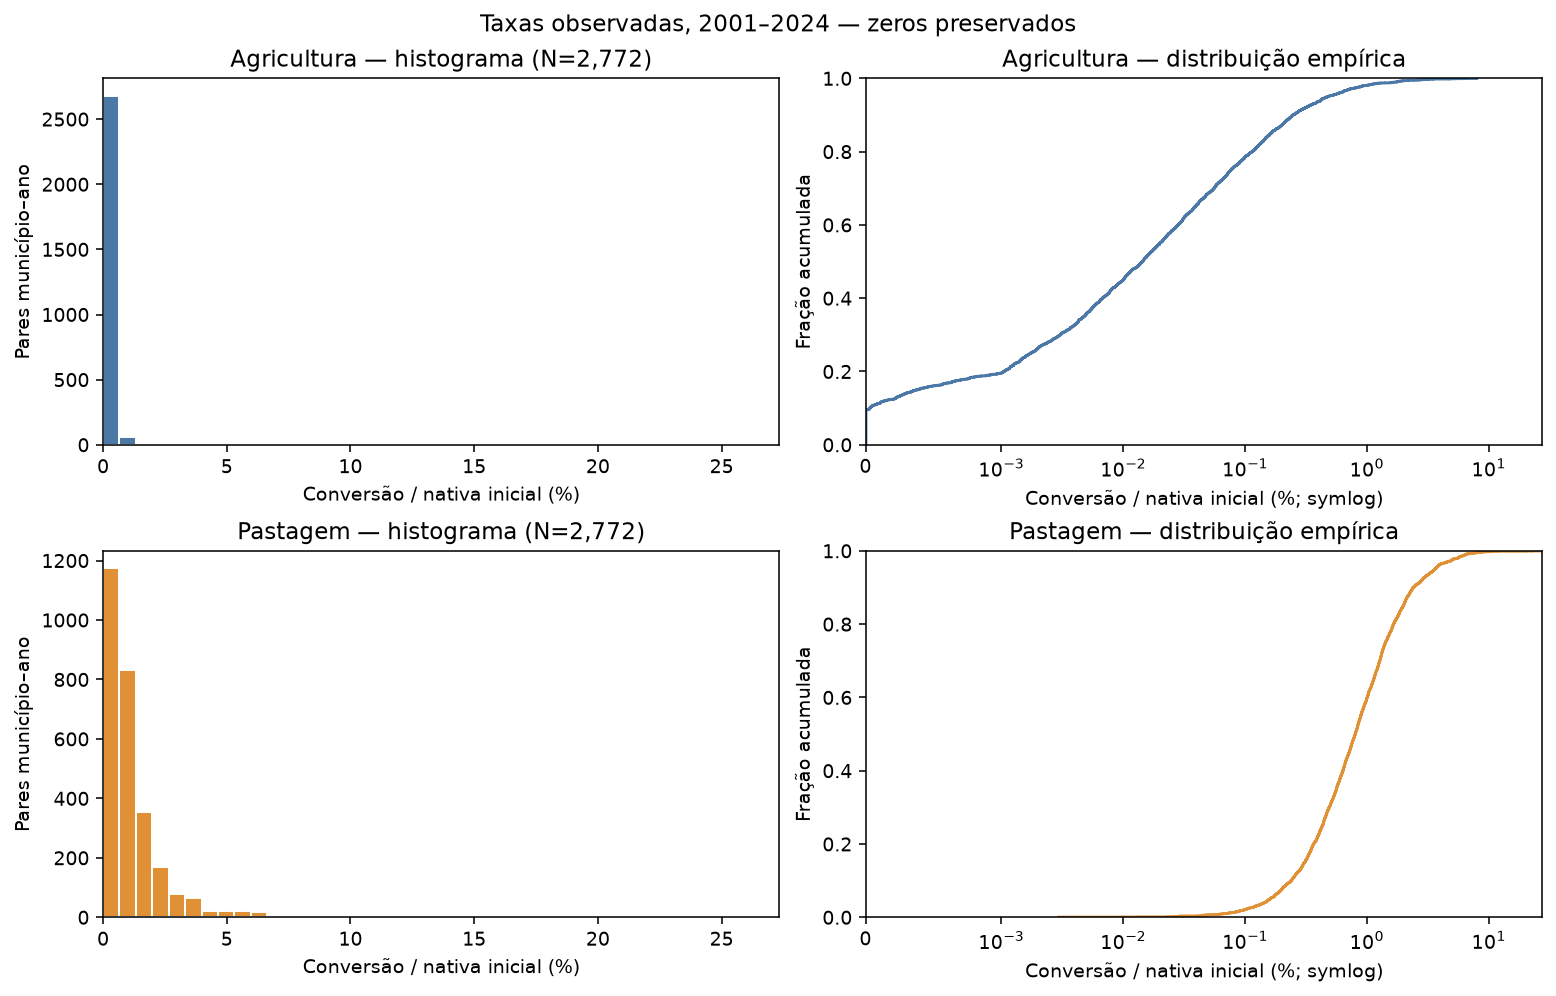

In [147]:
ytx_distribuicao = []
for ytx_destino in ytx_destinos:
    ytx_serie = ytx_aed[f'taxa_conversao__{ytx_destino}'].dropna() * 100
    ytx_distribuicao.append({
        'Destino': ytx_rotulos[ytx_destino], 'N': len(ytx_serie),
        'Zeros': int(ytx_serie.eq(0).sum()), 'Zeros / válidos (%)': 100 * ytx_serie.eq(0).mean(),
        'Média (%)': ytx_serie.mean(), 'Mediana (%)': ytx_serie.median(),
        'IQR (p.p.)': ytx_serie.quantile(.75) - ytx_serie.quantile(.25),
        'P95 (%)': ytx_serie.quantile(.95), 'P99 (%)': ytx_serie.quantile(.99),
        'Máximo (%)': ytx_serie.max(), 'Assimetria': ytx_serie.skew(),
    })
ytx_distribuicao = pd.DataFrame(ytx_distribuicao).set_index('Destino')
ytx_mostrar(ytx_distribuicao, casas=4)

ytx_max_taxa_pct = 100 * ytx_validos[ytx_taxas].max().max()
ytx_classes_taxas = np.linspace(0, ytx_max_taxa_pct, 41)
fig, ytx_eixos = plt.subplots(2, 2, figsize=(11, 7), dpi=140, layout='constrained')
for ytx_linha, ytx_destino in enumerate(ytx_destinos):
    ytx_serie = ytx_validos[f'taxa_conversao__{ytx_destino}'] * 100
    ytx_eixos[ytx_linha, 0].hist(ytx_serie, bins=ytx_classes_taxas, color=ytx_cores[ytx_destino], edgecolor='white')
    ytx_eixos[ytx_linha, 0].set(xlim=(0, ytx_max_taxa_pct * 1.03), ylabel='Pares município–ano',
                              xlabel='Conversão / nativa inicial (%)', title=f'{ytx_rotulos[ytx_destino]} — histograma (N={len(ytx_serie):,})')
    sns.ecdfplot(x=ytx_serie, ax=ytx_eixos[ytx_linha, 1], color=ytx_cores[ytx_destino])
    ytx_eixos[ytx_linha, 1].set_xscale('symlog', linthresh=.001)
    ytx_eixos[ytx_linha, 1].set(xlim=(0, ytx_max_taxa_pct * 1.03), ylim=(0, 1),
                              xlabel='Conversão / nativa inicial (%; symlog)', ylabel='Fração acumulada',
                              title=f'{ytx_rotulos[ytx_destino]} — distribuição empírica')
fig.suptitle('Taxas observadas, 2001–2024 — zeros preservados')
plt.show()


Reproduz-se o diagnóstico de `Y_conv`: caudas à direita, com média/mediana de aproximadamente **0,112%/0,014% na agricultura** e **1,192%/0,799% na pastagem**. Os **265 zeros agrícolas (9,56% dos válidos)** permanecem na distribuição; não há zeros de pastagem no suporte observado. O histograma evidencia a concentração perto de zero e a ECDF permite distinguir valores pequenos. A assimetria recomenda examinar extremos e adequação da especificação posterior; não autoriza excluir zeros ou escolher automaticamente uma transformação.


**3. O que os estoques defasados e a participação nativa acrescentam?**

Os estoques em hectares descrevem quantidade disponível; `native_veg_share_lag1` descreve composição territorial na fonte (estoque nativo / área total mapeada em t−1). Não é taxa de conversão nem denominador em hectares. O resumo distingue a grade inteira do suporte com Y observado; seus N diferentes não devem ser confundidos com recuperação da cobertura de Y.


N  Ausentes no suporte  \
Suporte     Coluna                Unidade                              
Grade       y_nativa_inicial_ha   ha       3384                    0   
            nativa_ha_lag1        ha       3384                    0   
            native_veg_ha_lag1    ha       3384                    0   
            native_veg_share_lag1 %        3384                    0   
Y observado y_nativa_inicial_ha   ha       2772                    0   
            nativa_ha_lag1        ha       2772                    0   
            native_veg_ha_lag1    ha       2772                    0   
            native_veg_share_lag1 %        2772                    0   

                                             Mínimo       Média     Mediana  \
Suporte     Coluna                Unidade                                     
Grade       y_nativa_inicial_ha   ha      6,485.420 416,822.259 250,880.514   
            nativa_ha_lag1        ha      6,484.720 416,823.735 250,878.519   
            native_veg_ha_lag1    ha      6,484.720 416,823.735 250,878.519   
            native_veg_share_lag1 %           7.274      54.484      55.397   
Y observado y_nativa_inicial_ha   ha      6,485.420 362,087.226 229,870.718   
            nativa_ha_lag1        ha      6,484.720 362,089.106 229,870.299   
            native_veg_ha_lag1    ha      6,484.720 362,089.106 229,870.299   
            native_veg_share_lag1 %           7.274      53.763      55.103   

                                                  P25         P75  \
Suporte     Coluna                Unidade                           
Grade       y_nativa_inicial_ha   ha      100,895.152 438,459.568   
            nativa_ha_lag1        ha      100,898.709 438,465.890   
            native_veg_ha_lag1    ha      100,898.709 438,465.890   
            native_veg_share_lag1 %            41.327      68.124   
Y observado y_nativa_inicial_ha   ha       93,485.199 395,158.077   
            nativa_ha_lag1        ha       93,489.968 395,160.272   
            native_veg_ha_lag1    ha       93,489.968 395,160.272   
            native_veg_share_lag1 %            40.672      67.002   

                                                    P95        Máximo  
Suporte     Coluna                Unidade                              
Grade       y_nativa_inicial_ha   ha      1,573,291.486 2,737,508.696  
            nativa_ha_lag1        ha      1,573,290.452 2,737,545.069  
            native_veg_ha_lag1    ha      1,573,290.452 2,737,545.069  
            native_veg_share_lag1 %              87.025        97.905  
Y observado y_nativa_inicial_ha   ha      1,339,107.824 2,737,508.696  
            nativa_ha_lag1        ha      1,339,100.323 2,737,545.069  
            native_veg_ha_lag1    ha      1,339,100.323 2,737,545.069  
            native_veg_share_lag1 %              86.744        97.905

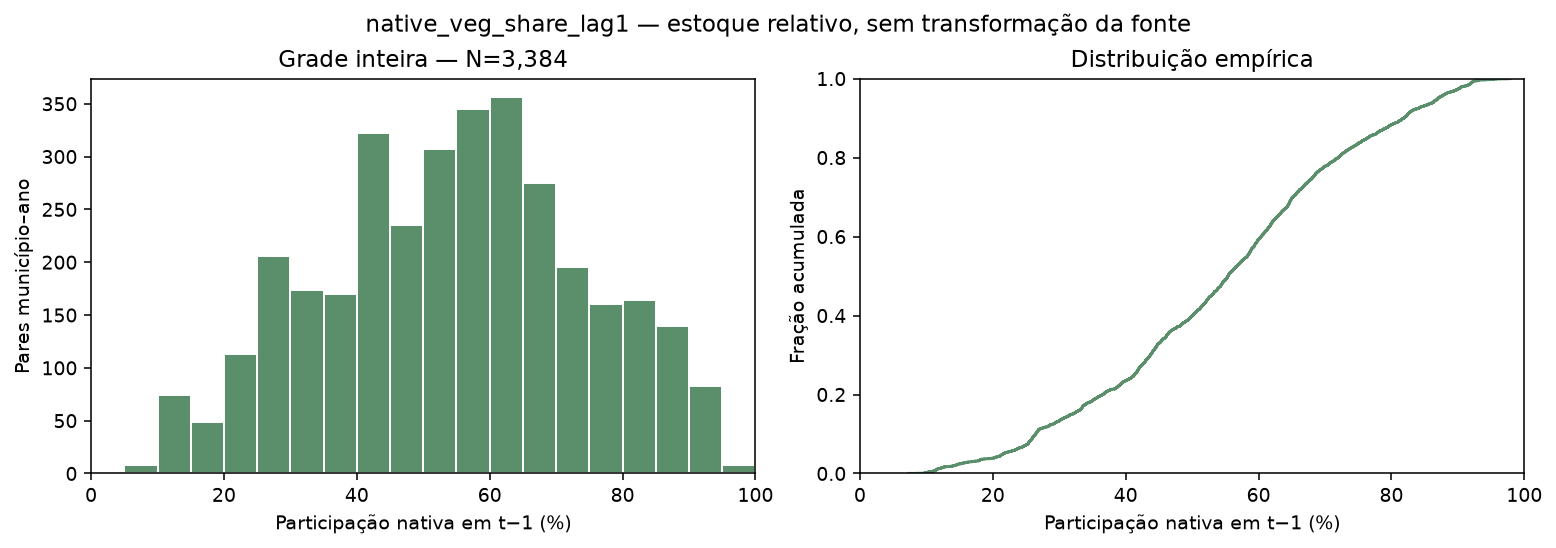

In [148]:
ytx_resumo_estoques = []
for ytx_nome_suporte, ytx_base in [('Grade', ytx_aed), ('Y observado', ytx_validos)]:
    for ytx_coluna in ytx_estoques + [ytx_share]:
        ytx_escala = 100 if ytx_coluna == ytx_share else 1
        ytx_serie = ytx_base[ytx_coluna].dropna() * ytx_escala
        ytx_resumo_estoques.append({
            'Suporte': ytx_nome_suporte, 'Coluna': ytx_coluna,
            'Unidade': '%' if ytx_coluna == ytx_share else 'ha',
            'N': len(ytx_serie), 'Ausentes no suporte': int(ytx_base[ytx_coluna].isna().sum()),
            'Mínimo': ytx_serie.min(), 'Média': ytx_serie.mean(), 'Mediana': ytx_serie.median(),
            'P25': ytx_serie.quantile(.25), 'P75': ytx_serie.quantile(.75),
            'P95': ytx_serie.quantile(.95), 'Máximo': ytx_serie.max(),
        })
ytx_resumo_estoques = pd.DataFrame(ytx_resumo_estoques).set_index(['Suporte', 'Coluna', 'Unidade'])
ytx_mostrar(ytx_resumo_estoques, casas=3)

# Participação limitada a [0,100]: classes fixas de 5 pontos percentuais.
fig, ytx_eixos = plt.subplots(1, 2, figsize=(11, 3.8), dpi=140, layout='constrained')
ytx_serie = ytx_aed[ytx_share].dropna() * 100
ytx_eixos[0].hist(ytx_serie, bins=np.arange(0, 105, 5), color='#5b8f6b', edgecolor='white')
ytx_eixos[0].set(xlim=(0, 100), xlabel='Participação nativa em t−1 (%)', ylabel='Pares município–ano',
                 title=f'Grade inteira — N={len(ytx_serie):,}')
sns.ecdfplot(x=ytx_serie, ax=ytx_eixos[1], color='#5b8f6b')
ytx_eixos[1].set(xlim=(0, 100), ylim=(0, 1), xlabel='Participação nativa em t−1 (%)',
                 ylabel='Fração acumulada', title='Distribuição empírica')
fig.suptitle('native_veg_share_lag1 — estoque relativo, sem transformação da fonte')
plt.show()


Os três estoques e a participação estão preenchidos e são positivos nos **3.384 pares**. Na grade, a participação média é **54,48%**, a mediana **55,40%**, e os quartis **41,33%/68,12%**; a amplitude vai de **7,27% a 97,90%**, sem valores fora de [0,1] na coluna original. Esses resultados mostram heterogeneidade da vegetação remanescente, mas incluem municípios e anos sem taxa observada. Os dois estoques candidatos têm resumos praticamente coincidentes; sua equivalência numérica e a diferença para o denominador de Y são examinadas na etapa multivariada.


**4. Quais pares concentram as maiores taxas?**

A tabela reaproveita a investigação dos extremos de `Y_conv`, acrescentando estoque candidato e participação nativa. Mostra cinco pares por destino; percentuais são de apresentação. Os códigos localizam as observações, sem lhes atribuir uma interpretação econômica ou classificar valores altos como erros.


In [149]:
ytx_extremos = []
for ytx_destino in ytx_destinos:
    for _, ytx_linha in ytx_validos.nlargest(5, f'taxa_conversao__{ytx_destino}').iterrows():
        ytx_extremos.append({
            'Destino': ytx_rotulos[ytx_destino], 'Código IBGE': str(ytx_linha['codigo_ibge']),
            'Ano de Y': ytx_linha['ano'], 'Taxa (%)': 100 * ytx_linha[f'taxa_conversao__{ytx_destino}'],
            'Conversão (ha)': ytx_linha[f'conversao_ha__{ytx_destino}'],
            'Nativa inicial de Y (ha)': ytx_linha['y_nativa_inicial_ha'],
            'Estoque candidato (ha)': ytx_linha['native_veg_ha_lag1'],
            'Participação nativa t−1 (%)': 100 * ytx_linha[ytx_share],
        })
ytx_mostrar(pd.DataFrame(ytx_extremos).set_index(['Destino', 'Código IBGE', 'Ano de Y']), casas=3)


Taxa (%)  Conversão (ha)  \
Destino     Código IBGE Ano de Y                             
Agricultura 5104526     2003         7.995      13,675.067   
            5108501     2003         6.414      11,293.823   
            5104526     2001         5.420      11,256.230   
                        2004         4.876       7,283.955   
            5108501     2004         4.727       7,287.616   
Pastagem    5106232     2022        26.541      15,456.916   
            5103809     2023        22.521       1,889.315   
            5107107     2023        20.374       2,771.704   
            5101308     2022        11.670       1,253.668   
            5104500     2023        10.741         785.753   

                                  Nativa inicial de Y (ha)  \
Destino     Código IBGE Ano de Y                             
Agricultura 5104526     2003                   171,044.927   
            5108501     2003                   176,077.745   
            5104526     2001                   207,673.424   
                        2004                   149,399.139   
            5108501     2004                   154,165.626   
Pastagem    5106232     2022                    58,237.710   
            5103809     2023                     8,388.995   
            5107107     2023                    13,604.360   
            5101308     2022                    10,743.011   
            5104500     2023                     7,315.428   

                                  Estoque candidato (ha)  \
Destino     Código IBGE Ano de Y                           
Agricultura 5104526     2003                 171,045.343   
            5108501     2003                 176,079.494   
            5104526     2001                 207,673.418   
                        2004                 149,399.946   
            5108501     2004                 154,167.600   
Pastagem    5106232     2022                  58,238.383   
            5103809     2023                   8,388.201   
            5107107     2023                  13,603.787   
            5101308     2022                  10,743.686   
            5104500     2023                   7,315.506   

                                  Participação nativa t−1 (%)  
Destino     Código IBGE Ano de Y                               
Agricultura 5104526     2003                           49.984  
            5108501     2003                           57.573  
            5104526     2001                           60.688  
                        2004                           43.659  
            5108501     2004                           50.408  
Pastagem    5106232     2022                           43.879  
            5103809     2023                            9.410  
            5107107     2023                           10.605  
            5101308     2022                           25.745  
            5104500     2023                           12.347

A maior taxa agrícola é **8,00%** e a de pastagem **26,54%**. Como já mostrado em `Y_conv`, os pares de maior taxa diferem dos de maior fluxo em hectares: a escala do denominador importa. Acrescentar os estoques ajuda a localizar a disponibilidade nativa, mas não explica por si só a conversão. Os extremos são mantidos e a conferência de fonte, máscara e trajetória deve preceder eventual tratamento na modelagem.


**5. Como evoluem taxas e participação nativa em suportes comparáveis?**

As taxas são médias e medianas anuais dos mesmos municípios com 24 anos de Y, com peso igual por município. Para a participação, mostram-se essa seleção e os 141 municípios da grade, separadamente. A tabela informa também quantos municípios têm Y em cada ano na grade. A linha de Y em t usa estoque defasado de t−1: **2001–2024 corresponde a estoques de 2000–2023**. A média das taxas não é razão de somas nem conversão acumulada.


,N_janela,agricultura_media,agricultura_mediana,pastagem_media,pastagem_mediana,nativa_share_95,N_Y_grade,N_share_grade,nativa_share_141
ano,,,,,,,,,
2001,95,0.188,0.008,1.769,1.226,58.968,117,141,61.702
2002,95,0.161,0.013,1.890,1.337,58.050,116,141,60.757
2003,95,0.428,0.030,2.391,1.965,56.949,116,141,59.504
2004,95,0.422,0.037,2.096,1.604,55.501,115,141,57.857
2005,95,0.256,0.048,1.812,1.420,54.325,115,141,56.587
2006,95,0.098,0.023,1.165,0.926,53.600,115,141,55.744
2007,95,0.055,0.016,1.013,0.817,53.135,111,141,55.145
2008,95,0.067,0.014,1.053,0.858,52.916,111,141,54.876
2009,95,0.050,0.008,0.880,0.522,52.576,111,141,54.454


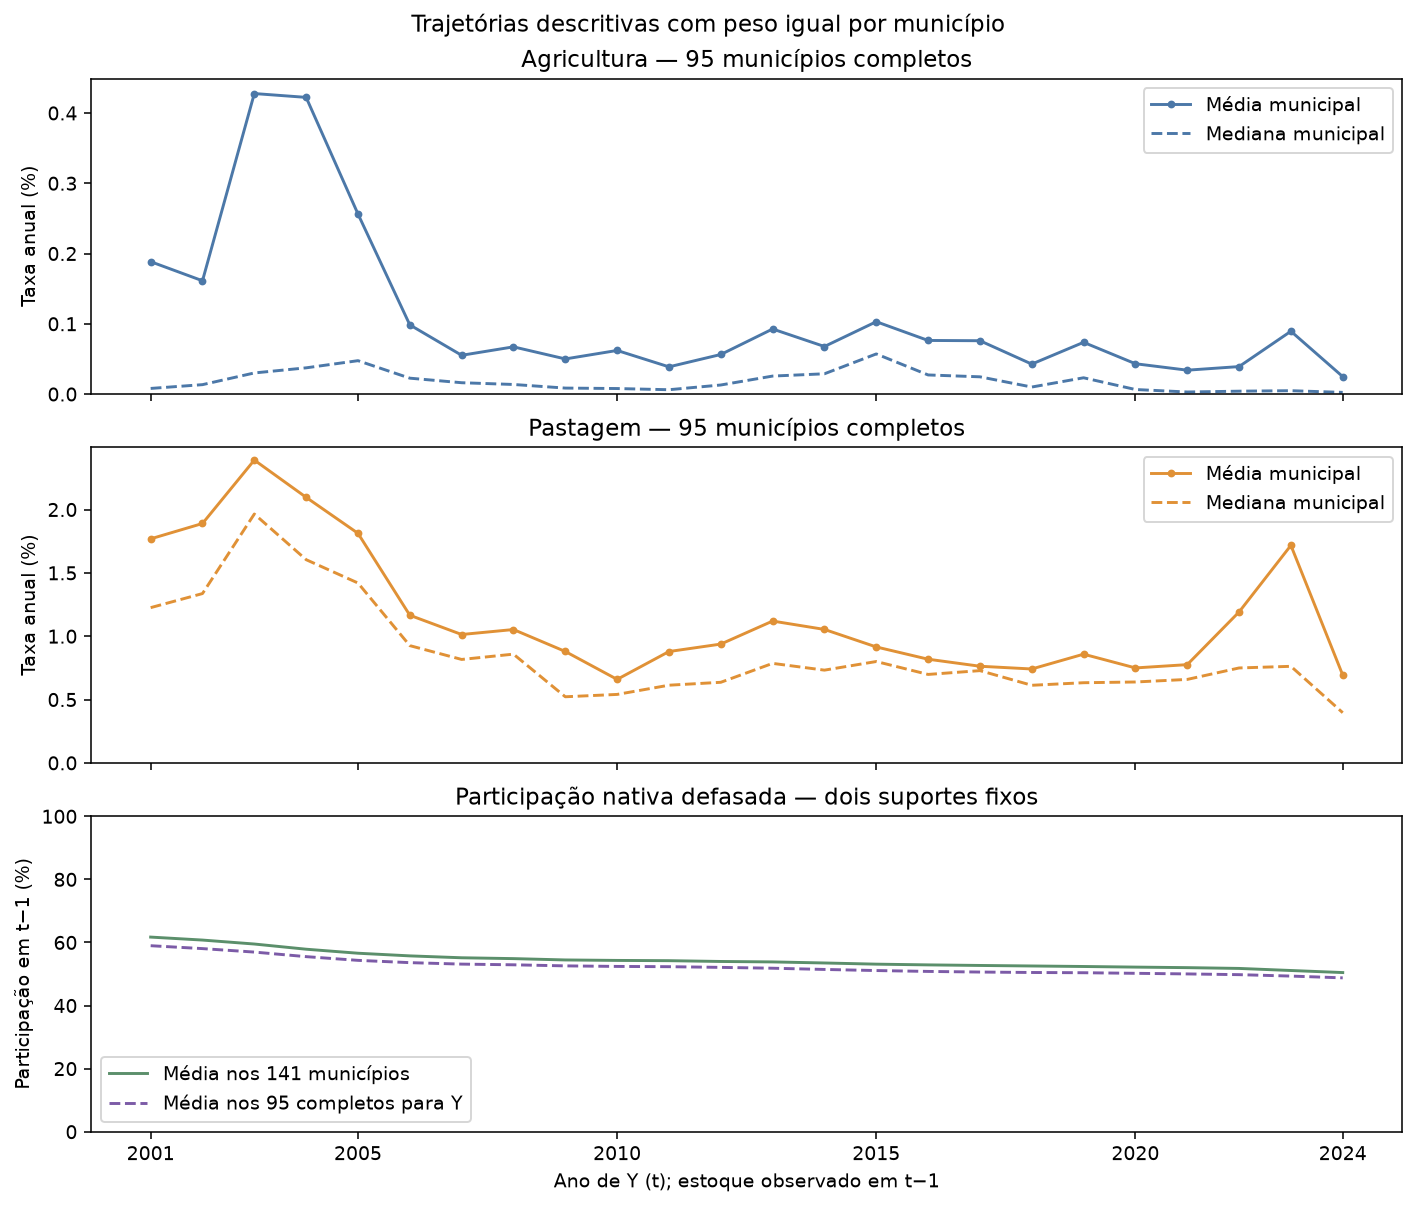

In [150]:
ytx_anual = ytx_completos.groupby('ano').agg(
    N_janela=('codigo_ibge', 'nunique'),
    agricultura_media=('taxa_conversao__agricultura', 'mean'),
    agricultura_mediana=('taxa_conversao__agricultura', 'median'),
    pastagem_media=('taxa_conversao__pastagem', 'mean'),
    pastagem_mediana=('taxa_conversao__pastagem', 'median'),
    nativa_share_95=('native_veg_share_lag1', 'mean'),
)
ytx_anual['N_Y_grade'] = ytx_validos.groupby('ano')['codigo_ibge'].nunique()
ytx_anual['N_share_grade'] = ytx_aed.groupby('ano')[ytx_share].count()
ytx_anual['nativa_share_141'] = ytx_aed.groupby('ano')[ytx_share].mean()
ytx_anual_pct = ytx_anual.copy()
ytx_cols_pct = ['agricultura_media', 'agricultura_mediana', 'pastagem_media',
                'pastagem_mediana', 'nativa_share_95', 'nativa_share_141']
ytx_anual_pct[ytx_cols_pct] *= 100
ytx_mostrar(ytx_anual_pct, casas=3)

fig, ytx_eixos = plt.subplots(3, 1, figsize=(10, 8.5), dpi=140, sharex=True, layout='constrained')
for ytx_eixo, ytx_destino in zip(ytx_eixos[:2], ytx_destinos):
    ytx_eixo.plot(ytx_anual_pct.index, ytx_anual_pct[f'{ytx_destino}_media'],
                  color=ytx_cores[ytx_destino], marker='o', markersize=3, label='Média municipal')
    ytx_eixo.plot(ytx_anual_pct.index, ytx_anual_pct[f'{ytx_destino}_mediana'],
                  color=ytx_cores[ytx_destino], linestyle='--', label='Mediana municipal')
    ytx_eixo.set(title=f'{ytx_rotulos[ytx_destino]} — {len(ytx_municipios_completos)} municípios completos',
                 ylabel='Taxa anual (%)', ylim=(0, None))
    ytx_eixo.legend(loc='upper right')
ytx_eixos[2].plot(ytx_anual_pct.index, ytx_anual_pct['nativa_share_141'],
                  color='#5b8f6b', label='Média nos 141 municípios')
ytx_eixos[2].plot(ytx_anual_pct.index, ytx_anual_pct['nativa_share_95'],
                  color='#7c5ba7', linestyle='--', label='Média nos 95 completos para Y')
ytx_eixos[2].set(title='Participação nativa defasada — dois suportes fixos',
                 ylabel='Participação em t−1 (%)', ylim=(0, 100), xlabel='Ano de Y (t); estoque observado em t−1')
ytx_eixos[2].legend(loc='lower left')
ytx_eixos[2].set_xticks([2001, 2005, 2010, 2015, 2020, 2024])
fig.suptitle('Trajetórias descritivas com peso igual por município')
plt.show()


Na seleção completa, as taxas médias atingem o máximo em 2003 e são menores em 2024 do que em 2001, com oscilações ao longo da série. A participação média nos 141 municípios passa de **61,70% para 50,46%**; nos 95 completos para Y, de **58,97% para 48,78%**, entre estoques de 2000 e 2023. A diferença entre suportes mantém visível a seleção de cobertura.

A redução da participação descreve composição do estoque; não equivale à soma das conversões brutas para os dois destinos. Regeneração, outros destinos e mudanças de classificação também podem diferenciar estoque e fluxo. As trajetórias não isolam os mecanismos de preços, capacidade produtiva e instituições previstos em H1.


###### Análise Multivariada


In [151]:
# Relações entre taxas, estoques, participação nativa e qualidade no mesmo suporte


**1. Os estoques candidatos são intercambiáveis com o denominador de Y?**

Comparam-se valores nas mesmas chaves. Define-se Δ = primeira coluna − segunda; o relativo usa a segunda como referência. A tolerância absoluta de **0,0001 ha, com rtol=0**, serve somente para distinguir diferenças numéricas nesta comparação; não define cobertura completa nem certifica identidade de máscara. A concordância entre os dois estoques candidatos é examinada na grade; a comparação com o denominador de Y distingue grade e suporte com taxa.


N comum  \
Suporte     Primeira − segunda                                  
Grade       nativa_ha_lag1 − native_veg_ha_lag1          3384   
            y_nativa_inicial_ha − native_veg_ha_lag1     3384   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1     2772   

                                                      Exatamente iguais  \
Suporte     Primeira − segunda                                            
Grade       nativa_ha_lag1 − native_veg_ha_lag1                    3305   
            y_nativa_inicial_ha − native_veg_ha_lag1                  0   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1                  0   

                                                      Dentro de 0,0001 ha  \
Suporte     Primeira − segunda                                              
Grade       nativa_ha_lag1 − native_veg_ha_lag1                      3384   
            y_nativa_inicial_ha − native_veg_ha_lag1                    0   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1                    0   

                                                      Mediana |Δ| (ha)  \
Suporte     Primeira − segunda                                           
Grade       nativa_ha_lag1 − native_veg_ha_lag1             0.00000000   
            y_nativa_inicial_ha − native_veg_ha_lag1        2.60382396   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1        2.64879290   

                                                      P95 |Δ| (ha)  \
Suporte     Primeira − segunda                                       
Grade       nativa_ha_lag1 − native_veg_ha_lag1         0.00000000   
            y_nativa_inicial_ha − native_veg_ha_lag1   32.73504335   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1   32.02311780   

                                                       Máx |Δ| (ha)  \
Suporte     Primeira − segunda                                        
Grade       nativa_ha_lag1 − native_veg_ha_lag1       4.6566129e-10   
            y_nativa_inicial_ha − native_veg_ha_lag1       162.6467   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1       162.6467   

                                                      Mediana |Δ relativo| (%)  \
Suporte     Primeira − segunda                                                   
Grade       nativa_ha_lag1 − native_veg_ha_lag1                     0.00000000   
            y_nativa_inicial_ha − native_veg_ha_lag1                0.00129725   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1                0.00148000   

                                                      Máx |Δ relativo| (%)  \
Suporte     Primeira − segunda                                               
Grade       nativa_ha_lag1 − native_veg_ha_lag1                 0.00000000   
            y_nativa_inicial_ha − native_veg_ha_lag1            0.04782749   
Y observado y_nativa_inicial_ha − native_veg_ha_lag1            0.03629776   

                                                       Spearman  
Suporte     Primeira − segunda                                   
Grade       nativa_ha_lag1 − native_veg_ha_lag1      1.00000000  
            y_nativa_inicial_ha − native_veg_ha_lag1 0.99999997  
Y observado y_nativa_inicial_ha − native_veg_ha_lag1 0.99999996

y_cobertura_completa  y_nativa_inicial_ha  \
codigo_ibge ano                                               
5106505     2022                  True     1,442,579.163724   
            2021                  True     1,432,747.175384   
            2024                  True     1,418,000.804948   
            2019                  True     1,334,856.996435   
            2023                  True     1,422,648.863347   

                  native_veg_ha_lag1    delta_ha  abs_delta_rel_pct  
codigo_ibge ano                                                      
5106505     2022    1,442,741.810429 -162.646705           0.011273  
            2021    1,432,905.417223 -158.241839           0.011043  
            2024    1,418,153.157733 -152.352785           0.010743  
            2019    1,335,008.169872 -151.173437           0.011324  
            2023    1,422,799.514525 -150.651178           0.010588

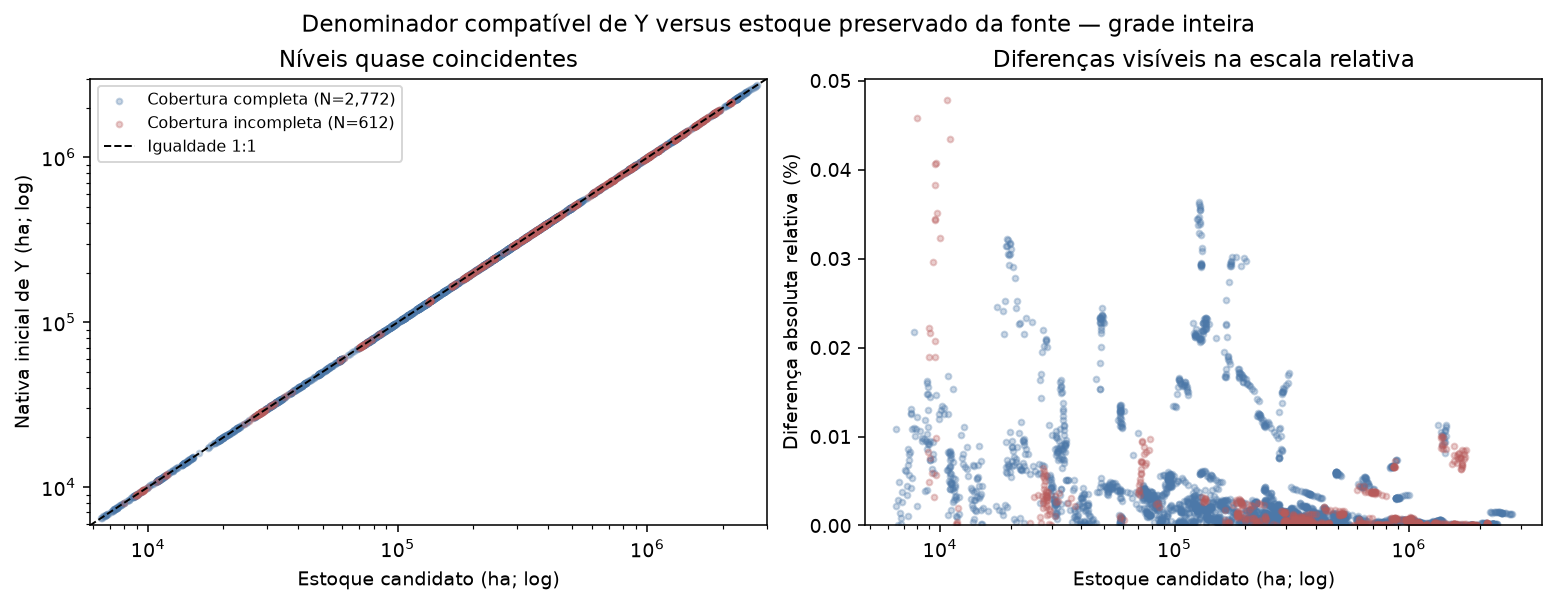

In [152]:
ytx_comparacoes_estoques = []
ytx_planos_comparacao = [
    ('Grade', ytx_aed, 'nativa_ha_lag1', 'native_veg_ha_lag1'),
    ('Grade', ytx_aed, 'y_nativa_inicial_ha', 'native_veg_ha_lag1'),
    ('Y observado', ytx_validos, 'y_nativa_inicial_ha', 'native_veg_ha_lag1'),
]
for ytx_suporte_nome, ytx_base, ytx_primeiro, ytx_segundo in ytx_planos_comparacao:
    ytx_par = ytx_base[[ytx_primeiro, ytx_segundo]].dropna()
    ytx_delta = ytx_par[ytx_primeiro] - ytx_par[ytx_segundo]
    ytx_relativo = 100 * ytx_delta.abs() / ytx_par[ytx_segundo].replace(0, np.nan)
    ytx_comparacoes_estoques.append({
        'Suporte': ytx_suporte_nome, 'Primeira − segunda': f'{ytx_primeiro} − {ytx_segundo}',
        'N comum': len(ytx_par), 'Exatamente iguais': int(ytx_delta.eq(0).sum()),
        'Dentro de 0,0001 ha': int(np.isclose(ytx_par[ytx_primeiro], ytx_par[ytx_segundo], atol=1e-4, rtol=0).sum()),
        'Mediana |Δ| (ha)': ytx_delta.abs().median(), 'P95 |Δ| (ha)': ytx_delta.abs().quantile(.95),
        'Máx |Δ| (ha)': f'{ytx_delta.abs().max():.8g}',
        'Mediana |Δ relativo| (%)': ytx_relativo.median(), 'Máx |Δ relativo| (%)': ytx_relativo.max(),
        'Spearman': ytx_par.corr(method='spearman').iloc[0, 1],
    })
ytx_comparacoes_estoques = pd.DataFrame(ytx_comparacoes_estoques).set_index(['Suporte', 'Primeira − segunda'])
ytx_mostrar(ytx_comparacoes_estoques, casas=8)

ytx_acordo = ytx_aed.copy()
ytx_acordo['delta_ha'] = ytx_acordo['y_nativa_inicial_ha'] - ytx_acordo['native_veg_ha_lag1']
ytx_acordo['abs_delta_rel_pct'] = 100 * ytx_acordo['delta_ha'].abs() / ytx_acordo['native_veg_ha_lag1']
ytx_maiores_diferencas = ytx_acordo.loc[ytx_acordo['delta_ha'].abs().nlargest(5).index,
    ['codigo_ibge', 'ano', 'y_cobertura_completa', 'y_nativa_inicial_ha', 'native_veg_ha_lag1', 'delta_ha', 'abs_delta_rel_pct']]
ytx_mostrar(ytx_maiores_diferencas.set_index(['codigo_ibge', 'ano']), casas=6)

fig, ytx_eixos = plt.subplots(1, 2, figsize=(11, 4.2), dpi=140, layout='constrained')
for ytx_estado, ytx_cor, ytx_rotulo in [(True, '#4c78a8', 'Cobertura completa'), (False, '#b85b5b', 'Cobertura incompleta')]:
    ytx_trecho = ytx_acordo.loc[ytx_acordo['y_cobertura_completa'].eq(ytx_estado)]
    ytx_eixos[0].scatter(ytx_trecho['native_veg_ha_lag1'], ytx_trecho['y_nativa_inicial_ha'],
                         s=9, alpha=.3, color=ytx_cor, label=f'{ytx_rotulo} (N={len(ytx_trecho):,})')
    ytx_eixos[1].scatter(ytx_trecho['native_veg_ha_lag1'], ytx_trecho['abs_delta_rel_pct'],
                         s=9, alpha=.3, color=ytx_cor)
ytx_limites = [ytx_acordo[ytx_estoques].min().min() * .9, ytx_acordo[ytx_estoques].max().max() * 1.1]
ytx_eixos[0].plot(ytx_limites, ytx_limites, color='black', linestyle='--', linewidth=1, label='Igualdade 1:1')
ytx_eixos[0].set(xscale='log', yscale='log', xlim=ytx_limites, ylim=ytx_limites,
                 xlabel='Estoque candidato (ha; log)', ylabel='Nativa inicial de Y (ha; log)', title='Níveis quase coincidentes')
ytx_eixos[0].legend(fontsize=8)
ytx_eixos[1].set(xscale='log', xlabel='Estoque candidato (ha; log)', ylabel='Diferença absoluta relativa (%)',
                 ylim=(0, None), title='Diferenças visíveis na escala relativa')
fig.suptitle('Denominador compatível de Y versus estoque preservado da fonte — grade inteira')
plt.show()


`nativa_ha_lag1` e `native_veg_ha_lag1` são numericamente equivalentes: **3.305 igualdades exatas**, todos os 3.384 pares dentro da tolerância e diferença máxima de **4,66 × 10⁻¹⁰ ha**. Carregar ambos como regressores repetiria praticamente a mesma informação.

Já `y_nativa_inicial_ha` difere do estoque candidato em todos os pares: na grade, a mediana de |Δ| é **2,60 ha**, o máximo **162,65 ha** e o maior desvio relativo **0,04783%**. A proximidade dos níveis e a correlação de ordenação quase unitária não demonstram identidade espacial. A fórmula fluxo / `y_nativa_inicial_ha` reproduz as taxas observadas na tolerância conferida; o estoque candidato não deve substituir esse denominador sem harmonização. A disponibilidade adicional do estoque não recupera o numerador ausente.


**2. Como qualidade de cobertura e disponibilidade das taxas se cruzam?**

A contingência distingue cobertura do par de mapas e disponibilidade conjunta das duas taxas. Os percentuais são por linha. As flags de denominador já foram descritas separadamente; todas são falsas na grade atual, o que não implica disponibilidade de Y.


In [153]:
ytx_disponibilidade = ytx_aed[ytx_taxas].notna().all(axis=1).map({True: 'Taxas observadas', False: 'Taxas ausentes'})
ytx_cobertura_rotulo = ytx_aed['y_cobertura_completa'].map({True: 'Cobertura completa', False: 'Cobertura incompleta'})
ytx_contingencia = pd.crosstab(ytx_cobertura_rotulo, ytx_disponibilidade).reindex(
    index=['Cobertura completa', 'Cobertura incompleta'], columns=['Taxas observadas', 'Taxas ausentes'], fill_value=0)
display(ytx_contingencia)
ytx_mostrar(100 * ytx_contingencia.div(ytx_contingencia.sum(axis=1), axis=0), casas=1)

ytx_qualidade_suporte = ytx_aed.assign(Disponibilidade=ytx_disponibilidade).groupby('Disponibilidade').agg(
    pares=('ano', 'size'), municipios=('codigo_ibge', 'nunique'),
    estoque_candidato_observado=('native_veg_ha_lag1', 'count'),
    participacao_nativa_media=('native_veg_share_lag1', 'mean'),
)
ytx_qualidade_suporte['participacao_nativa_media'] *= 100
ytx_qualidade_suporte = ytx_qualidade_suporte.rename(columns={'participacao_nativa_media': 'Participação nativa média (%)'})
ytx_mostrar(ytx_qualidade_suporte)


col_0,Taxas observadas,Taxas ausentes
y_cobertura_completa,,
Cobertura completa,2772,0
Cobertura incompleta,0,612


col_0,Taxas observadas,Taxas ausentes
y_cobertura_completa,,
Cobertura completa,100.0,0.0
Cobertura incompleta,0.0,100.0


,pares,municipios,estoque_candidato_observado,Participação nativa média (%)
Disponibilidade,,,,
Taxas ausentes,612,46,612,57.752
Taxas observadas,2772,137,2772,53.763


As **612 ausências** coincidem com cobertura incompleta do par de mapas, embora os estoques sejam positivos e observados. O estoque legado e a participação nativa podem ser descritos nessas linhas, mas não permitem imputar taxa zero nem recuperar conversões. A participação média difere entre pares com e sem taxa (aproximadamente **53,76% e 57,75%**), sinalizando composição distinta do suporte; isso não é um teste de seleção aleatória. Flags e metadados são diagnósticos de qualidade, não controles institucionais de H1.


**3. A relação entre destinos muda com a participação nativa e o período?**

Esta exploração conjunta usa os mesmos municípios completos, com as duas taxas nos eixos, a participação nativa defasada na cor e três intervalos de oito anos nas facetas. Os intervalos 2001–2008, 2009–2016 e 2017–2024 organizam a visualização; não representam regimes econômicos predefinidos. Eixos e escala de cor são comuns. As relações entre resultados e disponibilidade de vegetação são internas à construção das medidas; não estimam os determinantes de H1.


,pares,municipios,primeiro_ano,ultimo_ano,Participação mínima (%),Participação máxima (%)
Período,,,,,,
2001–2008,760,95,2001,2008,11.349,97.905
2009–2016,760,95,2009,2016,9.711,92.326
2017–2024,760,95,2017,2024,7.274,92.263


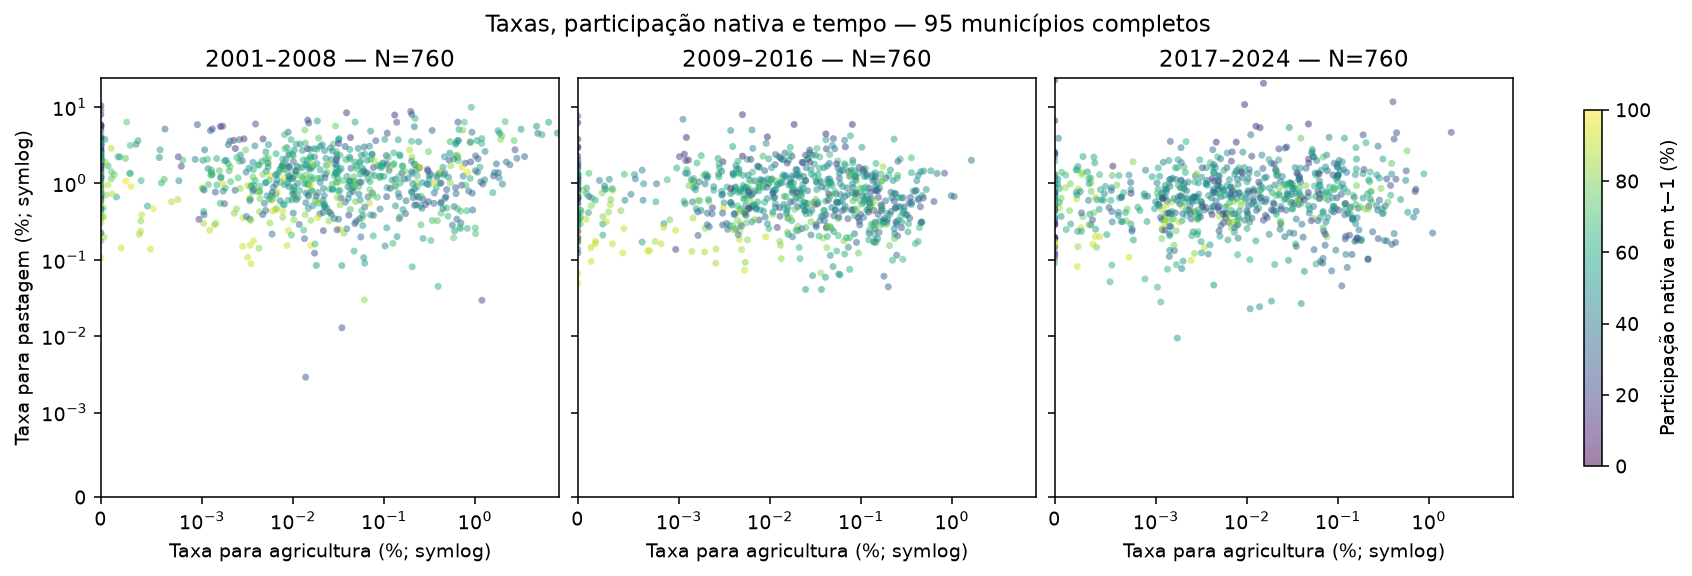

In [154]:
ytx_contexto = ytx_completos.dropna(subset=ytx_taxas + [ytx_share]).copy()
ytx_contexto['Período'] = pd.cut(ytx_contexto['ano'], bins=[2000, 2008, 2016, 2024],
                                labels=['2001–2008', '2009–2016', '2017–2024'], right=True)
ytx_suporte_facetas = ytx_contexto.groupby('Período', observed=True).agg(
    pares=('ano', 'size'), municipios=('codigo_ibge', 'nunique'),
    primeiro_ano=('ano', 'min'), ultimo_ano=('ano', 'max'),
    share_min=('native_veg_share_lag1', 'min'), share_max=('native_veg_share_lag1', 'max'),
)
ytx_suporte_facetas[['share_min', 'share_max']] *= 100
ytx_mostrar(ytx_suporte_facetas.rename(columns={'share_min': 'Participação mínima (%)', 'share_max': 'Participação máxima (%)'}))

fig, ytx_eixos = plt.subplots(1, 3, figsize=(12, 4), dpi=140, sharex=True, sharey=True, layout='constrained')
ytx_norma = plt.Normalize(0, 100)
for ytx_eixo, ytx_periodo in zip(ytx_eixos, ['2001–2008', '2009–2016', '2017–2024']):
    ytx_trecho = ytx_contexto.loc[ytx_contexto['Período'].eq(ytx_periodo)]
    ytx_pontos = ytx_eixo.scatter(ytx_trecho[ytx_taxas[0]] * 100, ytx_trecho[ytx_taxas[1]] * 100,
                                 c=ytx_trecho[ytx_share] * 100, cmap='viridis', norm=ytx_norma,
                                 s=13, alpha=.5, linewidths=0)
    ytx_eixo.set_xscale('symlog', linthresh=.001)
    ytx_eixo.set_yscale('symlog', linthresh=.001)
    ytx_eixo.set(xlim=(0, ytx_contexto[ytx_taxas[0]].max() * 105),
                 ylim=(0, ytx_contexto[ytx_taxas[1]].max() * 105),
                 xlabel='Taxa para agricultura (%; symlog)', title=f'{ytx_periodo} — N={len(ytx_trecho):,}')
ytx_eixos[0].set_ylabel('Taxa para pastagem (%; symlog)')
fig.colorbar(ytx_pontos, ax=ytx_eixos, label='Participação nativa em t−1 (%)', shrink=.85)
fig.suptitle('Taxas, participação nativa e tempo — 95 municípios completos')
plt.show()


As facetas permitem inspecionar a dispersão dos destinos junto com composição nativa e tempo, sem impor reta ou agrupamento econômico. Cada painel contém **760 pares dos mesmos 95 municípios**. Os dois resultados compartilham o denominador de Y; a participação também deriva de estoque nativo, mas com área total mapeada na fonte. Essa ligação de construção, as tendências comuns e a seleção dos municípios impedem atribuir significado causal às nuvens ou às cores.


**4. As associações de ordenação dependem do suporte e da dimensão do painel?**

Spearman resume associação monotônica, apropriada aqui como complemento diante da assimetria e dos empates em zero. Primeiro mostram-se os três coeficientes internos e o N por par; depois separam-se pares empilhados, médias por município e desvios em relação à média municipal, nos mesmos municípios completos. Correlação dos desvios é apenas diagnóstico descritivo; não corresponde à estimação do modelo com efeitos fixos de H1. Constantes teriam correlação indefinida.


In [155]:
ytx_cols_relacoes = ytx_taxas + [ytx_share]
ytx_rotulos_relacoes = {
    ytx_taxas[0]: 'Taxa agricultura', ytx_taxas[1]: 'Taxa pastagem', ytx_share: 'Participação nativa t−1',
}
ytx_relacoes = ytx_aed[ytx_cols_relacoes]
ytx_corr = ytx_relacoes.corr(method='spearman').rename(index=ytx_rotulos_relacoes, columns=ytx_rotulos_relacoes)
ytx_n_por_par = ytx_relacoes.notna().astype(int).T.dot(ytx_relacoes.notna().astype(int))
ytx_n_por_par = ytx_n_por_par.rename(index=ytx_rotulos_relacoes, columns=ytx_rotulos_relacoes)
ytx_mostrar(ytx_corr, casas=4)
display(ytx_n_por_par)

# Cada comparação usa somente as três medidas necessárias, conservando zeros.
ytx_painel_comum = ytx_completos.dropna(subset=ytx_cols_relacoes).copy()
ytx_entre = ytx_painel_comum.groupby('codigo_ibge', observed=True)[ytx_cols_relacoes].mean()
ytx_dentro = ytx_painel_comum[ytx_cols_relacoes] - ytx_painel_comum.groupby('codigo_ibge', observed=True)[ytx_cols_relacoes].transform('mean')
ytx_planos_relacoes = [
    ('Empilhada: todos os pares comuns', ytx_validos[ytx_cols_relacoes].dropna(), ytx_validos['codigo_ibge'].nunique()),
    ('Empilhada: municípios completos', ytx_painel_comum[ytx_cols_relacoes], ytx_painel_comum['codigo_ibge'].nunique()),
    ('Entre: médias dos municípios completos', ytx_entre, len(ytx_entre)),
    ('Dentro: desvios da média municipal', ytx_dentro, ytx_painel_comum['codigo_ibge'].nunique()),
]
ytx_contraste_painel = []
for ytx_nome, ytx_base, ytx_n_mun in ytx_planos_relacoes:
    ytx_matriz = ytx_base.corr(method='spearman')
    ytx_contraste_painel.append({
        'Dimensão': ytx_nome, 'N unidades no cálculo': len(ytx_base), 'Municípios': ytx_n_mun,
        'Agricultura × pastagem': ytx_matriz.loc[ytx_taxas[0], ytx_taxas[1]],
        'Agricultura × participação': ytx_matriz.loc[ytx_taxas[0], ytx_share],
        'Pastagem × participação': ytx_matriz.loc[ytx_taxas[1], ytx_share],
    })
ytx_contraste_painel = pd.DataFrame(ytx_contraste_painel).set_index('Dimensão')
ytx_mostrar(ytx_contraste_painel, casas=4)


,Taxa agricultura,Taxa pastagem,Participação nativa t−1
Taxa agricultura,1.0000,0.0607,-0.0952
Taxa pastagem,0.0607,1.0000,-0.1071
Participação nativa t−1,-0.0952,-0.1071,1.0000


,Taxa agricultura,Taxa pastagem,Participação nativa t−1
Taxa agricultura,2772,2772,2772
Taxa pastagem,2772,2772,2772
Participação nativa t−1,2772,2772,3384


,N unidades no cálculo,Municípios,Agricultura × pastagem,Agricultura × participação,Pastagem × participação
Dimensão,,,,,
Empilhada: todos os pares comuns,2772,137,0.0607,-0.0952,-0.1071
Empilhada: municípios completos,2280,95,0.0403,-0.0871,-0.0986
Entre: médias dos municípios completos,95,95,-0.0621,-0.1884,-0.2868
Dentro: desvios da média municipal,2280,95,0.2750,0.2174,0.4216


Nos **2.772 pares comuns**, Spearman é aproximadamente **0,061 entre taxas**, **−0,095 entre taxa agrícola e participação nativa** e **−0,107 entre taxa de pastagem e participação**: associações empilhadas fracas, que não excluem heterogeneidade ou relações não lineares. Nos 95 municípios completos, as associações das taxas com a participação são negativas entre médias municipais (**−0,188 e −0,287**) e positivas entre desvios às médias (**0,217 e 0,422**). A mudança de sinal mostra por que as dimensões territorial e temporal precisam ser distinguidas; não implica efeito causal da participação.

Essas relações não selecionam, isoladamente, controles para H1. A participação defasada pode representar disponibilidade relativa de vegetação e dialoga com X5, mas estoque em t−1 não garante exogeneidade. Preços, capacidade produtiva e instituições exigem seus próprios recortes, cobertura conjunta e desenho econométrico; não foram incorporados artificialmente a esta etapa.


###### Síntese


In [156]:
# Justificativa, alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** Conforme o desenho prévio, o catálogo e a introdução, as melhores candidatas deste bloco são as duas taxas, como resultados separados de intensidade de conversão. Recomenda-se o seguinte encaminhamento para a comparação de especificações preliminares:

| Colunas | Papel no catálogo | Encaminhamento |
|---|---|---|
| `taxa_conversao__agricultura` e `taxa_conversao__pastagem` | G1; medidas diretas e principais de Y_tx-conv | Priorizar como variáveis dependentes separadas, preservando zeros válidos. |
| `conversao_ha__agricultura` e `conversao_ha__pastagem` | G1; insumos secundários aqui, principais em Y_conv | Manter os numeradores; considerar hectares como representação alternativa de magnitude física, sem tratar hectares e taxas como resultados independentes. |
| `y_nativa_inicial_ha` | G1; insumo principal, também associado a X5 | Preservar o denominador compatível com as transições. Sua função na taxa não justifica inclusão automática como controle exógeno. |
| `nativa_ha_lag1` e `native_veg_ha_lag1` | G1; insumos secundários, também associados a X5 | Preservar ambos na base; na seleção futura, considerar no máximo um representante dessa informação redundante, condicionado à adequação territorial e de mensuração. Não substituir automaticamente o denominador de Y. |
| `native_veg_share_lag1` | G1; insumo secundário, também associado a X5 | Candidata a disponibilidade relativa de vegetação, mediante validação territorial histórica, da máscara, temporalidade e papel na especificação. Não é taxa de conversão nem denominador em ha; defasagem não assegura exogeneidade. |
| Flags, áreas de cobertura, coleção, malha e máscara | G4; qualidade e proveniência | Conservar para elegibilidade e rastreabilidade; não selecionar automaticamente como regressores substantivos ou medidas institucionais. |

`codigo_ibge` e `ano` identificam o painel. A escolha da amostra e da especificação permanece em aberto.

**Intuição e indícios.** A pastagem apresenta taxas médias e medianas superiores às agrícolas; ambos os destinos têm caudas à direita, com 265 zeros agrícolas válidos. A participação nativa média diminui nos dois suportes fixos, descrevendo estoque remanescente, sem equivaler a conversão bruta acumulada. Os dois estoques candidatos repetem praticamente a mesma informação e diferem, ainda que pouco em termos relativos, do denominador compatível de Y. As associações empilhadas entre taxas e participação são fracas; nos municípios completos, o sinal muda entre médias municipais e desvios às médias, recomendando distinguir variação territorial e temporal.

**Suporte e alcance.** As taxas têm 2.772 pares válidos em 137 municípios e 612 ausentes (18,09% da grade). Os estoques e a participação têm 3.384 valores; essa disponibilidade não recupera as transições ausentes. Os 95 municípios completos são uma seleção descritiva, não a amostra final. Esses indícios orientam escolhas e validações; sem cobertura conjunta com preços, capacidade produtiva e instituições e uma estratégia empírica, não testam nem confirmam H1.


---

#### 2.2 X1 (Preços agropecuários)

##### --- (c) x1_psoja-pmilho ---

Identificador Python: `x1_psoja_pmilho`. 58 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

###### Criar


In [157]:
# Recorte fiel, preservando a base


In [158]:
x1_psoja_pmilho = df1.loc[:, chaves_yx + [
    'preco_nominal_media_anual__milho',
    'preco_nominal_media_anual__soja',
    'preco_real_usd2024_media_anual__milho',
    'preco_real_usd2024_media_anual__soja',
    'flag_ano_nominal_incompleto__milho',
    'flag_ano_nominal_incompleto__soja',
    'flag_ano_real_incompleto__milho',
    'flag_ano_real_incompleto__soja',
    'ln_preco_nominal_media_anual__milho',
    'ln_preco_nominal_media_anual__soja',
    'ln_preco_real_usd2024_media_anual__milho',
    'ln_preco_real_usd2024_media_anual__soja',
    'preco_nominal_media_anual_lag1__milho',
    'preco_nominal_media_anual_lag1__soja',
    'preco_real_usd2024_media_anual_lag1__milho',
    'preco_real_usd2024_media_anual_lag1__soja',
    'ln_preco_nominal_media_anual_lag1__milho',
    'ln_preco_nominal_media_anual_lag1__soja',
    'ln_preco_real_usd2024_media_anual_lag1__milho',
    'ln_preco_real_usd2024_media_anual_lag1__soja',
    'dln_preco_nominal_media_anual__milho',
    'dln_preco_nominal_media_anual__soja',
    'dln_preco_real_usd2024_media_anual__milho',
    'dln_preco_real_usd2024_media_anual__soja',
    'dln_preco_nominal_media_anual_lag1__milho',
    'dln_preco_nominal_media_anual_lag1__soja',
    'dln_preco_real_usd2024_media_anual_lag1__milho',
    'dln_preco_real_usd2024_media_anual_lag1__soja',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()
x1_psoja_pmilho.head()

,codigo_ibge,ano,preco_nominal_media_anual__milho,preco_nominal_media_anual__soja,preco_real_usd2024_media_anual__milho,preco_real_usd2024_media_anual__soja,flag_ano_nominal_incompleto__milho,flag_ano_nominal_incompleto__soja,flag_ano_real_incompleto__milho,flag_ano_real_incompleto__soja,...,exposicao_real_x_pantanal__milho__pam_1991_2000_min7,exposicao_real_x_pantanal__soja__pam_1991_2000_min7,exposicao_real_x_pantanal__milho__gaez_sxHr0_mze,exposicao_real_x_pantanal__soja__gaez_sxHr0_soy,exposicao_real_x_pantanal__milho__gaez_sxLr0_mze,exposicao_real_x_pantanal__soja__gaez_sxLr0_soy,exposicao_real_x_pantanal__milho__gaez_yxHr0_mze,exposicao_real_x_pantanal__soja__gaez_yxHr0_soy,exposicao_real_x_pantanal__milho__gaez_yxLr0_mze,exposicao_real_x_pantanal__soja__gaez_yxLr0_soy
0,5100102,2001,89.650000,195.833333,158.846629,346.971098,False,False,False,False,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
1,5100102,2002,99.266667,212.666667,173.033395,370.666009,False,False,False,False,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
2,5100102,2003,105.383333,264.000000,179.708739,450.062197,False,False,False,False,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
3,5100102,2004,111.791667,306.500000,185.817628,509.724749,False,False,False,False,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
4,5100102,2005,98.675000,274.750000,158.498215,441.478479,False,False,False,False,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0


In [159]:
x1_psoja_pmilho.columns.tolist()


['codigo_ibge',
 'ano',
 'preco_nominal_media_anual__milho',
 'preco_nominal_media_anual__soja',
 'preco_real_usd2024_media_anual__milho',
 'preco_real_usd2024_media_anual__soja',
 'flag_ano_nominal_incompleto__milho',
 'flag_ano_nominal_incompleto__soja',
 'flag_ano_real_incompleto__milho',
 'flag_ano_real_incompleto__soja',
 'ln_preco_nominal_media_anual__milho',
 'ln_preco_nominal_media_anual__soja',
 'ln_preco_real_usd2024_media_anual__milho',
 'ln_preco_real_usd2024_media_anual__soja',
 'preco_nominal_media_anual_lag1__milho',
 'preco_nominal_media_anual_lag1__soja',
 'preco_real_usd2024_media_anual_lag1__milho',
 'preco_real_usd2024_media_anual_lag1__soja',
 'ln_preco_nominal_media_anual_lag1__milho',
 'ln_preco_nominal_media_anual_lag1__soja',
 'ln_preco_real_usd2024_media_anual_lag1__milho',
 'ln_preco_real_usd2024_media_anual_lag1__soja',
 'dln_preco_nominal_media_anual__milho',
 'dln_preco_nominal_media_anual__soja',
 'dln_preco_real_usd2024_media_anual__milho',
 'dln_preco_r

In [160]:
## Colunas 2_INTI\chapters\chap1\stats\EDA\aed_chap1_pt_DICIO.ipynb

# Fonte: bloco "## df" do DICIO; as 60 definições abaixo foram preservadas literalmente.
# Numeração original do dicionário df preservada.
# Os números indicam a posição na origem, não a posição neste recorte.
# Recorte: 2 chaves, 24 medidas anuais de preços, 4 flags, 10 interações e 20 exposições por bioma.

# Notas de leitura e construção:
# - t é o ano de referência da linha; lag1 usa t−1. Os preços são comuns aos municípios em cada ano.
# - Preço real: deflação de cada preço mensal pelo CPI-U dos EUA, com referência na média dos
#   índices mensais de 2024; em seguida, média dos 12 preços mensais deflacionados.
# - ln é o log natural da média anual; nas interações, usa-se ln do preço médio anual real de t−1.
# - dln compara ln(P_t) e ln(P_t−1); dln_lag1 compara ln(P_t−1) e ln(P_t−2).
#   A diferença de logs é adimensional; a variação percentual exata é 100 × (exp(dln) − 1).
# - Flag de ano incompleto: True quando não há simultaneamente 12 meses registrados e
#   12 preços válidos na base nominal ou real correspondente; False quando esse requisito é atendido.
# - z = (capacidade − média) / desvio-padrão amostral (ddof=1), calculado entre municípios
#   com informação válida, separadamente por produto e cenário. A capacidade é fixa no painel;
#   a interação varia anualmente com o preço. As frações de bioma são fixas por município.

#1 - codigo_ibge: Código identificador do município | código IBGE de 7 dígitos | municipal (141 municípios de MT).

#2 - ano: Ano de referência da observação (2001–2024) | ano civil | temporal, comum à grade municipal.

#19 - preco_nominal_media_anual__milho: Preço nominal de milho: média dos 12 meses de t | US$ correntes/t | internacional; série anual comum a todos os municípios.

#20 - preco_nominal_media_anual__soja: Preço nominal de soja: média dos 12 meses de t | US$ correntes/t | internacional; série anual comum a todos os municípios.

#22 - preco_real_usd2024_media_anual__milho: Preço real (CPI-U, base média de 2024) de milho: média dos 12 meses de t | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#23 - preco_real_usd2024_media_anual__soja: Preço real (CPI-U, base média de 2024) de soja: média dos 12 meses de t | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#25 - flag_ano_nominal_incompleto__milho: Indica menos de 12 meses registrados/válidos de preço nominal de milho | booleano (True/False) | internacional; série anual comum a todos os municípios.

#26 - flag_ano_nominal_incompleto__soja: Indica menos de 12 meses registrados/válidos de preço nominal de soja | booleano (True/False) | internacional; série anual comum a todos os municípios.

#28 - flag_ano_real_incompleto__milho: Indica menos de 12 meses registrados/válidos de preço real (CPI-U, base média de 2024) de milho | booleano (True/False) | internacional; série anual comum a todos os municípios.

#29 - flag_ano_real_incompleto__soja: Indica menos de 12 meses registrados/válidos de preço real (CPI-U, base média de 2024) de soja | booleano (True/False) | internacional; série anual comum a todos os municípios.

#31 - ln_preco_nominal_media_anual__milho: Log natural do preço médio anual nominal de milho em t | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#32 - ln_preco_nominal_media_anual__soja: Log natural do preço médio anual nominal de soja em t | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#34 - ln_preco_real_usd2024_media_anual__milho: Log natural do preço médio anual real (CPI-U, base média de 2024) de milho em t | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#35 - ln_preco_real_usd2024_media_anual__soja: Log natural do preço médio anual real (CPI-U, base média de 2024) de soja em t | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#37 - preco_nominal_media_anual_lag1__milho: Preço nominal de milho: média dos 12 meses de t−1 | US$ correntes/t | internacional; série anual comum a todos os municípios.

#38 - preco_nominal_media_anual_lag1__soja: Preço nominal de soja: média dos 12 meses de t−1 | US$ correntes/t | internacional; série anual comum a todos os municípios.

#40 - preco_real_usd2024_media_anual_lag1__milho: Preço real (CPI-U, base média de 2024) de milho: média dos 12 meses de t−1 | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#41 - preco_real_usd2024_media_anual_lag1__soja: Preço real (CPI-U, base média de 2024) de soja: média dos 12 meses de t−1 | US$ de 2024/t | internacional; série anual comum a todos os municípios.

#43 - ln_preco_nominal_media_anual_lag1__milho: Log natural do preço médio anual nominal de milho em t−1 | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#44 - ln_preco_nominal_media_anual_lag1__soja: Log natural do preço médio anual nominal de soja em t−1 | log do valor na unidade US$ correntes/t | internacional; série anual comum a todos os municípios.

#46 - ln_preco_real_usd2024_media_anual_lag1__milho: Log natural do preço médio anual real (CPI-U, base média de 2024) de milho em t−1 | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#47 - ln_preco_real_usd2024_media_anual_lag1__soja: Log natural do preço médio anual real (CPI-U, base média de 2024) de soja em t−1 | log do valor na unidade US$ de 2024/t | internacional; série anual comum a todos os municípios.

#49 - dln_preco_nominal_media_anual__milho: Variação do log do preço médio anual nominal de milho entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#50 - dln_preco_nominal_media_anual__soja: Variação do log do preço médio anual nominal de soja entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#52 - dln_preco_real_usd2024_media_anual__milho: Variação do log do preço médio anual real (CPI-U, base média de 2024) de milho entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#53 - dln_preco_real_usd2024_media_anual__soja: Variação do log do preço médio anual real (CPI-U, base média de 2024) de soja entre t e t−1 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#55 - dln_preco_nominal_media_anual_lag1__milho: Variação do log do preço médio anual nominal de milho entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#56 - dln_preco_nominal_media_anual_lag1__soja: Variação do log do preço médio anual nominal de soja entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#58 - dln_preco_real_usd2024_media_anual_lag1__milho: Variação do log do preço médio anual real (CPI-U, base média de 2024) de milho entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#59 - dln_preco_real_usd2024_media_anual_lag1__soja: Variação do log do preço médio anual real (CPI-U, base média de 2024) de soja entre t−1 e t−2 | diferença logarítmica (adimensional) | internacional; série anual comum a todos os municípios.

#118 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) | índice de interação (adimensional) | municipal (MT), anual.

#119 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) | índice de interação (adimensional) | municipal (MT), anual.

#120 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#121 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#122 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#123 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#124 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#125 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#126 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#127 - interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro | índice de interação (adimensional) | municipal (MT), anual.

#277 - exposicao_real_x_cerrado__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#278 - exposicao_real_x_cerrado__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#279 - exposicao_real_x_cerrado__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#280 - exposicao_real_x_cerrado__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#281 - exposicao_real_x_cerrado__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#282 - exposicao_real_x_cerrado__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#283 - exposicao_real_x_cerrado__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#284 - exposicao_real_x_cerrado__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#285 - exposicao_real_x_cerrado__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#286 - exposicao_real_x_cerrado__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Cerrado | índice de interação (adimensional) | municipal (MT), anual.

#287 - exposicao_real_x_pantanal__milho__pam_1991_2000_min7: Log do preço real de milho em t−1 × z de rendimento de milho PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#288 - exposicao_real_x_pantanal__soja__pam_1991_2000_min7: Log do preço real de soja em t−1 × z de rendimento de soja PAM médio de 1991–2000 (mínimo 7 anos válidos) × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#289 - exposicao_real_x_pantanal__milho__gaez_sxHr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#290 - exposicao_real_x_pantanal__soja__gaez_sxHr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#291 - exposicao_real_x_pantanal__milho__gaez_sxLr0_mze: Log do preço real de milho em t−1 × z de aptidão de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#292 - exposicao_real_x_pantanal__soja__gaez_sxLr0_soy: Log do preço real de soja em t−1 × z de aptidão de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#293 - exposicao_real_x_pantanal__milho__gaez_yxHr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#294 - exposicao_real_x_pantanal__soja__gaez_yxHr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo alto, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#295 - exposicao_real_x_pantanal__milho__gaez_yxLr0_mze: Log do preço real de milho em t−1 × z de rendimento potencial de milho GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.

#296 - exposicao_real_x_pantanal__soja__gaez_yxLr0_soy: Log do preço real de soja em t−1 × z de rendimento potencial de soja GAEZ, insumo baixo, sequeiro × fração de Pantanal | índice de interação (adimensional) | municipal (MT), anual.


###### Estrutura


In [161]:
# Dimensões, tipos, chaves e domínios


In [162]:
x1_psoja_pmilho.shape


(3384, 60)

In [163]:
x1_psoja_pmilho.info(verbose=True, show_counts=True)


<class 'pandas.DataFrame'>
RangeIndex: 3384 entries, 0 to 3383
Data columns (total 60 columns):
 #   Column                                                                                    Non-Null Count  Dtype        
---  ------                                                                                    --------------  -----        
 0   codigo_ibge                                                                               3384 non-null   category     
 1   ano                                                                                       3384 non-null   period[Y-DEC]
 2   preco_nominal_media_anual__milho                                                          3384 non-null   float64      
 3   preco_nominal_media_anual__soja                                                           3384 non-null   float64      
 4   preco_real_usd2024_media_anual__milho                                                     3384 non-null   float64      
 5   preco_real_usd2024_media

###### Qualidade dos dados


In [164]:
# Ausências, zeros, flags e distinção entre séries anuais e medidas municipais.
from IPython.display import display, Markdown

def x1_mostrar(tabela, casas=4):
    # Formatação local: não muda opções de exibição das outras seções.
    with pd.option_context('display.max_columns', None, 'display.max_rows', None,
                           'display.float_format', lambda valor: f'{valor:,.{casas}f}'):
        display(tabela)

x1_chaves = ['codigo_ibge', 'ano']
x1_flags = ['flag_ano_nominal_incompleto__milho',
 'flag_ano_nominal_incompleto__soja',
 'flag_ano_real_incompleto__milho',
 'flag_ano_real_incompleto__soja']
x1_familias_anuais = {'Preços no ano t': ['preco_nominal_media_anual__milho',
                     'preco_nominal_media_anual__soja',
                     'preco_real_usd2024_media_anual__milho',
                     'preco_real_usd2024_media_anual__soja'],
 'Logs dos preços no ano t': ['ln_preco_nominal_media_anual__milho',
                              'ln_preco_nominal_media_anual__soja',
                              'ln_preco_real_usd2024_media_anual__milho',
                              'ln_preco_real_usd2024_media_anual__soja'],
 'Preços defasados: t−1': ['preco_nominal_media_anual_lag1__milho',
                           'preco_nominal_media_anual_lag1__soja',
                           'preco_real_usd2024_media_anual_lag1__milho',
                           'preco_real_usd2024_media_anual_lag1__soja'],
 'Logs dos preços defasados: t−1': ['ln_preco_nominal_media_anual_lag1__milho',
                                    'ln_preco_nominal_media_anual_lag1__soja',
                                    'ln_preco_real_usd2024_media_anual_lag1__milho',
                                    'ln_preco_real_usd2024_media_anual_lag1__soja'],
 'Variações de logs: t contra t−1': ['dln_preco_nominal_media_anual__milho',
                                     'dln_preco_nominal_media_anual__soja',
                                     'dln_preco_real_usd2024_media_anual__milho',
                                     'dln_preco_real_usd2024_media_anual__soja'],
 'Variações de logs defasadas: t−1 contra t−2': ['dln_preco_nominal_media_anual_lag1__milho',
                                                 'dln_preco_nominal_media_anual_lag1__soja',
                                                 'dln_preco_real_usd2024_media_anual_lag1__milho',
                                                 'dln_preco_real_usd2024_media_anual_lag1__soja']}
x1_familias_painel = {'Interações: preço real defasado × capacidade z': ['interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
                                                    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy'],
 'Exposições: interação × fração de Cerrado': ['exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
                                               'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
                                               'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
                                               'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
                                               'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
                                               'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
                                               'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy'],
 'Exposições: interação × fração de Pantanal': ['exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
                                                'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
                                                'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
                                                'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
                                                'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
                                                'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
                                                'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy']}
x1_familias = {**x1_familias_anuais, **x1_familias_painel}
x1_colunas_anuais = [x1_coluna for x1_grupo in x1_familias_anuais.values() for x1_coluna in x1_grupo]
x1_colunas_painel = [x1_coluna for x1_grupo in x1_familias_painel.values() for x1_coluna in x1_grupo]
x1_quantitativas = x1_colunas_anuais + x1_colunas_painel
x1_rotulos_colunas = {'preco_nominal_media_anual__milho': 'Milho — nominal',
 'preco_nominal_media_anual__soja': 'Soja — nominal',
 'preco_real_usd2024_media_anual__milho': 'Milho — real',
 'preco_real_usd2024_media_anual__soja': 'Soja — real',
 'ln_preco_nominal_media_anual__milho': 'Milho — nominal',
 'ln_preco_nominal_media_anual__soja': 'Soja — nominal',
 'ln_preco_real_usd2024_media_anual__milho': 'Milho — real',
 'ln_preco_real_usd2024_media_anual__soja': 'Soja — real',
 'preco_nominal_media_anual_lag1__milho': 'Milho — nominal',
 'preco_nominal_media_anual_lag1__soja': 'Soja — nominal',
 'preco_real_usd2024_media_anual_lag1__milho': 'Milho — real',
 'preco_real_usd2024_media_anual_lag1__soja': 'Soja — real',
 'ln_preco_nominal_media_anual_lag1__milho': 'Milho — nominal',
 'ln_preco_nominal_media_anual_lag1__soja': 'Soja — nominal',
 'ln_preco_real_usd2024_media_anual_lag1__milho': 'Milho — real',
 'ln_preco_real_usd2024_media_anual_lag1__soja': 'Soja — real',
 'dln_preco_nominal_media_anual__milho': 'Milho — nominal',
 'dln_preco_nominal_media_anual__soja': 'Soja — nominal',
 'dln_preco_real_usd2024_media_anual__milho': 'Milho — real',
 'dln_preco_real_usd2024_media_anual__soja': 'Soja — real',
 'dln_preco_nominal_media_anual_lag1__milho': 'Milho — nominal',
 'dln_preco_nominal_media_anual_lag1__soja': 'Soja — nominal',
 'dln_preco_real_usd2024_media_anual_lag1__milho': 'Milho — real',
 'dln_preco_real_usd2024_media_anual_lag1__soja': 'Soja — real',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7': 'Milho '
                                                                                             '— '
                                                                                             'PAM '
                                                                                             '1991–2000, '
                                                                                             'mín. '
                                                                                             '7',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7': 'Soja '
                                                                                            '— '
                                                                                            'PAM '
                                                                                            '1991–2000, '
                                                                                            'mín. '
                                                                                            '7',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'sx '
                                                                                         'H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'sx H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'sx '
                                                                                         'L',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'sx L',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'yx '
                                                                                         'H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'yx H',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze': 'Milho '
                                                                                         '— '
                                                                                         'GAEZ '
                                                                                         'yx '
                                                                                         'L',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy': 'Soja '
                                                                                        '— '
                                                                                        'GAEZ '
                                                                                        'yx L',
 'exposicao_real_x_cerrado__milho__pam_1991_2000_min7': 'Milho — PAM 1991–2000, mín. 7',
 'exposicao_real_x_cerrado__soja__pam_1991_2000_min7': 'Soja — PAM 1991–2000, mín. 7',
 'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze': 'Milho — GAEZ sx H',
 'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy': 'Soja — GAEZ sx H',
 'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze': 'Milho — GAEZ sx L',
 'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy': 'Soja — GAEZ sx L',
 'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze': 'Milho — GAEZ yx H',
 'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy': 'Soja — GAEZ yx H',
 'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze': 'Milho — GAEZ yx L',
 'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy': 'Soja — GAEZ yx L',
 'exposicao_real_x_pantanal__milho__pam_1991_2000_min7': 'Milho — PAM 1991–2000, mín. 7',
 'exposicao_real_x_pantanal__soja__pam_1991_2000_min7': 'Soja — PAM 1991–2000, mín. 7',
 'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze': 'Milho — GAEZ sx H',
 'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy': 'Soja — GAEZ sx H',
 'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze': 'Milho — GAEZ sx L',
 'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy': 'Soja — GAEZ sx L',
 'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze': 'Milho — GAEZ yx H',
 'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy': 'Soja — GAEZ yx H',
 'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze': 'Milho — GAEZ yx L',
 'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy': 'Soja — GAEZ yx L'}
x1_unidades_colunas = {'preco_nominal_media_anual__milho': 'US$ correntes/t',
 'preco_nominal_media_anual__soja': 'US$ correntes/t',
 'preco_real_usd2024_media_anual__milho': 'US$ de 2024/t',
 'preco_real_usd2024_media_anual__soja': 'US$ de 2024/t',
 'ln_preco_nominal_media_anual__milho': 'log do valor na unidade US$ correntes/t',
 'ln_preco_nominal_media_anual__soja': 'log do valor na unidade US$ correntes/t',
 'ln_preco_real_usd2024_media_anual__milho': 'log do valor na unidade US$ de 2024/t',
 'ln_preco_real_usd2024_media_anual__soja': 'log do valor na unidade US$ de 2024/t',
 'preco_nominal_media_anual_lag1__milho': 'US$ correntes/t',
 'preco_nominal_media_anual_lag1__soja': 'US$ correntes/t',
 'preco_real_usd2024_media_anual_lag1__milho': 'US$ de 2024/t',
 'preco_real_usd2024_media_anual_lag1__soja': 'US$ de 2024/t',
 'ln_preco_nominal_media_anual_lag1__milho': 'log do valor na unidade US$ correntes/t',
 'ln_preco_nominal_media_anual_lag1__soja': 'log do valor na unidade US$ correntes/t',
 'ln_preco_real_usd2024_media_anual_lag1__milho': 'log do valor na unidade US$ de 2024/t',
 'ln_preco_real_usd2024_media_anual_lag1__soja': 'log do valor na unidade US$ de 2024/t',
 'dln_preco_nominal_media_anual__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_nominal_media_anual__soja': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual__soja': 'diferença logarítmica (adimensional)',
 'dln_preco_nominal_media_anual_lag1__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_nominal_media_anual_lag1__soja': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual_lag1__milho': 'diferença logarítmica (adimensional)',
 'dln_preco_real_usd2024_media_anual_lag1__soja': 'diferença logarítmica (adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7': 'índice '
                                                                                             'de '
                                                                                             'interação '
                                                                                             '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7': 'índice '
                                                                                            'de '
                                                                                            'interação '
                                                                                            '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze': 'índice '
                                                                                         'de '
                                                                                         'interação '
                                                                                         '(adimensional)',
 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy': 'índice '
                                                                                        'de '
                                                                                        'interação '
                                                                                        '(adimensional)',
 'exposicao_real_x_cerrado__milho__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__pam_1991_2000_min7': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze': 'índice de interação (adimensional)',
 'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy': 'índice de interação (adimensional)'}
assert len(x1_quantitativas) == len(set(x1_quantitativas))
assert set(x1_quantitativas) == set(x1_psoja_pmilho.columns) - set(x1_chaves + x1_flags)
# Chaves e flags não compõem os resumos quantitativos. Cada família tem rótulos próprios.


In [165]:
# Ausências contadas na grade município–ano, sem excluir linhas.
x1_ausentes = x1_psoja_pmilho.isna().sum().to_frame('Ausentes na grade')
x1_ausentes['Ausentes (%)'] = 100 * x1_psoja_pmilho.isna().mean()
x1_mostrar(x1_ausentes.loc[x1_chaves + x1_flags])
# As ausências das medidas quantitativas aparecem, por família, na tabela seguinte.


,Ausentes na grade,Ausentes (%)
codigo_ibge,0,0.0000
ano,0,0.0000
flag_ano_nominal_incompleto__milho,0,0.0000
flag_ano_nominal_incompleto__soja,0,0.0000
flag_ano_real_incompleto__milho,0,0.0000
flag_ano_real_incompleto__soja,0,0.0000


In [166]:
# Zeros apenas nas quantitativas; variações e interações negativas permanecem válidas.
x1_qualidade_quantitativas = x1_ausentes.loc[x1_quantitativas].copy()
x1_qualidade_quantitativas['Valores válidos na grade'] = x1_psoja_pmilho[x1_quantitativas].notna().sum()
x1_qualidade_quantitativas['Zeros'] = x1_psoja_pmilho[x1_quantitativas].eq(0).sum()
x1_qualidade_quantitativas['Zeros / válidos (%)'] = (100 * x1_qualidade_quantitativas['Zeros'] /
    x1_qualidade_quantitativas['Valores válidos na grade'].replace(0, np.nan))
for x1_familia, x1_grupo in x1_familias.items():
    display(Markdown(f'**{x1_familia} — qualidade na grade município–ano**'))
    x1_tabela_qualidade = x1_qualidade_quantitativas.loc[x1_grupo].rename(index=x1_rotulos_colunas)
    x1_mostrar(x1_tabela_qualidade)


**Preços no ano t — qualidade na grade município–ano**

,Ausentes na grade,Ausentes (%),Valores válidos na grade,Zeros,Zeros / válidos (%)
Milho — nominal,0,0.0000,3384,0,0.0000
Soja — nominal,0,0.0000,3384,0,0.0000
Milho — real,0,0.0000,3384,0,0.0000
Soja — real,0,0.0000,3384,0,0.0000


**Logs dos preços no ano t — qualidade na grade município–ano**

,Ausentes na grade,Ausentes (%),Valores válidos na grade,Zeros,Zeros / válidos (%)
Milho — nominal,0,0.0000,3384,0,0.0000
Soja — nominal,0,0.0000,3384,0,0.0000
Milho — real,0,0.0000,3384,0,0.0000
Soja — real,0,0.0000,3384,0,0.0000


**Preços defasados: t−1 — qualidade na grade município–ano**

...

,Ausentes na grade,Ausentes (%),Valores válidos na grade,Zeros,Zeros / válidos (%)
"Milho — PAM 1991–2000, mín. 7",576,17.0213,2808,0,0.0000
"Soja — PAM 1991–2000, mín. 7",2256,66.6667,1128,0,0.0000
Milho — GAEZ sx H,0,0.0000,3384,0,0.0000
Soja — GAEZ sx H,0,0.0000,3384,0,0.0000
Milho — GAEZ sx L,0,0.0000,3384,0,0.0000
Soja — GAEZ sx L,0,0.0000,3384,0,0.0000
Milho — GAEZ yx H,0,0.0000,3384,0,0.0000
Soja — GAEZ yx H,0,0.0000,3384,0,0.0000
Milho — GAEZ yx L,0,0.0000,3384,0,0.0000
Soja — GAEZ yx L,0,0.0000,3384,0,0.0000


**Exposições: interação × fração de Cerrado — qualidade na grade município–ano**

,Ausentes na grade,Ausentes (%),Valores válidos na grade,Zeros,Zeros / válidos (%)
"Milho — PAM 1991–2000, mín. 7",576,17.0213,2808,840,29.9145
"Soja — PAM 1991–2000, mín. 7",2256,66.6667,1128,72,6.3830
Milho — GAEZ sx H,0,0.0000,3384,1080,31.9149
Soja — GAEZ sx H,0,0.0000,3384,1080,31.9149
Milho — GAEZ sx L,0,0.0000,3384,1080,31.9149
Soja — GAEZ sx L,0,0.0000,3384,1080,31.9149
Milho — GAEZ yx H,0,0.0000,3384,1080,31.9149
Soja — GAEZ yx H,0,0.0000,3384,1080,31.9149
Milho — GAEZ yx L,0,0.0000,3384,1080,31.9149
Soja — GAEZ yx L,0,0.0000,3384,1080,31.9149


**Exposições: interação × fração de Pantanal — qualidade na grade município–ano**

,Ausentes na grade,Ausentes (%),Valores válidos na grade,Zeros,Zeros / válidos (%)
"Milho — PAM 1991–2000, mín. 7",576,17.0213,2808,2520,89.7436
"Soja — PAM 1991–2000, mín. 7",2256,66.6667,1128,1032,91.4894
Milho — GAEZ sx H,0,0.0000,3384,3072,90.7801
Soja — GAEZ sx H,0,0.0000,3384,3072,90.7801
Milho — GAEZ sx L,0,0.0000,3384,3072,90.7801
Soja — GAEZ sx L,0,0.0000,3384,3072,90.7801
Milho — GAEZ yx H,0,0.0000,3384,3072,90.7801
Soja — GAEZ yx H,0,0.0000,3384,3072,90.7801
Milho — GAEZ yx L,0,0.0000,3384,3072,90.7801
Soja — GAEZ yx L,0,0.0000,3384,3072,90.7801


In [167]:
# True, False e ausência são estados distintos das quatro flags.
x1_estados_flags = pd.DataFrame({
    'True': [int(x1_psoja_pmilho[x1_coluna].eq(True).sum()) for x1_coluna in x1_flags],
    'False': [int(x1_psoja_pmilho[x1_coluna].eq(False).sum()) for x1_coluna in x1_flags],
    'Ausente': [int(x1_psoja_pmilho[x1_coluna].isna().sum()) for x1_coluna in x1_flags],
}, index=x1_flags)
display(x1_estados_flags)


,True,False,Ausente
flag_ano_nominal_incompleto__milho,0,3384,0
flag_ano_nominal_incompleto__soja,0,3384,0
flag_ano_real_incompleto__milho,0,3384,0
flag_ano_real_incompleto__soja,0,3384,0


In [168]:
# Valores duplicados e completude da chave município–ano


In [169]:
x1_duplicacao_chaves = pd.Series({
    'Linhas inteiras duplicadas': int(x1_psoja_pmilho.duplicated().sum()),
    'Chaves município–ano duplicadas': int(x1_psoja_pmilho.duplicated(x1_chaves).sum()),
    'Linhas com chave incompleta': int(x1_psoja_pmilho[x1_chaves].isna().any(axis=1).sum()),
}, name='Contagem').to_frame()
display(x1_duplicacao_chaves)


,Contagem
Linhas inteiras duplicadas,0
Chaves município–ano duplicadas,0
Linhas com chave incompleta,0


As contagens de qualidade acima se referem à grade município–ano. Os preços internacionais e suas transformações anuais são comuns aos municípios; sua repetição na grade não acrescenta observações independentes de preços. As flags documentam cobertura anual da série, não condições municipais. Zeros não são ausências; valores negativos de diferenças de logs, interações e exposições não são eliminados por seu sinal.


###### Descritiva


In [170]:
# Descritiva inicial por família, unidade e suporte efetivo da informação.


In [171]:
# Exigir constância por ano, inclusive do estado ausente, antes de deduplicar as séries comuns.
assert not x1_psoja_pmilho[x1_chaves].isna().any().any()
assert not x1_psoja_pmilho.duplicated(x1_chaves).any()
x1_constancia_anuais = x1_psoja_pmilho.groupby('ano', observed=True)[x1_colunas_anuais + x1_flags].nunique(dropna=False)
assert x1_constancia_anuais.le(1).all().all(), 'Série ou flag anual varia entre municípios do mesmo ano.'
x1_series_anuais = (x1_psoja_pmilho.loc[:, ['ano'] + x1_colunas_anuais + x1_flags]
    .drop_duplicates(subset=['ano']).set_index('ano').sort_index().copy())

x1_papeis_familias = []
for x1_familia, x1_grupo in x1_familias.items():
    x1_comum_ano = x1_familia in x1_familias_anuais
    x1_papeis_familias.append({
        'Família': x1_familia, 'Colunas': len(x1_grupo),
        'Suporte do resumo': 'Uma observação por ano' if x1_comum_ano else 'Pares município–ano',
        'Linhas potenciais': len(x1_series_anuais) if x1_comum_ano else len(x1_psoja_pmilho),
        'Papel': 'Série internacional comum e transformações' if x1_comum_ano else 'Interação municipal derivada; cenários separados',
    })
x1_papeis_familias = pd.DataFrame(x1_papeis_familias).set_index('Família')
display(x1_papeis_familias)


,Colunas,Suporte do resumo,Linhas potenciais,Papel
Família,,,,
Preços no ano t,4,Uma observação por ano,24,Série internacional comum e transformações
Logs dos preços no ano t,4,Uma observação por ano,24,Série internacional comum e transformações
Preços defasados: t−1,4,Uma observação por ano,24,Série internacional comum e transformações
Logs dos preços defasados: t−1,4,Uma observação por ano,24,Série internacional comum e transformações
Variações de logs: t contra t−1,4,Uma observação por ano,24,Série internacional comum e transformações
Variações de logs defasadas: t−1 contra t−2,4,Uma observação por ano,24,Série internacional comum e transformações
Interações: preço real defasado × capacidade z,10,Pares município–ano,3384,Interação municipal derivada; cenários separados
Exposições: interação × fração de Cerrado,10,Pares município–ano,3384,Interação municipal derivada; cenários separados
Exposições: interação × fração de Pantanal,10,Pares município–ano,3384,Interação municipal derivada; cenários separados


In [172]:
# Preços, logs, defasagens e diferenças de logs: descrição sobre anos, sem multiplicação municipal.
for x1_familia, x1_grupo in x1_familias_anuais.items():
    display(Markdown(f'**{x1_familia} — uma observação por ano**'))
    x1_tabela_descritiva = x1_series_anuais[x1_grupo].describe().T
    x1_tabela_descritiva.insert(0, 'Unidade na origem', [x1_unidades_colunas[x1_coluna] for x1_coluna in x1_grupo])
    x1_tabela_descritiva['Ausentes entre anos'] = x1_series_anuais[x1_grupo].isna().sum()
    x1_tabela_descritiva = x1_tabela_descritiva.rename(index=x1_rotulos_colunas)
    x1_mostrar(x1_tabela_descritiva, casas=6)


**Preços no ano t — uma observação por ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes entre anos
Milho — nominal,US$ correntes/t,24.000000,183.840278,66.788136,89.650000,146.362500,167.633333,230.508333,318.800000,0
Soja — nominal,US$ correntes/t,24.000000,422.829861,129.095238,195.833333,353.437500,406.083333,525.770833,675.416667,0
Milho — real,US$ de 2024/t,24.000000,245.199191,73.979568,158.498215,190.353931,216.679294,275.632105,407.619924,0
Soja — real,US$ de 2024/t,24.000000,564.811723,131.816089,346.971098,460.261568,524.462840,651.309836,813.211356,0


**Logs dos preços no ano t — uma observação por ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes entre anos
Milho — nominal,log do valor na unidade US$ correntes/t,24.000000,5.149777,0.370173,4.495913,4.981005,5.121699,5.438809,5.764564,0
Soja — nominal,log do valor na unidade US$ correntes/t,24.000000,5.997504,0.331829,5.277264,5.864571,6.006557,6.264782,6.515330,0
Milho — real,log do valor na unidade US$ de 2024/t,24.000000,5.462365,0.281869,5.065743,5.248882,5.377735,5.617759,6.010335,0
Soja — real,log do valor na unidade US$ de 2024/t,24.000000,6.310078,0.236037,5.849241,6.131752,6.262321,6.478753,6.700991,0


**Preços defasados: t−1 — uma observação por ano**

...

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes entre anos
Milho — nominal,log do valor na unidade US$ correntes/t,24.000000,5.117835,0.393474,4.483567,4.781252,5.108921,5.438809,5.764564,0
Soja — nominal,log do valor na unidade US$ correntes/t,24.000000,5.964977,0.355064,5.277264,5.697879,5.991264,6.264782,6.515330,0
Milho — real,log do valor na unidade US$ de 2024/t,24.000000,5.455428,0.289268,5.065743,5.239720,5.377735,5.617759,6.010335,0
Soja — real,log do valor na unidade US$ de 2024/t,24.000000,6.302523,0.244562,5.849241,6.114111,6.262321,6.478753,6.700991,0


**Variações de logs: t contra t−1 — uma observação por ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes entre anos
Milho — nominal,diferença logarítmica (adimensional),24.000000,0.031942,0.214194,-0.298660,-0.125533,0.028265,0.138590,0.450370,0
Soja — nominal,diferença logarítmica (adimensional),24.000000,0.032528,0.174099,-0.256985,-0.086241,0.017987,0.147245,0.360765,0
Milho — real,diferença logarítmica (adimensional),24.000000,0.006937,0.206862,-0.312519,-0.135253,0.008953,0.106577,0.419650,0
Soja — real,diferença logarítmica (adimensional),24.000000,0.007555,0.168004,-0.285870,-0.115848,-0.000505,0.094198,0.325466,0


**Variações de logs defasadas: t−1 contra t−2 — uma observação por ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes entre anos
Milho — nominal,diferença logarítmica (adimensional),24.000000,0.042905,0.203922,-0.298660,-0.079483,0.028265,0.138590,0.450370,0
Soja — nominal,diferença logarítmica (adimensional),24.000000,0.045285,0.162815,-0.212503,-0.077212,0.041415,0.147245,0.360765,0
Milho — real,diferença logarítmica (adimensional),24.000000,0.017776,0.195948,-0.312519,-0.089899,0.008953,0.106577,0.419650,0
Soja — real,diferença logarítmica (adimensional),24.000000,0.020133,0.155949,-0.213628,-0.094719,0.018305,0.094198,0.325466,0


In [173]:
# Interações e exposições: conservar o painel municipal e cada cenário, inclusive zeros e negativos.
for x1_familia, x1_grupo in x1_familias_painel.items():
    display(Markdown(f'**{x1_familia} — pares município–ano**'))
    x1_tabela_descritiva_painel = x1_psoja_pmilho[x1_grupo].describe().T
    x1_tabela_descritiva_painel.insert(0, 'Unidade na origem', [x1_unidades_colunas[x1_coluna] for x1_coluna in x1_grupo])
    x1_tabela_descritiva_painel['Ausentes na grade'] = x1_psoja_pmilho[x1_grupo].isna().sum()
    x1_tabela_descritiva_painel = x1_tabela_descritiva_painel.rename(index=x1_rotulos_colunas)
    x1_mostrar(x1_tabela_descritiva_painel, casas=6)


**Interações: preço real defasado × capacidade z — pares município–ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes na grade
"Milho — PAM 1991–2000, mín. 7",índice de interação (adimensional),"2,808.000000",0.000000,5.440346,-10.691653,-3.991406,-0.644580,2.690041,22.505096,576
"Soja — PAM 1991–2000, mín. 7",índice de interação (adimensional),"1,128.000000",-0.000000,6.242379,-14.343109,-5.171259,-0.115702,4.720308,16.106614,2256
Milho — GAEZ sx H,índice de interação (adimensional),"3,384.000000",0.000000,5.444171,-13.217310,-2.844234,0.441862,2.363239,29.265501,0
Soja — GAEZ sx H,índice de interação (adimensional),"3,384.000000",0.000000,6.285592,-19.700637,-3.220094,0.457043,3.052525,14.634633,0
Milho — GAEZ sx L,índice de interação (adimensional),"3,384.000000",-0.000000,5.444171,-12.616829,-3.854737,-0.490827,3.624027,26.661072,0
Soja — GAEZ sx L,índice de interação (adimensional),"3,384.000000",-0.000000,6.285592,-16.490877,-5.227078,-0.714300,4.635937,20.521532,0
Milho — GAEZ yx H,índice de interação (adimensional),"3,384.000000",-0.000000,5.444171,-10.258791,-3.097782,-1.127513,1.161091,28.503237,0
Soja — GAEZ yx H,índice de interação (adimensional),"3,384.000000",-0.000000,6.285592,-20.549692,-5.372594,-1.458038,5.886910,14.281996,0
Milho — GAEZ yx L,índice de interação (adimensional),"3,384.000000",-0.000000,5.444171,-14.250118,-3.191502,-0.574194,2.943034,19.605477,0
Soja — GAEZ yx L,índice de interação (adimensional),"3,384.000000",-0.000000,6.285592,-18.247194,-3.039208,-0.035127,3.676551,20.029875,0


**Exposições: interação × fração de Cerrado — pares município–ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes na grade
"Milho — PAM 1991–2000, mín. 7",índice de interação (adimensional),"2,808.000000",0.878375,4.406083,-9.983493,-0.193457,-0.000000,0.975854,22.505096,576
"Soja — PAM 1991–2000, mín. 7",índice de interação (adimensional),"1,128.000000",0.431611,5.585947,-14.343109,-2.012042,-0.000000,4.230530,16.106614,2256
Milho — GAEZ sx H,índice de interação (adimensional),"3,384.000000",-0.140403,2.211075,-7.368419,-0.046546,0.000000,0.438904,11.508570,0
Soja — GAEZ sx H,índice de interação (adimensional),"3,384.000000",0.433393,3.283232,-9.467120,-0.000000,0.000000,0.473758,14.634633,0
Milho — GAEZ sx L,índice de interação (adimensional),"3,384.000000",-0.303132,2.986367,-12.131980,-0.391087,-0.000000,0.578173,8.642827,0
Soja — GAEZ sx L,índice de interação (adimensional),"3,384.000000",-0.209381,3.901156,-15.300906,-0.960422,0.000000,0.710706,14.169486,0
Milho — GAEZ yx H,índice de interação (adimensional),"3,384.000000",0.128874,2.846267,-7.217113,-0.427496,0.000000,0.241299,13.483249,0
Soja — GAEZ yx H,índice de interação (adimensional),"3,384.000000",1.440058,4.081442,-8.366041,-0.057666,-0.000000,3.481961,14.281996,0
Milho — GAEZ yx L,índice de interação (adimensional),"3,384.000000",0.539505,3.106338,-9.840820,-0.041885,-0.000000,1.296325,17.335665,0
Soja — GAEZ yx L,índice de interação (adimensional),"3,384.000000",0.808100,3.518172,-9.520825,-0.010430,0.000000,1.638430,17.710929,0


**Exposições: interação × fração de Pantanal — pares município–ano**

,Unidade na origem,count,mean,std,min,25%,50%,75%,max,Ausentes na grade
"Milho — PAM 1991–2000, mín. 7",índice de interação (adimensional),"2,808.000000",-0.172460,1.093186,-10.663550,0.000000,0.000000,0.000000,1.150761,576
"Soja — PAM 1991–2000, mín. 7",índice de interação (adimensional),"1,128.000000",-0.049202,0.556939,-3.839196,0.000000,0.000000,0.000000,1.352889,2256
Milho — GAEZ sx H,índice de interação (adimensional),"3,384.000000",0.540661,3.225393,-0.011560,-0.000000,0.000000,0.000000,29.188575,0
Soja — GAEZ sx H,índice de interação (adimensional),"3,384.000000",0.239976,1.319701,-0.048610,-0.000000,0.000000,0.000000,12.656422,0
Milho — GAEZ sx L,índice de interação (adimensional),"3,384.000000",0.128428,0.682116,-0.005323,-0.000000,0.000000,0.000000,5.993453,0
Soja — GAEZ sx L,índice de interação (adimensional),"3,384.000000",0.177897,0.942023,-0.000000,-0.000000,-0.000000,0.000000,8.806177,0
Milho — GAEZ yx H,índice de interação (adimensional),"3,384.000000",0.557612,3.118690,-0.000000,-0.000000,-0.000000,0.000000,25.847390,0
Soja — GAEZ yx H,índice de interação (adimensional),"3,384.000000",0.220289,1.122624,-0.086781,0.000000,-0.000000,0.000000,8.250750,0
Milho — GAEZ yx L,índice de interação (adimensional),"3,384.000000",0.153728,0.845597,-0.182322,-0.000000,-0.000000,0.000000,8.365882,0
Soja — GAEZ yx L,índice de interação (adimensional),"3,384.000000",0.189487,1.007488,-0.185683,-0.000000,-0.000000,0.000000,8.575441,0


In [174]:
# Chaves e flags: resumo não numérico, separado das medidas quantitativas.
x1_descritiva_nao_numerica = x1_psoja_pmilho.describe(exclude=['number']).T
display(x1_descritiva_nao_numerica)


,count,unique,top,freq
codigo_ibge,3384,141,5100102,24
ano,3384,24,2001,141
flag_ano_nominal_incompleto__milho,3384,1,False,3384
flag_ano_nominal_incompleto__soja,3384,1,False,3384
flag_ano_real_incompleto__milho,3384,1,False,3384
flag_ano_real_incompleto__soja,3384,1,False,3384


As famílias preservam produto, transformação, momento temporal e cenário. A deduplicação foi aplicada somente às séries comuns após conferir constância no mesmo ano; interações com capacidade e exposições territoriais continuam no painel. Os rótulos curtos e as unidades facilitam a leitura das tabelas; os nomes integrais e as definições permanecem no dicionário acima. Nenhum sinal foi mascarado e nenhum resumo define a amostra final de modelagem.


###### Análise Univariada


In [175]:
# Aprofundamento das séries anuais, distribuições territoriais e extremos


**1. Qual é a unidade efetiva de cada família de medidas?**

As colunas de preços descrevem referências internacionais do Banco Mundial, comuns aos municípios em cada ano. A repetição no painel serve à vinculação, não cria novas realizações de preços. Após conferir essa constância na etapa anterior, as distribuições e relações de preços usam **uma linha por ano**. As interações e exposições usam município–ano, pois incorporam capacidade fixa local e frações de bioma.

O recorte fiel permanece em `x1_psoja_pmilho`. As cópias abaixo preservam negativos, zeros e ausências conforme o papel da medida. Log, defasagem e diferença de logs são representações relacionadas, não novas fontes independentes de informação. O hífen no título reúne produtos; não indica subtração entre preços.


In [176]:
x1_aed = x1_psoja_pmilho.copy()
x1_aed['ano'] = x1_aed['ano'].dt.year
x1_anual = x1_series_anuais.copy()
x1_anual.index = x1_anual.index.year
x1_anual.index.name = 'ano'
x1_produtos = ['milho', 'soja']
x1_rotulos_produtos = {'milho': 'Milho', 'soja': 'Soja'}
x1_cores = {'milho': '#e09136', 'soja': '#4c78a8'}
x1_variantes = ['pam_1991_2000_min7', 'gaez_sxH', 'gaez_sxL', 'gaez_yxH', 'gaez_yxL']
x1_rotulos_variantes = ['PAM 1991–2000', 'GAEZ sx alto', 'GAEZ sx baixo', 'GAEZ yx alto', 'GAEZ yx baixo']
x1_sufixos = {
    p: ['pam_1991_2000_min7', f'gaez_sxHr0_{"mze" if p == "milho" else "soy"}',
        f'gaez_sxLr0_{"mze" if p == "milho" else "soy"}', f'gaez_yxHr0_{"mze" if p == "milho" else "soy"}',
        f'gaez_yxLr0_{"mze" if p == "milho" else "soy"}'] for p in x1_produtos
}
x1_prefixo_interacao = 'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z'
x1_interacoes = {p: [f'{x1_prefixo_interacao}__{p}__{v}' for v in x1_sufixos[p]] for p in x1_produtos}
assert not x1_aed.duplicated(x1_chaves).any()
assert not x1_aed[x1_chaves].isna().any().any()
assert not np.isinf(x1_aed[x1_quantitativas].to_numpy()).any()
assert x1_anual.index.is_unique and np.all(np.diff(x1_anual.index) == 1)
assert x1_aed.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(len(x1_anual)).all()

x1_verificacao_formulas = []
for x1_produto in x1_produtos:
    for x1_moeda in ['nominal', 'real_usd2024']:
        x1_nivel = f'preco_{x1_moeda}_media_anual__{x1_produto}'
        x1_log = f'ln_preco_{x1_moeda}_media_anual__{x1_produto}'
        x1_lag = f'preco_{x1_moeda}_media_anual_lag1__{x1_produto}'
        x1_log_lag = f'ln_preco_{x1_moeda}_media_anual_lag1__{x1_produto}'
        x1_dln = f'dln_preco_{x1_moeda}_media_anual__{x1_produto}'
        x1_dln_lag = f'dln_preco_{x1_moeda}_media_anual_lag1__{x1_produto}'
        assert x1_anual[[x1_nivel, x1_lag]].gt(0).all().all()
        for x1_nome, x1_observado, x1_calculado in [
            ('ln P_t', x1_anual[x1_log], np.log(x1_anual[x1_nivel])),
            ('ln P_t−1', x1_anual[x1_log_lag], np.log(x1_anual[x1_lag])),
            ('Δln P_t', x1_anual[x1_dln], x1_anual[x1_log] - x1_anual[x1_log_lag]),
            ('P_t−1 (sobreposição)', x1_anual[x1_lag].iloc[1:], x1_anual[x1_nivel].iloc[:-1]),
            ('Δln P_t−1 (sobreposição)', x1_anual[x1_dln_lag].iloc[1:], x1_anual[x1_dln].iloc[:-1]),
        ]:
            x1_erro = np.abs(x1_observado.to_numpy() - x1_calculado.to_numpy())
            assert np.allclose(x1_observado.to_numpy(), x1_calculado.to_numpy(), atol=1e-10, rtol=1e-10)
            x1_verificacao_formulas.append({'Produto': x1_produto, 'Base': x1_moeda, 'Relação': x1_nome,
                                            'N anual conferido': len(x1_erro), 'Erro máximo': x1_erro.max()})
x1_mostrar(pd.DataFrame(x1_verificacao_formulas).set_index(['Produto', 'Base', 'Relação']), casas=10)
display(pd.DataFrame({'Linhas': [len(x1_aed), len(x1_anual)],
                      'Municípios': [x1_aed['codigo_ibge'].nunique(), 'Referência mundial comum'],
                      'Anos': [x1_aed['ano'].nunique(), len(x1_anual)]},
                     index=['Painel município–ano', 'Séries anuais de preços']))


N anual conferido  Erro máximo
Produto Base         Relação                                                 
milho   nominal      ln P_t                                   24 0.0000000000
                     ln P_t−1                                 24 0.0000000000
                     Δln P_t                                  24 0.0000000000
                     P_t−1 (sobreposição)                     23 0.0000000000
                     Δln P_t−1 (sobreposição)                 23 0.0000000000
        real_usd2024 ln P_t                                   24 0.0000000000
                     ln P_t−1                                 24 0.0000000000
                     Δln P_t                                  24 0.0000000000
                     P_t−1 (sobreposição)                     23 0.0000000000
                     Δln P_t−1 (sobreposição)                 23 0.0000000000
soja    nominal      ln P_t                                   24 0.0000000000
                     ln P_t−1                                 24 0.0000000000
                     Δln P_t                                  24 0.0000000000
                     P_t−1 (sobreposição)                     23 0.0000000000
                     Δln P_t−1 (sobreposição)                 23 0.0000000000
        real_usd2024 ln P_t                                   24 0.0000000000
                     ln P_t−1                                 24 0.0000000000
                     Δln P_t                                  24 0.0000000000
                     P_t−1 (sobreposição)                     23 0.0000000000
                     Δln P_t−1 (sobreposição)                 23 0.0000000000

,Linhas,Municípios,Anos
Painel município–ano,3384,141,24
Séries anuais de preços,24,Referência mundial comum,24


Os preços, logs e variações estão disponíveis nos **24 anos**, e as quatro flags de anualização são falsas. As fórmulas conferem; a sobreposição interna das defasagens tem 23 anos. A presença de lag e Δln lag na linha 2001 é legítima: a conferência independente da fonte mensal em audit encontrou 12 meses válidos em 1999 e 2000. O preço defasado cobre **2000–2023**; sua variação compara t−1 com t−2, requerendo 1999 no primeiro par.

A fonte constrói preço real por deflação mensal com CPI-U dos EUA, base na média dos índices de 2024, e depois calcula a média dos 12 meses. Não se deve reproduzir esse resultado simplesmente dividindo médias anuais. `ln` é log da média anual, não média dos logs mensais. Preço real em dólares não é preço local, custo de insumos brasileiros nem retorno líquido esperado.


**2. Como se distribuem os preços e as variações anuais?**

O resumo em níveis contrasta base nominal e real por produto, sempre com N anual. Histograma e ECDF enfocam preços reais contemporâneos: 12 classes de igual largura, comuns aos produtos, em toda a amplitude conjunta, sem suavização. Com apenas 24 anos, quantis e formato das distribuições descrevem essa janela histórica, sem uma interpretação inferencial automática.


N anos   Média  Mediana     IQR     P95  Assimetria  \
Produto Unidade                                                                
Milho   US$ correntes/t      24 183.840  167.633  84.146 297.400       0.516   
        US$ de 2024/t        24 245.199  216.679  85.278 398.131       0.978   
Soja    US$ correntes/t      24 422.830  406.083 172.333 597.542       0.042   
        US$ de 2024/t        24 564.812  524.463 191.048 757.965       0.277   

                         Mínimo  Ano mínimo  Máximo  Ano máximo  
Produto Unidade                                                  
Milho   US$ correntes/t  89.650        2001 318.800        2022  
        US$ de 2024/t   158.498        2005 407.620        2012  
Soja    US$ correntes/t 195.833        2001 675.417        2022  
        US$ de 2024/t   346.971        2001 813.211        2012

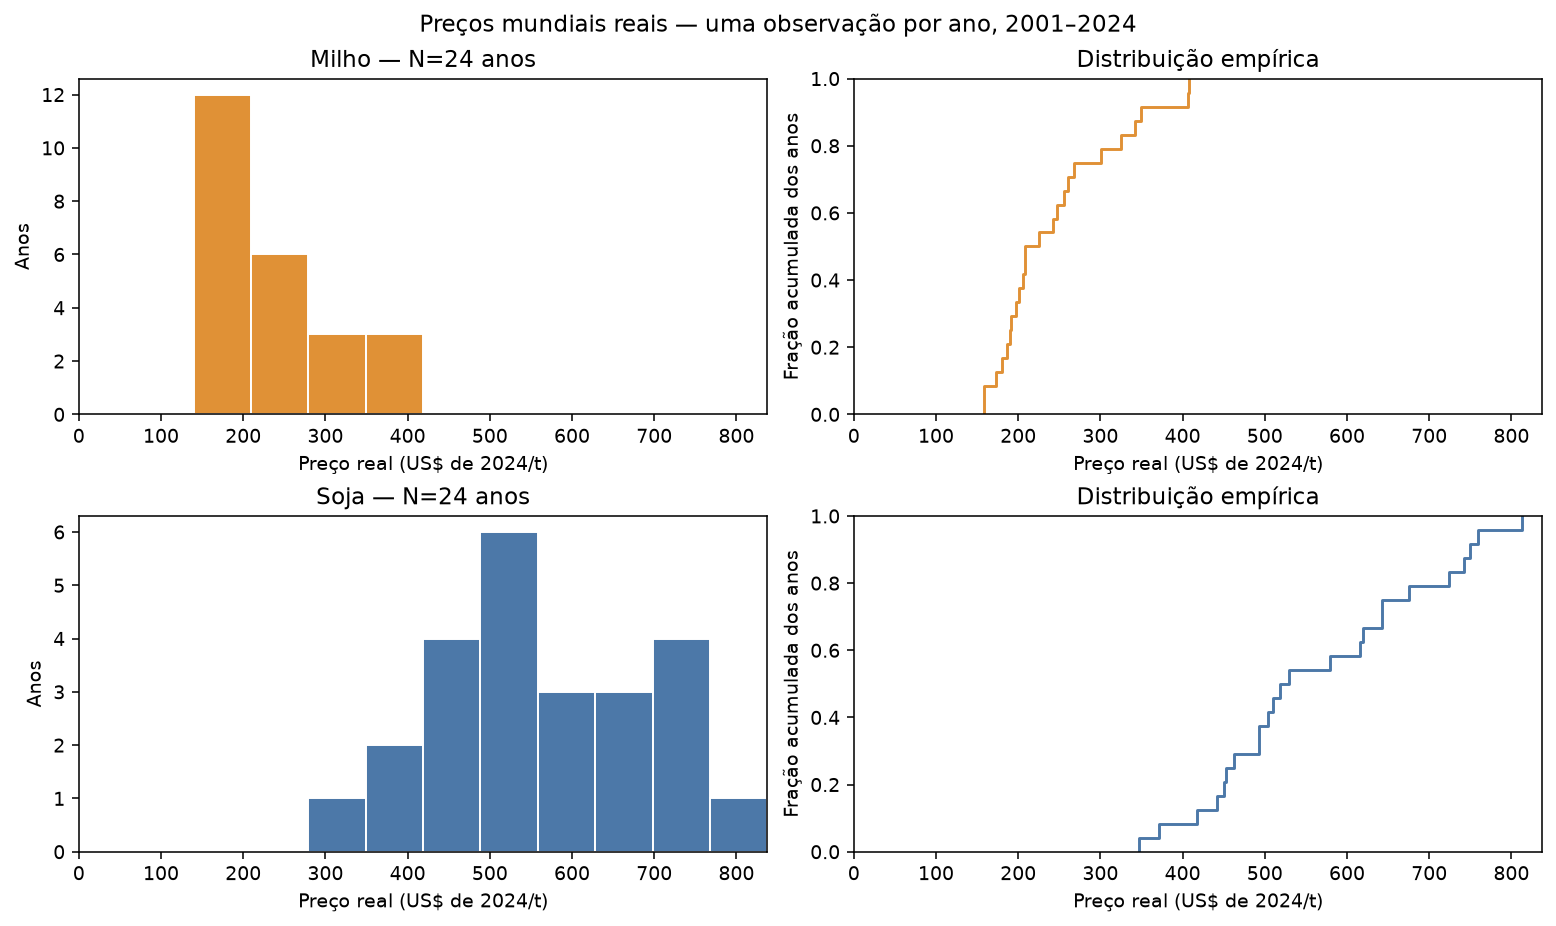

In [177]:
x1_resumo_niveis = []
for x1_produto in x1_produtos:
    for x1_moeda, x1_unidade in [('nominal', 'US$ correntes/t'), ('real_usd2024', 'US$ de 2024/t')]:
        x1_serie = x1_anual[f'preco_{x1_moeda}_media_anual__{x1_produto}'].dropna()
        x1_resumo_niveis.append({
            'Produto': x1_rotulos_produtos[x1_produto], 'Unidade': x1_unidade, 'N anos': len(x1_serie),
            'Média': x1_serie.mean(), 'Mediana': x1_serie.median(),
            'IQR': x1_serie.quantile(.75) - x1_serie.quantile(.25), 'P95': x1_serie.quantile(.95),
            'Assimetria': x1_serie.skew(), 'Mínimo': x1_serie.min(), 'Ano mínimo': x1_serie.idxmin(),
            'Máximo': x1_serie.max(), 'Ano máximo': x1_serie.idxmax(),
        })
x1_mostrar(pd.DataFrame(x1_resumo_niveis).set_index(['Produto', 'Unidade']), casas=3)

x1_limite_preco = x1_anual[[f'preco_real_usd2024_media_anual__{p}' for p in x1_produtos]].max().max() * 1.03
x1_classes = np.linspace(0, x1_limite_preco, 13)
fig, x1_eixos = plt.subplots(2, 2, figsize=(11, 6.5), dpi=140, layout='constrained')
for x1_linha, x1_produto in enumerate(x1_produtos):
    x1_serie = x1_anual[f'preco_real_usd2024_media_anual__{x1_produto}'].dropna()
    x1_eixos[x1_linha, 0].hist(x1_serie, bins=x1_classes, color=x1_cores[x1_produto], edgecolor='white')
    x1_eixos[x1_linha, 0].set(xlim=(0, x1_limite_preco), ylabel='Anos', xlabel='Preço real (US$ de 2024/t)',
                             title=f'{x1_rotulos_produtos[x1_produto]} — N={len(x1_serie)} anos')
    sns.ecdfplot(x=x1_serie, color=x1_cores[x1_produto], ax=x1_eixos[x1_linha, 1])
    x1_eixos[x1_linha, 1].set(xlim=(0, x1_limite_preco), ylim=(0, 1), ylabel='Fração acumulada dos anos',
                             xlabel='Preço real (US$ de 2024/t)', title='Distribuição empírica')
fig.suptitle('Preços mundiais reais — uma observação por ano, 2001–2024')
plt.show()


In [178]:
# Δln conserva aumentos e quedas; a conversão percentual exata é complementar.
x1_resumo_variacoes = []
for x1_produto in x1_produtos:
    for x1_janela, x1_sufixo in [('t versus t−1', ''), ('t−1 versus t−2', '_lag1')]:
        x1_serie = x1_anual[f'dln_preco_real_usd2024_media_anual{x1_sufixo}__{x1_produto}'].dropna()
        x1_resumo_variacoes.append({
            'Produto': x1_rotulos_produtos[x1_produto], 'Janela': x1_janela,
            'N anos': len(x1_serie), 'Aumentos': int(x1_serie.gt(0).sum()), 'Quedas': int(x1_serie.lt(0).sum()),
            'Zeros': int(x1_serie.eq(0).sum()), 'Média Δln': x1_serie.mean(), 'DP Δln': x1_serie.std(),
            'Mínimo Δln': x1_serie.min(), 'Linha do mínimo': x1_serie.idxmin(),
            'Máximo Δln': x1_serie.max(), 'Linha do máximo': x1_serie.idxmax(),
            'Queda extrema exata (%)': 100 * np.expm1(x1_serie.min()),
            'Aumento extremo exato (%)': 100 * np.expm1(x1_serie.max()),
        })
x1_mostrar(pd.DataFrame(x1_resumo_variacoes).set_index(['Produto', 'Janela']), casas=4)


N anos  Aumentos  Quedas  Zeros  Média Δln  DP Δln  \
Produto Janela                                                               
Milho   t versus t−1        24        13      11      0     0.0069  0.2069   
        t−1 versus t−2      24        13      11      0     0.0178  0.1959   
Soja    t versus t−1        24        12      12      0     0.0076  0.1680   
        t−1 versus t−2      24        13      11      0     0.0201  0.1559   

                        Mínimo Δln  Linha do mínimo  Máximo Δln  \
Produto Janela                                                    
Milho   t versus t−1       -0.3125             2014      0.4197   
        t−1 versus t−2     -0.3125             2015      0.4197   
Soja    t versus t−1       -0.2859             2024      0.3255   
        t−1 versus t−2     -0.2136             2016      0.3255   

                        Linha do máximo  Queda extrema exata (%)  \
Produto Janela                                                     
Milho   t versus t−1               2011                 -26.8398   
        t−1 versus t−2             2012                 -26.8398   
Soja    t versus t−1               2007                 -24.8640   
        t−1 versus t−2             2008                 -19.2351   

                        Aumento extremo exato (%)  
Produto Janela                                     
Milho   t versus t−1                      52.1429  
        t−1 versus t−2                    52.1429  
Soja    t versus t−1                      38.4676  
        t−1 versus t−2                    38.4676

No período, o preço real médio/mediano é aproximadamente **US$ 245,20/216,68 por tonelada de milho** e **US$ 564,81/524,46 por tonelada de soja**, a preços de 2024. Os máximos reais ocorrem em **2012**, enquanto os nominais ocorrem em **2022**: a escolha monetária altera a leitura histórica. A diferença entre produtos em US$/t não mede diretamente rentabilidade por hectare.

Nas variações reais contemporâneas há **13 aumentos e 11 quedas no milho**, e **12 de cada sinal na soja**. Valores negativos são quedas de preço, não erros ou ausências. `100 × Δln` aproxima uma variação percentual para mudanças pequenas; a variação exata é `100 × (exp(Δln) − 1)`, mostrada para os extremos. Defasar desloca o período da informação; não comprova expectativa, exogeneidade ou ausência de antecipação.


**3. Como a base monetária e os extremos aparecem nas trajetórias?**

As figuras apresentam níveis nominais, níveis reais e diferenças de logs reais, em painéis com unidades distintas e sem eixo duplo. Cada ponto é um ano, com o mesmo peso. A tabela localiza os três maiores preços e as três maiores variações absolutas por produto; mantém seus sinais e não descarta extremos.


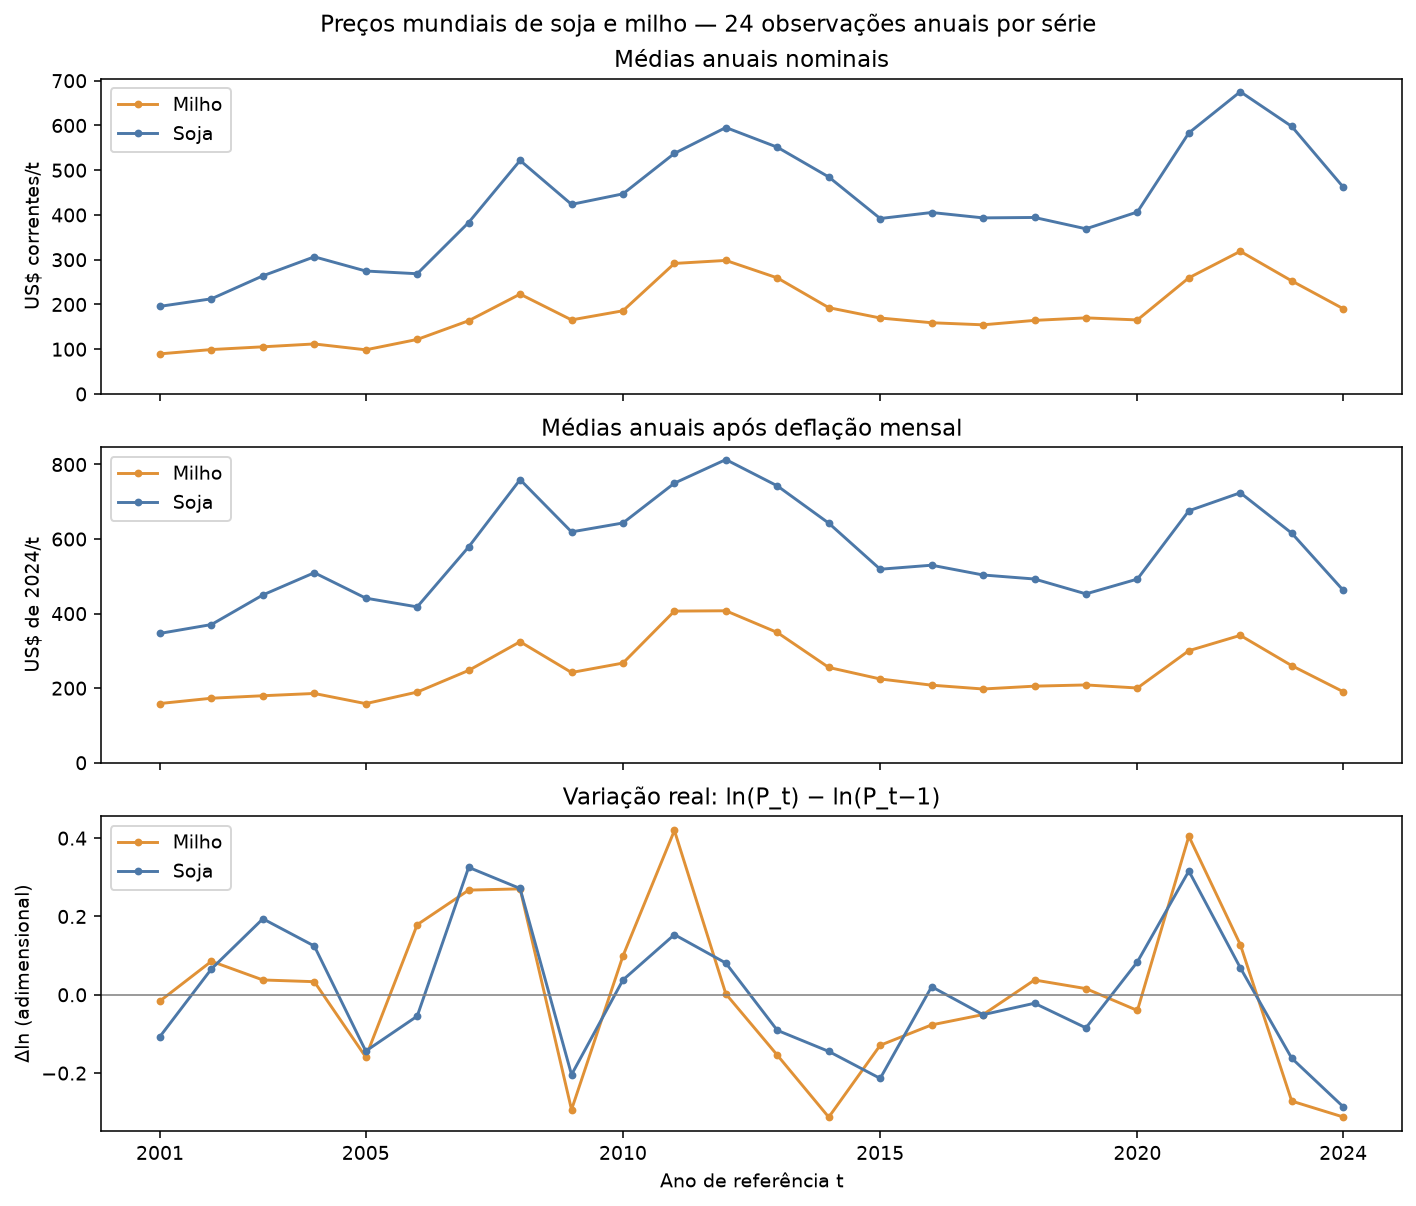

Preço real (US$2024/t)  Δln real  \
Produto Critério             Ano                                      
milho   Maiores preços reais 2012                 407.620     0.002   
                             2011                 406.734     0.420   
                             2013                 349.384    -0.154   
        Maiores |Δln| reais  2011                 406.734     0.420   
                             2021                 300.518     0.405   
                             2014                 255.610    -0.313   
soja    Maiores preços reais 2012                 813.211     0.081   
                             2008                 759.379     0.271   
                             2011                 749.953     0.154   
        Maiores |Δln| reais  2007                 578.858     0.325   
                             2021                 675.835     0.316   
                             2024                 462.713    -0.286   

                                   Variação exata (%)  
Produto Critério             Ano                       
milho   Maiores preços reais 2012               0.218  
                             2011              52.143  
                             2013             -14.287  
        Maiores |Δln| reais  2011              52.143  
                             2021              49.904  
                             2014             -26.840  
soja    Maiores preços reais 2012               8.435  
                             2008              31.186  
                             2011              16.609  
        Maiores |Δln| reais  2007              38.468  
                             2021              37.185  
                             2024             -24.864

In [179]:
fig, x1_eixos = plt.subplots(3, 1, figsize=(10, 8.5), dpi=140, sharex=True, layout='constrained')
for x1_produto in x1_produtos:
    for x1_eixo, x1_prefixo in zip(x1_eixos, ['preco_nominal_media_anual', 'preco_real_usd2024_media_anual', 'dln_preco_real_usd2024_media_anual']):
        x1_eixo.plot(x1_anual.index, x1_anual[f'{x1_prefixo}__{x1_produto}'],
                     color=x1_cores[x1_produto], marker='o', markersize=3, label=x1_rotulos_produtos[x1_produto])
x1_eixos[0].set(title='Médias anuais nominais', ylabel='US$ correntes/t', ylim=(0, None))
x1_eixos[1].set(title='Médias anuais após deflação mensal', ylabel='US$ de 2024/t', ylim=(0, None))
x1_eixos[2].axhline(0, color='grey', linewidth=.8)
x1_eixos[2].set(title='Variação real: ln(P_t) − ln(P_t−1)', ylabel='Δln (adimensional)', xlabel='Ano de referência t')
for x1_eixo in x1_eixos:
    x1_eixo.legend(loc='upper left')
x1_eixos[-1].set_xticks([2001, 2005, 2010, 2015, 2020, 2024])
fig.suptitle('Preços mundiais de soja e milho — 24 observações anuais por série')
plt.show()

x1_extremos = []
for x1_produto in x1_produtos:
    x1_preco = f'preco_real_usd2024_media_anual__{x1_produto}'
    x1_variacao = f'dln_preco_real_usd2024_media_anual__{x1_produto}'
    for x1_criterio, x1_anos in [('Maiores preços reais', x1_anual[x1_preco].nlargest(3).index),
                               ('Maiores |Δln| reais', x1_anual[x1_variacao].abs().nlargest(3).index)]:
        for x1_ano in x1_anos:
            x1_extremos.append({'Produto': x1_produto, 'Critério': x1_criterio, 'Ano': x1_ano,
                                'Preço real (US$2024/t)': x1_anual.loc[x1_ano, x1_preco],
                                'Δln real': x1_anual.loc[x1_ano, x1_variacao],
                                'Variação exata (%)': 100 * np.expm1(x1_anual.loc[x1_ano, x1_variacao])})
x1_mostrar(pd.DataFrame(x1_extremos).set_index(['Produto', 'Critério', 'Ano']), casas=3)


As séries oscilam e apresentam aumentos e quedas comuns, sem uma trajetória monotônica. Anos de nível alto e de grande variação respondem a perguntas distintas; a diferença de logs enfatiza mudança, enquanto o nível representa a referência de preço. A anualização civil pode ocultar variações mensais e não define o calendário da decisão de conversão. As curvas descrevem preços realizados; a janela anterior à decisão e sua adequação a H1 permanecem escolhas a justificar.


**4. Como se distribuem territorialmente as interações de preço e capacidade?**

Para conhecer a heterogeneidade espacial sem repetir os municípios 24 vezes na mesma distribuição, usa-se **2001**, início do painel. A interação nessa linha combina `ln(preço real de 2000)` e capacidade padronizada fixa. Cada caixa compara municípios de uma variante, no suporte próprio; os N diferentes são mostrados e a comparação em suporte comum virá depois. Os pontos além dos bigodes de 1,5 IQR permanecem na análise.


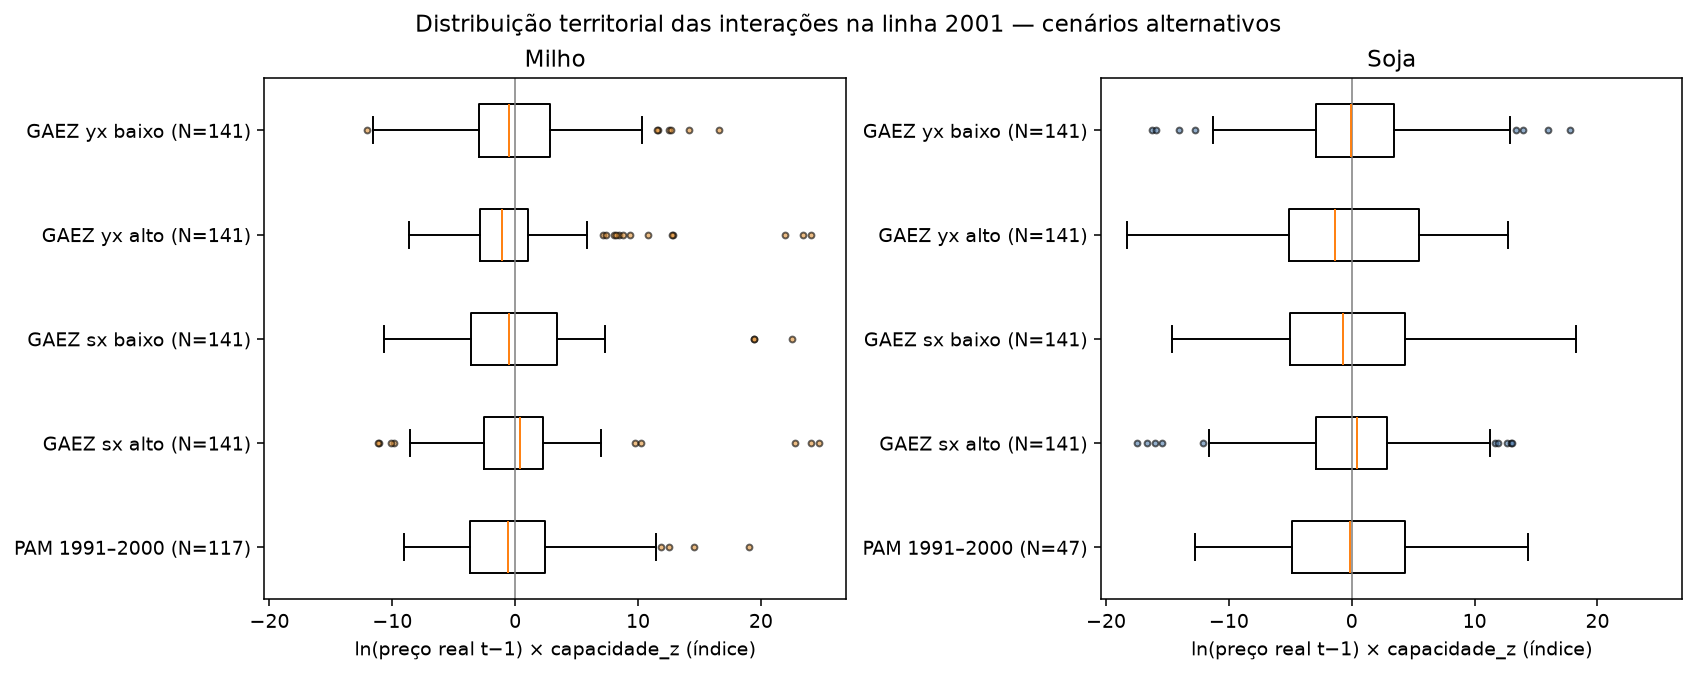

N municípios  Ausentes  Negativos  Zeros  Média  \
Produto Variante                                                         
milho   PAM 1991–2000           117        24         64      0  0.000   
        GAEZ sx alto            141         0         68      0  0.000   
        GAEZ sx baixo           141         0         79      0 -0.000   
        GAEZ yx alto            141         0         91      0 -0.000   
        GAEZ yx baixo           141         0         76      0 -0.000   
soja    PAM 1991–2000            47        94         24      0 -0.000   
        GAEZ sx alto            141         0         59      0  0.000   
        GAEZ sx baixo           141         0         72      0 -0.000   
        GAEZ yx alto            141         0         78      0 -0.000   
        GAEZ yx baixo           141         0         71      0 -0.000   

                       Mediana    P25   P75  Mínimo  Máximo  
Produto Variante                                             
milho   PAM 1991–2000   -0.617 -3.653 2.434  -9.043  19.036  
        GAEZ sx alto     0.418 -2.517 2.262 -11.180  24.754  
        GAEZ sx baixo   -0.464 -3.558 3.441 -10.672  22.551  
        GAEZ yx alto    -1.035 -2.861 1.070  -8.677  24.109  
        GAEZ yx baixo   -0.525 -2.937 2.827 -12.053  16.583  
soja    PAM 1991–2000   -0.110 -4.852 4.348 -12.748  14.315  
        GAEZ sx alto     0.435 -2.946 2.830 -17.510  13.007  
        GAEZ sx baixo   -0.679 -5.002 4.347 -14.657  18.239  
        GAEZ yx alto    -1.397 -5.092 5.454 -18.264  12.694  
        GAEZ yx baixo   -0.033 -2.901 3.459 -16.218  17.802

Código IBGE  Ano da linha  Índice
Produto Variante      Extremo                                  
milho   PAM 1991–2000 Mínimo      5101605          2013 -10.692
                      Máximo      5100607          2013  22.505
        GAEZ sx alto  Mínimo      5107578          2013 -13.217
                      Máximo      5101605          2013  29.266
        GAEZ sx baixo Mínimo      5100805          2013 -12.617
                      Máximo      5103809          2013  26.661
        GAEZ yx alto  Mínimo      5100805          2013 -10.259
                      Máximo      5102504          2013  28.503
        GAEZ yx baixo Mínimo      5103254          2013 -14.250
                      Máximo      5100508          2013  19.605
soja    PAM 1991–2000 Mínimo      5108204          2013 -14.343
                      Máximo      5106372          2013  16.107
        GAEZ sx alto  Mínimo      5100805          2013 -19.701
                      Máximo      5107297          2013  14.635
        GAEZ sx baixo Mínimo      5106315          2013 -16.491
                      Máximo      5103809          2013  20.522
        GAEZ yx alto  Mínimo      5100805          2013 -20.550
                      Máximo      5103403          2013  14.282
        GAEZ yx baixo Mínimo      5100805          2013 -18.247
                      Máximo      5100508          2013  20.030

In [180]:
x1_ano_referencia = int(x1_aed['ano'].min())
x1_corte = x1_aed.loc[x1_aed['ano'].eq(x1_ano_referencia)].copy()
x1_resumo_interacoes = []
fig, x1_eixos = plt.subplots(1, 2, figsize=(12, 4.7), dpi=140, sharex=True, layout='constrained')
for x1_eixo, x1_produto in zip(x1_eixos, x1_produtos):
    x1_caixas, x1_etiquetas = [], []
    for x1_coluna, x1_rotulo in zip(x1_interacoes[x1_produto], x1_rotulos_variantes):
        x1_serie = x1_corte[x1_coluna].dropna()
        x1_caixas.append(x1_serie.to_numpy())
        x1_etiquetas.append(f'{x1_rotulo} (N={len(x1_serie)})')
        x1_resumo_interacoes.append({'Produto': x1_produto, 'Variante': x1_rotulo,
                                     'N municípios': len(x1_serie), 'Ausentes': int(x1_corte[x1_coluna].isna().sum()),
                                     'Negativos': int(x1_serie.lt(0).sum()), 'Zeros': int(x1_serie.eq(0).sum()),
                                     'Média': x1_serie.mean(), 'Mediana': x1_serie.median(),
                                     'P25': x1_serie.quantile(.25), 'P75': x1_serie.quantile(.75),
                                     'Mínimo': x1_serie.min(), 'Máximo': x1_serie.max()})
    x1_eixo.boxplot(x1_caixas, tick_labels=x1_etiquetas, orientation='horizontal',
                    flierprops={'markersize': 3, 'markerfacecolor': x1_cores[x1_produto], 'alpha': .6})
    x1_eixo.axvline(0, color='grey', linewidth=.8)
    x1_eixo.set(title=x1_rotulos_produtos[x1_produto], xlabel='ln(preço real t−1) × capacidade_z (índice)')
fig.suptitle(f'Distribuição territorial das interações na linha {x1_ano_referencia} — cenários alternativos')
plt.show()
x1_mostrar(pd.DataFrame(x1_resumo_interacoes).set_index(['Produto', 'Variante']), casas=3)

# Localizar extremos no painel completo: não são estimativas de efeitos econômicos.
x1_extremos_interacoes = []
for x1_produto in x1_produtos:
    for x1_coluna, x1_rotulo in zip(x1_interacoes[x1_produto], x1_rotulos_variantes):
        for x1_criterio, x1_indice in [('Mínimo', x1_aed[x1_coluna].idxmin()), ('Máximo', x1_aed[x1_coluna].idxmax())]:
            x1_linha = x1_aed.loc[x1_indice]
            x1_extremos_interacoes.append({'Produto': x1_produto, 'Variante': x1_rotulo, 'Extremo': x1_criterio,
                                           'Código IBGE': str(x1_linha['codigo_ibge']), 'Ano da linha': x1_linha['ano'],
                                           'Índice': x1_linha[x1_coluna]})
x1_mostrar(pd.DataFrame(x1_extremos_interacoes).set_index(['Produto', 'Variante', 'Extremo']), casas=3)


A capacidade PAM observada fornece **117 municípios para milho** e **47 para soja**; cada cenário GAEZ fornece **141**. As interações negativas refletem capacidade padronizada abaixo da média de referência, pois os logs de preços reais são positivos nesta unidade e janela. A média próxima de zero decorre da centralização da capacidade, não da ausência de incentivo ou heterogeneidade. As dez variantes atingem seus extremos na linha **2013**, associada ao preço real de **2012**, sem que isso constitua dez eventos independentes.

As distribuições não homologam a capacidade como predeterminada. PAM conserva seleção de produtores e pendência de geografia histórica; GAEZ combina clima de referência 1961–1990 e terras de 2010, com temporalidade pendente e, em `yx`, compatibilidade de umidade comercial a avaliar. `sx` é aptidão, `yx` é rendimento potencial; padronização não torna esses conceitos intercambiáveis. As flags dessas limitações estão em X2, não nas quatro flags de preço deste recorte.


###### Análise Multivariada


In [181]:
# Relações anuais, construção das exposições e suporte conjunto para H1


**1. Quanto os preços de soja e milho se movem conjuntamente?**

As dispersões bivariadas em nível real e Δln real usam 24 anos, com o ano na cor. Pearson resume associação linear e Spearman associação de ordenação; os coeficientes são complementos descritivos, sem p-valores que ignorem a dependência temporal. Níveis, mudanças e mudanças defasadas são comparados com seus próprios períodos, sem multiplicar N pelos municípios.


,N anos comuns,Pearson,Spearman
Representação,,,
Nível nominal t,24,0.9640,0.9383
Nível real t,24,0.9465,0.9452
Δln real t,24,0.8403,0.8217
Δln real t−1,24,0.8171,0.7948


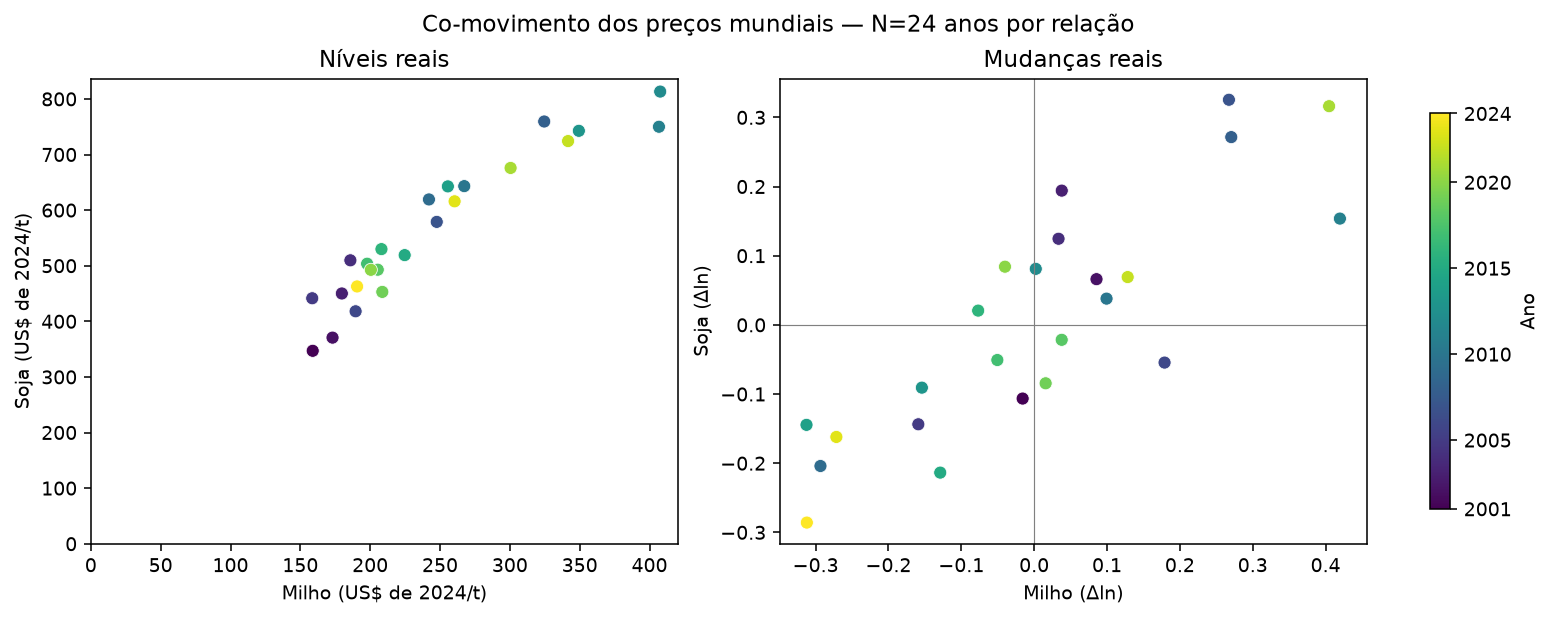

In [182]:
x1_associacoes_precos = []
for x1_nome, x1_prefixo in [
    ('Nível nominal t', 'preco_nominal_media_anual'), ('Nível real t', 'preco_real_usd2024_media_anual'),
    ('Δln real t', 'dln_preco_real_usd2024_media_anual'), ('Δln real t−1', 'dln_preco_real_usd2024_media_anual_lag1'),
]:
    x1_par = x1_anual[[f'{x1_prefixo}__milho', f'{x1_prefixo}__soja']].dropna()
    x1_associacoes_precos.append({'Representação': x1_nome, 'N anos comuns': len(x1_par),
                                 'Pearson': x1_par.corr().iloc[0, 1], 'Spearman': x1_par.corr(method='spearman').iloc[0, 1]})
x1_mostrar(pd.DataFrame(x1_associacoes_precos).set_index('Representação'), casas=4)

fig, x1_eixos = plt.subplots(1, 2, figsize=(11, 4.3), dpi=140, layout='constrained')
for x1_eixo, x1_prefixo, x1_unidade in zip(x1_eixos,
    ['preco_real_usd2024_media_anual', 'dln_preco_real_usd2024_media_anual'], ['US$ de 2024/t', 'Δln']):
    x1_pontos = x1_eixo.scatter(x1_anual[f'{x1_prefixo}__milho'], x1_anual[f'{x1_prefixo}__soja'],
                                c=x1_anual.index, cmap='viridis', s=45, edgecolors='white', linewidth=.4)
    x1_eixo.set(xlabel=f'Milho ({x1_unidade})', ylabel=f'Soja ({x1_unidade})',
                title='Níveis reais' if x1_unidade != 'Δln' else 'Mudanças reais')
    if x1_unidade == 'Δln':
        x1_eixo.axhline(0, color='grey', linewidth=.6)
        x1_eixo.axvline(0, color='grey', linewidth=.6)
    else:
        x1_eixo.set(xlim=(0, None), ylim=(0, None))
fig.colorbar(x1_pontos, ax=x1_eixos, label='Ano', ticks=[2001, 2005, 2010, 2015, 2020, 2024], shrink=.85)
fig.suptitle('Co-movimento dos preços mundiais — N=24 anos por relação')
plt.show()


Nos níveis reais, Pearson/Spearman são aproximadamente **0,946/0,945**; nas diferenças de logs reais, **0,840/0,822**. Há forte co-movimento nessa janela, também presente nas mudanças, mas isso não mede transmissão causal nem torna os dois produtos equivalentes. A inclusão conjunta de representações deve considerar o suporte e a variação que se pretende identificar; escolher ou excluir um produto apenas pela correlação não responde à heterogeneidade de atividades prevista em H1.


**2. As diferenças entre exposições refletem construção, bioma ou ausência de capacidade?**

Para conferir as fórmulas, recuperam-se de `df1` somente as dez capacidades padronizadas e as duas frações territoriais usadas nestas construções. A vinculação é município–ano, um para um, sem alterar os dataframes candidatos. As frações de Cerrado e Pantanal são contínuas, fixas por município, e não classes mutuamente exclusivas: um município pode conter mais de um bioma.

A tabela separa zero territorial observado de capacidade ausente. `NA × 0` permanece ausente nesta construção; não representa exposição conhecida igual a zero. As exposições são índices de interação, não valores monetários, receitas ou conversão.


In [183]:
x1_colunas_capacidade = [f'capacidade_z__{p}__{v}' for p in x1_produtos for v in x1_sufixos[p]]
x1_colunas_bioma = ['biome_cerrado_share_i', 'biome_pantanal_share_i']
x1_insumos = df1.loc[:, x1_chaves + x1_colunas_capacidade + x1_colunas_bioma].copy()
x1_insumos['ano'] = x1_insumos['ano'].dt.year
x1_contexto = x1_aed.merge(x1_insumos, on=x1_chaves, how='left', validate='one_to_one')
assert len(x1_contexto) == len(x1_aed)
assert x1_contexto.groupby('codigo_ibge', observed=True)[x1_colunas_capacidade + x1_colunas_bioma].nunique(dropna=False).le(1).all().all()
# Tolerância apenas diagnóstica para precisão de frações territoriais; não recorta valores.
assert x1_contexto[x1_colunas_bioma].ge(-1e-12).all().all() and x1_contexto[x1_colunas_bioma].le(1 + 1e-12).all().all()
x1_dominio_biomas = []
for x1_coluna in x1_colunas_bioma:
    x1_fora_estrito = ~x1_contexto[x1_coluna].between(0, 1)
    x1_dominio_biomas.append({'Coluna': x1_coluna, 'Pares fora de [0,1] estrito': int(x1_fora_estrito.sum()),
                             'Municípios fora do limite estrito': x1_contexto.loc[x1_fora_estrito, 'codigo_ibge'].nunique(),
                             'Maior excesso acima de 1': f'{max(0, x1_contexto[x1_coluna].max() - 1):.3g}'})
display(pd.DataFrame(x1_dominio_biomas).set_index('Coluna'))
x1_diagnostico_biomas = []
for x1_produto in x1_produtos:
    for x1_variante, x1_rotulo in zip(x1_sufixos[x1_produto], x1_rotulos_variantes):
        x1_inter = f'{x1_prefixo_interacao}__{x1_produto}__{x1_variante}'
        x1_z = f'capacidade_z__{x1_produto}__{x1_variante}'
        x1_formula = x1_contexto[f'ln_preco_real_usd2024_media_anual_lag1__{x1_produto}'] * x1_contexto[x1_z]
        assert np.allclose(x1_contexto[x1_inter], x1_formula, atol=1e-10, rtol=1e-10, equal_nan=True)
        for x1_bioma in ['cerrado', 'pantanal']:
            x1_share = f'biome_{x1_bioma}_share_i'
            x1_expo = f'exposicao_real_x_{x1_bioma}__{x1_produto}__{x1_variante}'
            assert np.allclose(x1_contexto[x1_expo], x1_contexto[x1_inter] * x1_contexto[x1_share],
                               atol=1e-10, rtol=1e-10, equal_nan=True)
            x1_valido = x1_contexto[x1_expo].notna()
            x1_zero_territorial = x1_valido & x1_contexto[x1_share].eq(0)
            x1_diagnostico_biomas.append({
                'Produto': x1_produto, 'Variante': x1_rotulo, 'Bioma': x1_bioma,
                'N exposição': int(x1_valido.sum()), 'Ausentes': int((~x1_valido).sum()),
                'Zeros observados': int(x1_contexto[x1_expo].eq(0).sum()),
                'Zeros com fração nula': int(x1_zero_territorial.sum()),
                'Municípios com fração nula e exposição válida': x1_contexto.loc[x1_zero_territorial, 'codigo_ibge'].nunique(),
                'NA apesar de fração nula': int((~x1_valido & x1_contexto[x1_share].eq(0)).sum()),
            })
x1_diagnostico_biomas = pd.DataFrame(x1_diagnostico_biomas).set_index(['Produto', 'Variante', 'Bioma'])
display(x1_diagnostico_biomas)


,"Pares fora de [0,1] estrito",Municípios fora do limite estrito,Maior excesso acima de 1
Coluna,,,
biome_cerrado_share_i,408,17,7.11e-15
biome_pantanal_share_i,0,0,0


N exposição  Ausentes  Zeros observados  \
Produto Variante      Bioma                                               
milho   PAM 1991–2000 cerrado          2808       576               840   
                      pantanal         2808       576              2520   
        GAEZ sx alto  cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
        GAEZ sx baixo cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
        GAEZ yx alto  cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
        GAEZ yx baixo cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
soja    PAM 1991–2000 cerrado          1128      2256                72   
                      pantanal         1128      2256              1032   
        GAEZ sx alto  cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
        GAEZ sx baixo cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
        GAEZ yx alto  cerrado          3384         0              1080   
                      pantanal         3384         0              3072   
        GAEZ yx baixo cerrado          3384         0              1080   
                      pantanal         3384         0              3072   

                                Zeros com fração nula  \
Produto Variante      Bioma                             
milho   PAM 1991–2000 cerrado                     840   
                      pantanal                   2520   
        GAEZ sx alto  cerrado                    1080   
                      pantanal                   3072   
        GAEZ sx baixo cerrado                    1080   
                      pantanal                   3072   
        GAEZ yx alto  cerrado                    1080   
                      pantanal                   3072   
        GAEZ yx baixo cerrado                    1080   
                      pantanal                   3072   
soja    PAM 1991–2000 cerrado                      72   
                      pantanal                   1032   
        GAEZ sx alto  cerrado                    1080   
                      pantanal                   3072   
        GAEZ sx baixo cerrado                    1080   
                      pantanal                   3072   
        GAEZ yx alto  cerrado                    1080   
                      pantanal                   3072   
        GAEZ yx baixo cerrado                    1080   
                      pantanal                   3072   

                                Municípios com fração nula e exposição válida  \
Produto Variante      Bioma                                                     
milho   PAM 1991–2000 cerrado                                              35   
                      pantanal                                            105   
        GAEZ sx alto  cerrado                                              45   
                      pantanal                                            128   
        GAEZ sx baixo cerrado                                              45   
                      pantanal                                            128   
        GAEZ yx alto  cerrado                                              45   
                      pantanal                                            128   
        GAEZ yx baixo cerrado                                              45   
                      pantanal                                            128   
soja    PAM 1991–2000 cerrado                                               3   
                      pantanal                                           

As dez interações e as vinte multiplicações por fração de bioma conferem. As frações de Cerrado ultrapassam 1 em **408 pares de 17 municípios**, com excesso máximo de aproximadamente **7 × 10⁻¹⁵**, compatível com precisão numérica; os valores originais foram preservados, usando tolerância de 10⁻¹² somente na conferência de domínio.

Em cada variante GAEZ, há **1.080 zeros na exposição ao Cerrado (45 municípios × 24 anos)** e **3.072 no Pantanal (128 × 24)**, associados à fração territorial nula. Esses zeros não significam preço, capacidade ou conversão nulos. Em PAM, a ausência de capacidade permanece ausente mesmo quando a fração é zero. Os coeficientes territoriais mudam distribuição e suporte substantivo, sem criar choques de preço independentes. O índice sem multiplicação por bioma tampouco representa exclusivamente Amazônia.


**3. Quanto as variantes de capacidade concordam no mesmo suporte?**

Para cada produto, selecionam-se os municípios com as cinco variantes observadas no mesmo ano de referência. Compara-se a ordenação das interações no mesmo suporte territorial: é o mesmo log positivo do preço real defasado multiplicando capacidades diferentes. A matriz resume associações bivariadas entre cenários; não é um teste de H1 nem critério suficiente para escolher uma capacidade. A restrição é própria desta comparação, não um filtro global para os modelos.


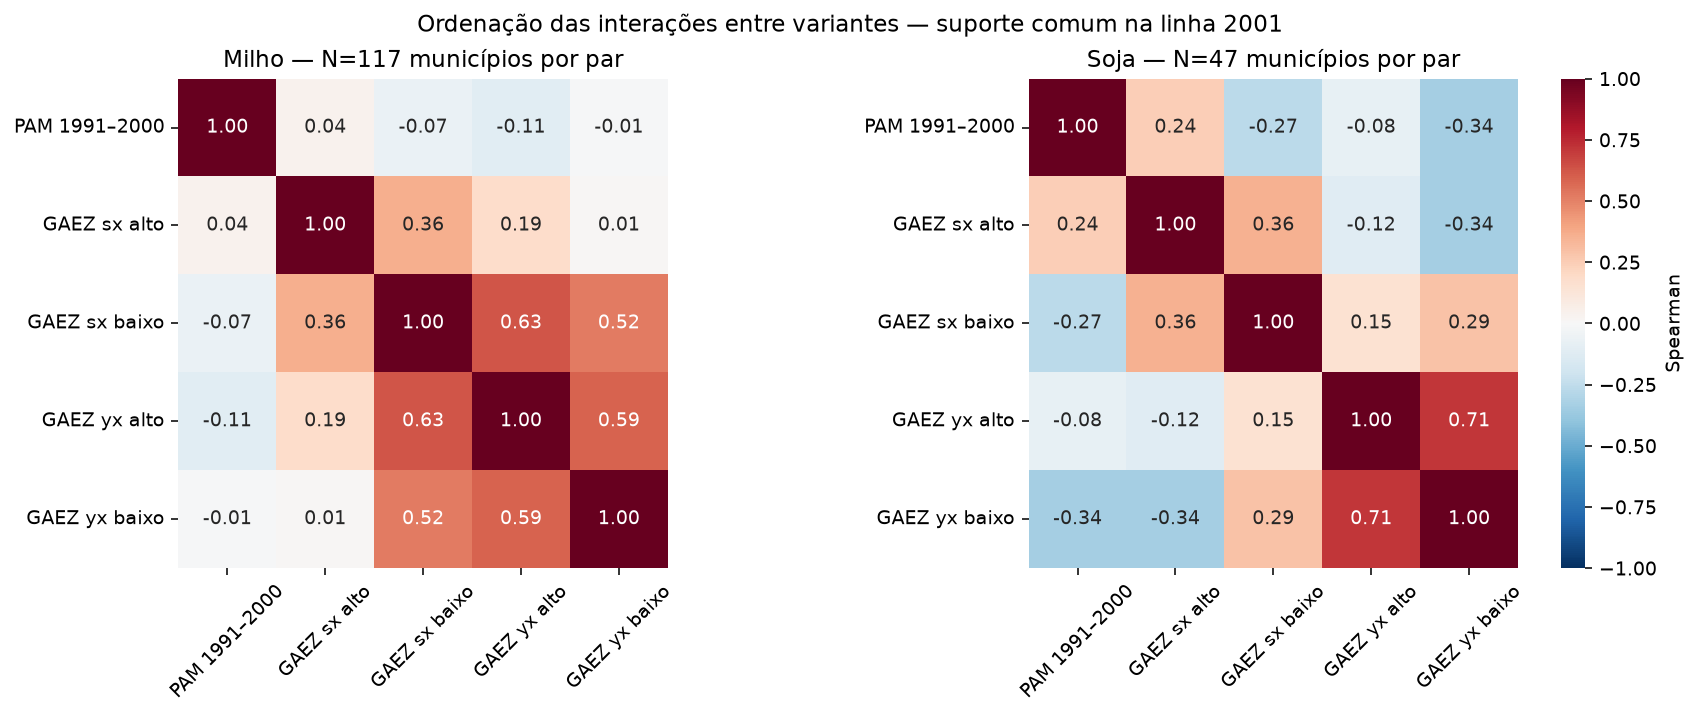

,Ano da linha,Municípios no suporte comum,Municípios na grade,Perda apenas nesta comparação
Produto,,,,
milho,2001,117,141,24
soja,2001,47,141,94


In [184]:
x1_suporte_variantes = []
fig, x1_eixos = plt.subplots(1, 2, figsize=(12, 5), dpi=140, layout='constrained')
for x1_eixo, x1_produto in zip(x1_eixos, x1_produtos):
    x1_base_comum = x1_corte[x1_interacoes[x1_produto]].dropna()
    x1_suporte_variantes.append({'Produto': x1_produto, 'Ano da linha': x1_ano_referencia,
                                'Municípios no suporte comum': len(x1_base_comum),
                                'Municípios na grade': len(x1_corte),
                                'Perda apenas nesta comparação': len(x1_corte) - len(x1_base_comum)})
    x1_matriz = x1_base_comum.corr(method='spearman')
    x1_matriz.index = x1_rotulos_variantes
    x1_matriz.columns = x1_rotulos_variantes
    sns.heatmap(x1_matriz, ax=x1_eixo, vmin=-1, vmax=1, cmap='RdBu_r', annot=True, fmt='.2f',
                square=True, cbar=x1_produto == 'soja', cbar_kws={'label': 'Spearman'})
    x1_eixo.set_title(f'{x1_rotulos_produtos[x1_produto]} — N={len(x1_base_comum)} municípios por par')
    x1_eixo.tick_params(axis='x', rotation=45)
    x1_eixo.tick_params(axis='y', rotation=0)
fig.suptitle(f'Ordenação das interações entre variantes — suporte comum na linha {x1_ano_referencia}')
plt.show()
display(pd.DataFrame(x1_suporte_variantes).set_index('Produto'))


O suporte comum tem **117 municípios para milho** e **47 para soja**, limitado por PAM. As matrizes mostram concordâncias distintas entre os cenários; capacidade histórica observada, aptidão e rendimento potencial não são medidas intercambiáveis apenas porque foram padronizadas. A mesma ordenação da capacidade se reproduz na interação em um ano com log de preço positivo. A comparação não escolhe GAEZ pela cobertura, nem PAM por ser pré-painel; exige avaliar mensuração e limites de cada variante nos blocos X2.


**4. Que variação permanece ao distinguir município e ano?**

Como diagnóstico de construção, subtraem-se médias municipais e anuais, somando a média geral, de duas séries puras e das dez interações. A operação usa, **por coluna**, todos os municípios com 24 anos dessa medida, antes de qualquer recorte com Y. Nesse suporte balanceado, o duplo desvio remove componentes aditivos de município e ano; não estima uma regressão nem valida uma estratégia causal. A tabela mostra desvio-padrão original, após retirar a média municipal e após retirar ambos os componentes.


In [185]:
x1_variacao_painel = []
x1_planos_variacao = [(f'ln_preco_real_usd2024_media_anual_lag1__{p}', p, 'Preço puro (ln real t−1)') for p in x1_produtos]
x1_planos_variacao += [(c, p, r) for p in x1_produtos for c,r in zip(x1_interacoes[p], x1_rotulos_variantes)]
for x1_coluna, x1_produto, x1_rotulo in x1_planos_variacao:
    x1_base = x1_aed[x1_chaves + [x1_coluna]].dropna().copy()
    assert x1_base.groupby('codigo_ibge', observed=True)['ano'].nunique().eq(len(x1_anual)).all()
    assert x1_base.groupby('ano')['codigo_ibge'].nunique().nunique() == 1
    x1_desvio_mun = x1_base[x1_coluna] - x1_base.groupby('codigo_ibge', observed=True)[x1_coluna].transform('mean')
    x1_duplo_desvio = x1_desvio_mun - x1_base.groupby('ano')[x1_coluna].transform('mean') + x1_base[x1_coluna].mean()
    x1_variacao_painel.append({'Produto': x1_produto, 'Representação': x1_rotulo,
                              'Pares': len(x1_base), 'Municípios': x1_base['codigo_ibge'].nunique(),
                              'DP original': x1_base[x1_coluna].std(), 'DP após média municipal': x1_desvio_mun.std(),
                              'DP após município e ano': x1_duplo_desvio.std()})
x1_mostrar(pd.DataFrame(x1_variacao_painel).set_index(['Produto', 'Representação']), casas=6)


Pares  Municípios  DP original  \
Produto Representação                                              
milho   Preço puro (ln real t−1)   3384         141     0.283219   
soja    Preço puro (ln real t−1)   3384         141     0.239448   
milho   PAM 1991–2000              2808         117     5.440346   
        GAEZ sx alto               3384         141     5.444171   
        GAEZ sx baixo              3384         141     5.444171   
        GAEZ yx alto               3384         141     5.444171   
        GAEZ yx baixo              3384         141     5.444171   
soja    PAM 1991–2000              1128          47     6.242379   
        GAEZ sx alto               3384         141     6.285592   
        GAEZ sx baixo              3384         141     6.285592   
        GAEZ yx alto               3384         141     6.285592   
        GAEZ yx baixo              3384         141     6.285592   

                                  DP após média municipal  \
Produto Representação                                       
milho   Preço puro (ln real t−1)                 0.283219   
soja    Preço puro (ln real t−1)                 0.239448   
milho   PAM 1991–2000                            0.282015   
        GAEZ sx alto                             0.282213   
        GAEZ sx baixo                            0.282213   
        GAEZ yx alto                             0.282213   
        GAEZ yx baixo                            0.282213   
soja    PAM 1991–2000                            0.236957   
        GAEZ sx alto                             0.238597   
        GAEZ sx baixo                            0.238597   
        GAEZ yx alto                             0.238597   
        GAEZ yx baixo                            0.238597   

                                  DP após município e ano  
Produto Representação                                      
milho   Preço puro (ln real t−1)                 0.000000  
soja    Preço puro (ln real t−1)                 0.000000  
milho   PAM 1991–2000                            0.282015  
        GAEZ sx alto                             0.282213  
        GAEZ sx baixo                            0.282213  
        GAEZ yx alto                             0.282213  
        GAEZ yx baixo                            0.282213  
soja    PAM 1991–2000                            0.236957  
        GAEZ sx alto                             0.238597  
        GAEZ sx baixo                            0.238597  
        GAEZ yx alto                             0.238597  
        GAEZ yx baixo                            0.238597

Os preços puros variam somente no tempo: efeitos fixos de ano absorvem seus níveis, logs, diferenças e defasagens. A capacidade fixa, por sua vez, é absorvida por efeitos municipais. As interações podem conservar variação conjunta porque combinam preço temporal e capacidade territorial, como mostra o duplo desvio. Os desvios-padrão iguais entre os cenários GAEZ de um mesmo produto decorrem da padronização z no mesmo universo e do preço comum; não demonstram equivalência territorial das capacidades, cujas ordenações diferem.

Isso esclarece o papel candidato das interações para H1, sem estabelecer exogeneidade, validade temporal da capacidade ou suficiência para identificação. Correlação empilhada entre preço e sua interação também pode ser próxima de zero por centralização da capacidade, sem indicar que a interação seja irrelevante.


**5. Qual suporte destas candidatas encontra Y observado?**

Vinculam-se apenas as duas taxas de `Y_tx_conv`, pela chave município–ano e com cardinalidade um para um, para medir cobertura conjunta. Não se exige completude simultânea das 30 construções. A tabela apresenta cada interação separadamente; as exposições herdam a disponibilidade da capacidade e têm ainda os zeros territoriais já documentados. A checagem de suporte não estima resposta da conversão aos preços.


In [186]:
x1_taxas_y = ['taxa_conversao__agricultura', 'taxa_conversao__pastagem']
x1_y = Y_tx_conv.loc[:, x1_chaves + x1_taxas_y].copy()
x1_y['ano'] = x1_y['ano'].dt.year
x1_com_y = x1_aed.merge(x1_y, on=x1_chaves, how='left', validate='one_to_one')
assert len(x1_com_y) == len(x1_aed)
x1_disponivel_y = x1_com_y[x1_taxas_y].notna().all(axis=1)
x1_suporte_y = []
for x1_produto in x1_produtos:
    for x1_coluna, x1_rotulo in zip(x1_interacoes[x1_produto], x1_rotulos_variantes):
        x1_valido_x = x1_com_y[x1_coluna].notna()
        x1_comum = x1_valido_x & x1_disponivel_y
        x1_suporte_y.append({'Produto': x1_produto, 'Variante': x1_rotulo,
                             'Pares X': int(x1_valido_x.sum()), 'Municípios X': x1_com_y.loc[x1_valido_x, 'codigo_ibge'].nunique(),
                             'Pares X e duas taxas': int(x1_comum.sum()),
                             'Municípios X e Y': x1_com_y.loc[x1_comum, 'codigo_ibge'].nunique(),
                             'Perda sobre Y observado': int((~x1_valido_x & x1_disponivel_y).sum())})
display(pd.DataFrame(x1_suporte_y).set_index(['Produto', 'Variante']))


Pares X  Municípios X  Pares X e duas taxas  \
Produto Variante                                                     
milho   PAM 1991–2000     2808           117                  2309   
        GAEZ sx alto      3384           141                  2772   
        GAEZ sx baixo     3384           141                  2772   
        GAEZ yx alto      3384           141                  2772   
        GAEZ yx baixo     3384           141                  2772   
soja    PAM 1991–2000     1128            47                  1040   
        GAEZ sx alto      3384           141                  2772   
        GAEZ sx baixo     3384           141                  2772   
        GAEZ yx alto      3384           141                  2772   
        GAEZ yx baixo     3384           141                  2772   

                       Municípios X e Y  Perda sobre Y observado  
Produto Variante                                                  
milho   PAM 1991–2000               113                      463  
        GAEZ sx alto                137                        0  
        GAEZ sx baixo               137                        0  
        GAEZ yx alto                137                        0  
        GAEZ yx baixo               137                        0  
soja    PAM 1991–2000                46                     1732  
        GAEZ sx alto                137                        0  
        GAEZ sx baixo               137                        0  
        GAEZ yx alto                137                        0  
        GAEZ yx baixo               137                        0

As duas taxas encontram **2.309 pares em 113 municípios com PAM de milho**, **1.040 em 46 com PAM de soja**, e **2.772 em 137 com cada cenário GAEZ**. Preços sem ausência não garantem uma amostra completa para H1: a cobertura efetiva depende de Y, capacidade e, depois, instituições e demais controles. Comparar coeficientes de modelos em suportes diferentes pode refletir também seleção de municípios; esta tabela orienta a futura comparação, sem fixar a amostra final.


###### Síntese


In [187]:
# Justificativa, alternativas, limitações e decisões pendentes


**Candidatas à modelagem.** Para a dimensão preços × capacidade de H1, recomenda-se priorizar a avaliação dos preços reais defasados e das interações correspondentes, mantendo soja e milho separados. A escolha da janela, da representação e da capacidade permanece condicionada à validação e ao desenho econométrico.

| Colunas/família | Papel no catálogo | Encaminhamento |
|---|---|---|
| `preco_real_usd2024_media_anual_lag1__milho` e `__soja`; respectivos `ln_preco_...` | G1, níveis principais; G2, logs principais | Melhores referências deste bloco para informação de preço anterior, com unidade e temporalidade explícitas. Nível e log são alternativas; preços puros são absorvidos por efeitos de ano. |
| `interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__{produto}__{cenário}` | G1, secundárias; vínculo com X2a/X2b/X2c | Candidatas centrais ao exame de heterogeneidade preço × capacidade. Comparar PAM e cenários GAEZ separadamente, sem inclusão simultânea automática nem escolha por ajuste/correlação. Validade territorial, temporal e de mensuração ainda precisa ser sustentada. |
| `dln_preco_real_usd2024_media_anual_lag1__milho` e `__soja` | G2, principais | Alternativas para mudança anterior de preço, distintas de nível. Não são percentuais exatos nem choques exógenos já validados; também são comuns por ano. |
| Preços nominais, contemporâneos e demais logs/diferenças | G1/G2, principais | Conservar para diagnóstico e comparação de representações/janelas. Evitar tratar transformações como fontes independentes ou usar informação realizada de t como expectativa anterior sem justificativa. |
| `exposicao_real_x_cerrado__...` e `exposicao_real_x_pantanal__...` | G1, secundárias; vínculo com X2 e X6 | Candidatas à heterogeneidade por fração de bioma, após validar a capacidade. Preservar zeros territoriais e ausências; não são receita nem medidas exclusivas de um município/bioma. |
| Quatro `flag_ano_..._incompleto__...` | G4, qualidade | Preservar para elegibilidade e rastreabilidade. Constantes falsas no recorte; não validam a capacidade nem substituem suas flags em X2. |

`codigo_ibge` e `ano` identificam o painel; as colunas existentes foram mantidas.

**Intuição e indícios.** Os preços reais de soja e milho se movem conjuntamente, inclusive em diferenças de logs, e alternam aumentos e quedas. Os máximos reais em 2012 e nominais em 2022 mostram a relevância da base monetária. As interações incorporam heterogeneidade local, mas negativos resultam da padronização da capacidade e zeros por bioma podem ser puramente territoriais. PAM, aptidão e rendimento potencial GAEZ produzem ordenações distintas; são alternativas de mensuração, não substitutos automaticamente equivalentes.

**Suporte e alcance.** Há 24 anos de preços por série, repetidos nos 3.384 pares da grade. PAM cobre 117 municípios para milho e 47 para soja; GAEZ, 141, com pendências próprias. Com as duas taxas de Y, restam respectivamente 2.309/113, 1.040/46 e 2.772/137 pares/municípios. As interações podem manter variação após componentes de município e ano, mas isso não assegura identificação causal. A seleção final depende também da cobertura institucional e da estratégia empírica; a AED caracteriza candidatas e não confirma H1.


=======

##### --- (d) x1a_pcarne ---

Identificador Python: `x1a_pcarne`. 14 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [188]:
x1a_pcarne = df1.loc[:, chaves_yx + [
    'preco_nominal_media_anual__carne_bovina',
    'preco_real_usd2024_media_anual__carne_bovina',
    'flag_ano_nominal_incompleto__carne_bovina',
    'flag_ano_real_incompleto__carne_bovina',
    'ln_preco_nominal_media_anual__carne_bovina',
    'ln_preco_real_usd2024_media_anual__carne_bovina',
    'preco_nominal_media_anual_lag1__carne_bovina',
    'preco_real_usd2024_media_anual_lag1__carne_bovina',
    'ln_preco_nominal_media_anual_lag1__carne_bovina',
    'ln_preco_real_usd2024_media_anual_lag1__carne_bovina',
    'dln_preco_nominal_media_anual__carne_bovina',
    'dln_preco_real_usd2024_media_anual__carne_bovina',
    'dln_preco_nominal_media_anual_lag1__carne_bovina',
    'dln_preco_real_usd2024_media_anual_lag1__carne_bovina',
]].copy()
x1a_pcarne.head()

,codigo_ibge,ano,preco_nominal_media_anual__carne_bovina,preco_real_usd2024_media_anual__carne_bovina,flag_ano_nominal_incompleto__carne_bovina,flag_ano_real_incompleto__carne_bovina,ln_preco_nominal_media_anual__carne_bovina,ln_preco_real_usd2024_media_anual__carne_bovina,preco_nominal_media_anual_lag1__carne_bovina,preco_real_usd2024_media_anual_lag1__carne_bovina,ln_preco_nominal_media_anual_lag1__carne_bovina,ln_preco_real_usd2024_media_anual_lag1__carne_bovina,dln_preco_nominal_media_anual__carne_bovina,dln_preco_real_usd2024_media_anual__carne_bovina,dln_preco_nominal_media_anual_lag1__carne_bovina,dln_preco_real_usd2024_media_anual_lag1__carne_bovina
0,5100102,2001,2.105833,3.729840,False,False,0.744711,1.316365,1.925833,3.509075,0.655359,1.255352,0.089352,0.061013,0.062032,0.029297
1,5100102,2002,2.109167,3.679694,False,False,0.746293,1.302830,2.105833,3.729840,0.744711,1.316365,0.001582,-0.013536,0.089352,0.061013
2,5100102,2003,2.127500,3.626947,False,False,0.754948,1.288391,2.109167,3.679694,0.746293,1.302830,0.008655,-0.014438,0.001582,-0.013536
3,5100102,2004,2.672500,4.436532,False,False,0.983014,1.489873,2.127500,3.626947,0.754948,1.288391,0.228067,0.201482,0.008655,-0.014438
4,5100102,2005,2.733333,4.391179,False,False,1.005522,1.479598,2.672500,4.436532,0.983014,1.489873,0.022508,-0.010275,0.228067,0.201482


---

#### 2.3 X2 (Produtividade e capacidade produtiva)

##### --- (e) x2_prodsoja-prodmilho ---

Identificador Python: `x2_prodsoja_prodmilho`. 8 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [189]:
x2_prodsoja_prodmilho = df1.loc[:, chaves_yx + [
    'rendimento_medio_kg_ha__Milho (em grão)',
    'rendimento_medio_kg_ha__Soja (em grão)',
    'rendimento_recalculado_kg_ha__Milho (em grão)',
    'rendimento_recalculado_kg_ha__Soja (em grão)',
    'rendimento_medio_kg_ha_lag1__Milho (em grão)',
    'rendimento_medio_kg_ha_lag1__Soja (em grão)',
    'flag_rendimento_ausente__Milho (em grão)',
    'flag_rendimento_ausente__Soja (em grão)',
]].copy()
x2_prodsoja_prodmilho.head()

,codigo_ibge,ano,rendimento_medio_kg_ha__Milho (em grão),rendimento_medio_kg_ha__Soja (em grão),rendimento_recalculado_kg_ha__Milho (em grão),rendimento_recalculado_kg_ha__Soja (em grão),rendimento_medio_kg_ha_lag1__Milho (em grão),rendimento_medio_kg_ha_lag1__Soja (em grão),flag_rendimento_ausente__Milho (em grão),flag_rendimento_ausente__Soja (em grão)
0,5100102,2001,1800.0,NaN,1800.0,NaN,1800.0,NaN,False,True
1,5100102,2002,1800.0,NaN,1800.0,NaN,1800.0,NaN,False,True
2,5100102,2003,1800.0,NaN,1800.0,NaN,1800.0,NaN,False,True
3,5100102,2004,1800.0,NaN,1800.0,NaN,1800.0,NaN,False,True
4,5100102,2005,1800.0,NaN,1800.0,NaN,1800.0,NaN,False,True


=======

##### --- (f) x2a_hprodsoj-hprodmil ---

Identificador Python: `x2a_hprodsoj_hprodmil`. 16 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [190]:
x2a_hprodsoj_hprodmil = df1.loc[:, chaves_yx + [
    'capacidade_valor__milho__pam_1991_2000_min7',
    'capacidade_valor__soja__pam_1991_2000_min7',
    'capacidade_z__milho__pam_1991_2000_min7',
    'capacidade_z__soja__pam_1991_2000_min7',
    'flag_cobertura_historica_insuficiente__milho__pam_1991_2000_min7',
    'flag_cobertura_historica_insuficiente__soja__pam_1991_2000_min7',
    'flag_geografia_historica_pendente__milho__pam_1991_2000_min7',
    'flag_geografia_historica_pendente__soja__pam_1991_2000_min7',
    'flag_desvio_capacidade_nulo__milho__pam_1991_2000_min7',
    'flag_desvio_capacidade_nulo__soja__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
]].copy()
x2a_hprodsoj_hprodmil.head()

,codigo_ibge,ano,capacidade_valor__milho__pam_1991_2000_min7,capacidade_valor__soja__pam_1991_2000_min7,capacidade_z__milho__pam_1991_2000_min7,capacidade_z__soja__pam_1991_2000_min7,flag_cobertura_historica_insuficiente__milho__pam_1991_2000_min7,flag_cobertura_historica_insuficiente__soja__pam_1991_2000_min7,flag_geografia_historica_pendente__milho__pam_1991_2000_min7,flag_geografia_historica_pendente__soja__pam_1991_2000_min7,flag_desvio_capacidade_nulo__milho__pam_1991_2000_min7,flag_desvio_capacidade_nulo__soja__pam_1991_2000_min7,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__pam_1991_2000_min7,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__pam_1991_2000_min7,exposicao_real_x_cerrado__milho__pam_1991_2000_min7,exposicao_real_x_cerrado__soja__pam_1991_2000_min7,exposicao_real_x_pantanal__milho__pam_1991_2000_min7,exposicao_real_x_pantanal__soja__pam_1991_2000_min7
0,5100102,2001,1421.3,NaN,-1.661054,NaN,False,True,True,True,False,False,-8.444432,NaN,-8.444432,NaN,-0.0,NaN
1,5100102,2002,1421.3,NaN,-1.661054,NaN,False,True,True,True,False,False,-8.418122,NaN,-8.418122,NaN,-0.0,NaN
2,5100102,2003,1421.3,NaN,-1.661054,NaN,False,True,True,True,False,False,-8.560218,NaN,-8.560218,NaN,-0.0,NaN
3,5100102,2004,1421.3,NaN,-1.661054,NaN,False,True,True,True,False,False,-8.623093,NaN,-8.623093,NaN,-0.0,NaN
4,5100102,2005,1421.3,NaN,-1.661054,NaN,False,True,True,True,False,False,-8.678620,NaN,-8.678620,NaN,-0.0,NaN


=======

##### --- (g) x2b_yield-sojamilho ---

Identificador Python: `x2b_yield_sojamilho`. 36 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [191]:
x2b_yield_sojamilho = df1.loc[:, chaves_yx + [
    'capacidade_valor__milho__gaez_yxHr0_mze',
    'capacidade_valor__soja__gaez_yxHr0_soy',
    'capacidade_valor__milho__gaez_yxLr0_mze',
    'capacidade_valor__soja__gaez_yxLr0_soy',
    'capacidade_z__milho__gaez_yxHr0_mze',
    'capacidade_z__soja__gaez_yxHr0_soy',
    'capacidade_z__milho__gaez_yxLr0_mze',
    'capacidade_z__soja__gaez_yxLr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_yxHr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_yxHr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_yxLr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_yxLr0_soy',
    'flag_temporalidade_pendente__milho__gaez_yxHr0_mze',
    'flag_temporalidade_pendente__soja__gaez_yxHr0_soy',
    'flag_temporalidade_pendente__milho__gaez_yxLr0_mze',
    'flag_temporalidade_pendente__soja__gaez_yxLr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_yxHr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_yxHr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_yxLr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_yxLr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_yxHr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_yxHr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_yxLr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_yxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()
x2b_yield_sojamilho.head()

,codigo_ibge,ano,capacidade_valor__milho__gaez_yxHr0_mze,capacidade_valor__soja__gaez_yxHr0_soy,capacidade_valor__milho__gaez_yxLr0_mze,capacidade_valor__soja__gaez_yxLr0_soy,capacidade_z__milho__gaez_yxHr0_mze,capacidade_z__soja__gaez_yxHr0_soy,capacidade_z__milho__gaez_yxLr0_mze,capacidade_z__soja__gaez_yxLr0_soy,...,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_yxLr0_mze,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_yxLr0_soy,exposicao_real_x_cerrado__milho__gaez_yxHr0_mze,exposicao_real_x_cerrado__soja__gaez_yxHr0_soy,exposicao_real_x_cerrado__milho__gaez_yxLr0_mze,exposicao_real_x_cerrado__soja__gaez_yxLr0_soy,exposicao_real_x_pantanal__milho__gaez_yxHr0_mze,exposicao_real_x_pantanal__soja__gaez_yxHr0_soy,exposicao_real_x_pantanal__milho__gaez_yxLr0_mze,exposicao_real_x_pantanal__soja__gaez_yxLr0_soy
0,5100102,2001,4604.177297,3665.637457,1031.231664,316.911834,1.665074,1.953394,0.664014,0.204405,...,3.375700,1.217395,8.464868,11.634007,3.375700,1.217395,0.0,0.0,0.0,0.0
1,5100102,2002,4604.177297,3665.637457,1031.231664,316.911834,1.665074,1.953394,0.664014,0.204405,...,3.365182,1.195616,8.438494,11.425872,3.365182,1.195616,0.0,0.0,0.0,0.0
2,5100102,2003,4604.177297,3665.637457,1031.231664,316.911834,1.665074,1.953394,0.664014,0.204405,...,3.421986,1.209119,8.580934,11.554913,3.421986,1.209119,0.0,0.0,0.0,0.0
3,5100102,2004,4604.177297,3665.637457,1031.231664,316.911834,1.665074,1.953394,0.664014,0.204405,...,3.447121,1.248791,8.643962,11.934036,3.447121,1.248791,0.0,0.0,0.0,0.0
4,5100102,2005,4604.177297,3665.637457,1031.231664,316.911834,1.665074,1.953394,0.664014,0.204405,...,3.469317,1.274236,8.699622,12.177204,3.469317,1.274236,0.0,0.0,0.0,0.0


=======

##### --- (h) x2c_aptid-sojamilho ---

Identificador Python: `x2c_aptid_sojamilho`. 36 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [192]:
x2c_aptid_sojamilho = df1.loc[:, chaves_yx + [
    'capacidade_valor__milho__gaez_sxHr0_mze',
    'capacidade_valor__soja__gaez_sxHr0_soy',
    'capacidade_valor__milho__gaez_sxLr0_mze',
    'capacidade_valor__soja__gaez_sxLr0_soy',
    'capacidade_z__milho__gaez_sxHr0_mze',
    'capacidade_z__soja__gaez_sxHr0_soy',
    'capacidade_z__milho__gaez_sxLr0_mze',
    'capacidade_z__soja__gaez_sxLr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_sxHr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_sxHr0_soy',
    'flag_capacidade_fora_dominio__milho__gaez_sxLr0_mze',
    'flag_capacidade_fora_dominio__soja__gaez_sxLr0_soy',
    'flag_temporalidade_pendente__milho__gaez_sxHr0_mze',
    'flag_temporalidade_pendente__soja__gaez_sxHr0_soy',
    'flag_temporalidade_pendente__milho__gaez_sxLr0_mze',
    'flag_temporalidade_pendente__soja__gaez_sxLr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_sxHr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_sxHr0_soy',
    'flag_umidade_comercial_pendente__milho__gaez_sxLr0_mze',
    'flag_umidade_comercial_pendente__soja__gaez_sxLr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_sxHr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_sxHr0_soy',
    'flag_desvio_capacidade_nulo__milho__gaez_sxLr0_mze',
    'flag_desvio_capacidade_nulo__soja__gaez_sxLr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxHr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxHr0_soy',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze',
    'interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
]].copy()
x2c_aptid_sojamilho.head()

,codigo_ibge,ano,capacidade_valor__milho__gaez_sxHr0_mze,capacidade_valor__soja__gaez_sxHr0_soy,capacidade_valor__milho__gaez_sxLr0_mze,capacidade_valor__soja__gaez_sxLr0_soy,capacidade_z__milho__gaez_sxHr0_mze,capacidade_z__soja__gaez_sxHr0_soy,capacidade_z__milho__gaez_sxLr0_mze,capacidade_z__soja__gaez_sxLr0_soy,...,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__milho__gaez_sxLr0_mze,interacao_ln_preco_real_usd2024_media_anual_lag1_capacidade_z__soja__gaez_sxLr0_soy,exposicao_real_x_cerrado__milho__gaez_sxHr0_mze,exposicao_real_x_cerrado__soja__gaez_sxHr0_soy,exposicao_real_x_cerrado__milho__gaez_sxLr0_mze,exposicao_real_x_cerrado__soja__gaez_sxLr0_soy,exposicao_real_x_pantanal__milho__gaez_sxHr0_mze,exposicao_real_x_pantanal__soja__gaez_sxHr0_soy,exposicao_real_x_pantanal__milho__gaez_sxLr0_mze,exposicao_real_x_pantanal__soja__gaez_sxLr0_soy
0,5100102,2001,2913.935671,4812.245225,2012.348334,2036.687294,-0.145594,-0.250193,-0.46411,-0.257462,...,-2.359434,-1.533389,-0.740167,-1.490096,-2.359434,-1.533389,-0.0,-0.0,-0.0,-0.0
1,5100102,2002,2913.935671,4812.245225,2012.348334,2036.687294,-0.145594,-0.250193,-0.46411,-0.257462,...,-2.352083,-1.505956,-0.737861,-1.463438,-2.352083,-1.505956,-0.0,-0.0,-0.0,-0.0
2,5100102,2003,2913.935671,4812.245225,2012.348334,2036.687294,-0.145594,-0.250193,-0.46411,-0.257462,...,-2.391785,-1.522964,-0.750316,-1.479966,-2.391785,-1.522964,-0.0,-0.0,-0.0,-0.0
3,5100102,2004,2913.935671,4812.245225,2012.348334,2036.687294,-0.145594,-0.250193,-0.46411,-0.257462,...,-2.409353,-1.572934,-0.755827,-1.528524,-2.409353,-1.572934,-0.0,-0.0,-0.0,-0.0
4,5100102,2005,2913.935671,4812.245225,2012.348334,2036.687294,-0.145594,-0.250193,-0.46411,-0.257462,...,-2.424867,-1.604984,-0.760694,-1.559670,-2.424867,-1.604984,-0.0,-0.0,-0.0,-0.0


---

#### 2.4 X3 (Instituições e infrações ambientais)

##### --- (i) x3_infracoes ---

Identificador Python: `x3_infracoes`. 31 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [193]:
x3_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_informada',
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'n_autos_flora__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
]].copy()
x3_infracoes.head()

,codigo_ibge,ano,n_autos_observados__ibama_informada,n_registros_sem_id__ibama_informada,n_tipo_ausente__ibama_informada,n_area_tema_ausente__ibama_informada,n_status_atual_ausente__ibama_informada,n_cancelados_atuais__ibama_informada,n_autos_flora__ibama_informada,flag_contagem_flora_parcial__ibama_informada,...,flag_soma_nominal_desmatamento_parcial__ibama_informada,flag_sem_registro_identificado__ibama_informada,n_autos_flora_lag1__ibama_informada,n_autos_desmatamento_lag1__ibama_informada,multas_flora_reais_observadas_lag1__ibama_informada,multas_desmatamento_reais_observadas_lag1__ibama_informada,flag_contagem_flora_parcial_lag1__ibama_informada,flag_contagem_desmatamento_parcial_lag1__ibama_informada,flag_soma_flora_parcial_lag1__ibama_informada,flag_soma_desmatamento_parcial_lag1__ibama_informada
0,5100102,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,True,True,True,True
1,5100102,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5100102,2003,1.0,0.0,0.0,1.0,1.0,0.0,1.0,False,...,True,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5100102,2004,2.0,0.0,0.0,1.0,2.0,0.0,2.0,False,...,True,False,1.0,NaN,3973.252382,NaN,False,True,False,True
4,5100102,2005,11.0,0.0,9.0,10.0,11.0,0.0,2.0,True,...,True,False,2.0,1.0,90572.132460,73996.840245,False,True,False,True


=======

##### --- (j) x3a_infracoes ---

Identificador Python: `x3a_infracoes`. 31 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [194]:
x3a_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_espacial',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3a_infracoes.head()

,codigo_ibge,ano,n_autos_observados__ibama_espacial,n_registros_sem_id__ibama_espacial,n_tipo_ausente__ibama_espacial,n_area_tema_ausente__ibama_espacial,n_status_atual_ausente__ibama_espacial,n_cancelados_atuais__ibama_espacial,n_autos_flora__ibama_espacial,flag_contagem_flora_parcial__ibama_espacial,...,flag_soma_nominal_desmatamento_parcial__ibama_espacial,flag_sem_registro_identificado__ibama_espacial,n_autos_flora_lag1__ibama_espacial,n_autos_desmatamento_lag1__ibama_espacial,multas_flora_reais_observadas_lag1__ibama_espacial,multas_desmatamento_reais_observadas_lag1__ibama_espacial,flag_contagem_flora_parcial_lag1__ibama_espacial,flag_contagem_desmatamento_parcial_lag1__ibama_espacial,flag_soma_flora_parcial_lag1__ibama_espacial,flag_soma_desmatamento_parcial_lag1__ibama_espacial
0,5100102,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5100102,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5100102,2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5100102,2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5100102,2005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=======

##### --- (k) x3b_infracoes ---

Identificador Python: `x3b_infracoes`. **Apenas agregados e diagnósticos relacionados.** Este DataFrame não contém os eventos individuais, IDs, datas, status ou coordenadas necessários à análise por registro.

In [195]:
x3b_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_informada',
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'n_autos_flora__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
    'n_autos_observados__ibama_espacial',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3b_infracoes.head()

,codigo_ibge,ano,n_autos_observados__ibama_informada,n_registros_sem_id__ibama_informada,n_tipo_ausente__ibama_informada,n_area_tema_ausente__ibama_informada,n_status_atual_ausente__ibama_informada,n_cancelados_atuais__ibama_informada,n_autos_flora__ibama_informada,flag_contagem_flora_parcial__ibama_informada,...,flag_soma_nominal_desmatamento_parcial__ibama_espacial,flag_sem_registro_identificado__ibama_espacial,n_autos_flora_lag1__ibama_espacial,n_autos_desmatamento_lag1__ibama_espacial,multas_flora_reais_observadas_lag1__ibama_espacial,multas_desmatamento_reais_observadas_lag1__ibama_espacial,flag_contagem_flora_parcial_lag1__ibama_espacial,flag_contagem_desmatamento_parcial_lag1__ibama_espacial,flag_soma_flora_parcial_lag1__ibama_espacial,flag_soma_desmatamento_parcial_lag1__ibama_espacial
0,5100102,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5100102,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5100102,2003,1.0,0.0,0.0,1.0,1.0,0.0,1.0,False,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5100102,2004,2.0,0.0,0.0,1.0,2.0,0.0,2.0,False,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5100102,2005,11.0,0.0,9.0,10.0,11.0,0.0,2.0,True,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=======

##### --- (l) x3c_infracoes ---

Identificador Python: `x3c_infracoes`. **Apenas agregados e diagnósticos relacionados.** Este DataFrame não contém os eventos individuais, IDs, datas, status ou coordenadas necessários à análise por registro.

In [196]:
x3c_infracoes = df1.loc[:, chaves_yx + [
    'n_autos_observados__ibama_informada',
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'n_autos_flora__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'n_autos_desmatamento__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'n_autos_flora_lag1__ibama_informada',
    'n_autos_desmatamento_lag1__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
    'n_autos_observados__ibama_espacial',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'n_autos_flora__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'n_autos_desmatamento__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'n_autos_flora_lag1__ibama_espacial',
    'n_autos_desmatamento_lag1__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3c_infracoes.head()

,codigo_ibge,ano,n_autos_observados__ibama_informada,n_registros_sem_id__ibama_informada,n_tipo_ausente__ibama_informada,n_area_tema_ausente__ibama_informada,n_status_atual_ausente__ibama_informada,n_cancelados_atuais__ibama_informada,n_autos_flora__ibama_informada,flag_contagem_flora_parcial__ibama_informada,...,flag_soma_nominal_desmatamento_parcial__ibama_espacial,flag_sem_registro_identificado__ibama_espacial,n_autos_flora_lag1__ibama_espacial,n_autos_desmatamento_lag1__ibama_espacial,multas_flora_reais_observadas_lag1__ibama_espacial,multas_desmatamento_reais_observadas_lag1__ibama_espacial,flag_contagem_flora_parcial_lag1__ibama_espacial,flag_contagem_desmatamento_parcial_lag1__ibama_espacial,flag_soma_flora_parcial_lag1__ibama_espacial,flag_soma_desmatamento_parcial_lag1__ibama_espacial
0,5100102,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,5100102,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,5100102,2003,1.0,0.0,0.0,1.0,1.0,0.0,1.0,False,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5100102,2004,2.0,0.0,0.0,1.0,2.0,0.0,2.0,False,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5100102,2005,11.0,0.0,9.0,10.0,11.0,0.0,2.0,True,...,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


=======

##### --- (m) x3d_infracoes ---

Identificador Python: `x3d_infracoes`. 52 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [197]:
x3d_infracoes = df1.loc[:, chaves_yx + [
    'n_registros_sem_id__ibama_informada',
    'n_tipo_ausente__ibama_informada',
    'n_area_tema_ausente__ibama_informada',
    'n_status_atual_ausente__ibama_informada',
    'n_cancelados_atuais__ibama_informada',
    'flag_contagem_flora_parcial__ibama_informada',
    'multas_flora_nominais_observadas__ibama_informada',
    'n_flora_valores_nominais_ausentes__ibama_informada',
    'multas_flora_reais_observadas__ibama_informada',
    'n_flora_valores_reais_ausentes__ibama_informada',
    'flag_soma_flora_parcial__ibama_informada',
    'flag_soma_nominal_flora_parcial__ibama_informada',
    'flag_contagem_desmatamento_parcial__ibama_informada',
    'multas_desmatamento_nominais_observadas__ibama_informada',
    'n_desmatamento_valores_nominais_ausentes__ibama_informada',
    'multas_desmatamento_reais_observadas__ibama_informada',
    'n_desmatamento_valores_reais_ausentes__ibama_informada',
    'flag_soma_desmatamento_parcial__ibama_informada',
    'flag_soma_nominal_desmatamento_parcial__ibama_informada',
    'flag_sem_registro_identificado__ibama_informada',
    'multas_flora_reais_observadas_lag1__ibama_informada',
    'multas_desmatamento_reais_observadas_lag1__ibama_informada',
    'flag_contagem_flora_parcial_lag1__ibama_informada',
    'flag_contagem_desmatamento_parcial_lag1__ibama_informada',
    'flag_soma_flora_parcial_lag1__ibama_informada',
    'flag_soma_desmatamento_parcial_lag1__ibama_informada',
    'n_registros_sem_id__ibama_espacial',
    'n_tipo_ausente__ibama_espacial',
    'n_area_tema_ausente__ibama_espacial',
    'n_status_atual_ausente__ibama_espacial',
    'n_cancelados_atuais__ibama_espacial',
    'flag_contagem_flora_parcial__ibama_espacial',
    'multas_flora_nominais_observadas__ibama_espacial',
    'n_flora_valores_nominais_ausentes__ibama_espacial',
    'multas_flora_reais_observadas__ibama_espacial',
    'n_flora_valores_reais_ausentes__ibama_espacial',
    'flag_soma_flora_parcial__ibama_espacial',
    'flag_soma_nominal_flora_parcial__ibama_espacial',
    'flag_contagem_desmatamento_parcial__ibama_espacial',
    'multas_desmatamento_nominais_observadas__ibama_espacial',
    'n_desmatamento_valores_nominais_ausentes__ibama_espacial',
    'multas_desmatamento_reais_observadas__ibama_espacial',
    'n_desmatamento_valores_reais_ausentes__ibama_espacial',
    'flag_soma_desmatamento_parcial__ibama_espacial',
    'flag_soma_nominal_desmatamento_parcial__ibama_espacial',
    'flag_sem_registro_identificado__ibama_espacial',
    'multas_flora_reais_observadas_lag1__ibama_espacial',
    'multas_desmatamento_reais_observadas_lag1__ibama_espacial',
    'flag_contagem_flora_parcial_lag1__ibama_espacial',
    'flag_contagem_desmatamento_parcial_lag1__ibama_espacial',
    'flag_soma_flora_parcial_lag1__ibama_espacial',
    'flag_soma_desmatamento_parcial_lag1__ibama_espacial',
]].copy()
x3d_infracoes.head()

,codigo_ibge,ano,n_registros_sem_id__ibama_informada,n_tipo_ausente__ibama_informada,n_area_tema_ausente__ibama_informada,n_status_atual_ausente__ibama_informada,n_cancelados_atuais__ibama_informada,flag_contagem_flora_parcial__ibama_informada,multas_flora_nominais_observadas__ibama_informada,n_flora_valores_nominais_ausentes__ibama_informada,...,n_desmatamento_valores_reais_ausentes__ibama_espacial,flag_soma_desmatamento_parcial__ibama_espacial,flag_soma_nominal_desmatamento_parcial__ibama_espacial,flag_sem_registro_identificado__ibama_espacial,multas_flora_reais_observadas_lag1__ibama_espacial,multas_desmatamento_reais_observadas_lag1__ibama_espacial,flag_contagem_flora_parcial_lag1__ibama_espacial,flag_contagem_desmatamento_parcial_lag1__ibama_espacial,flag_soma_flora_parcial_lag1__ibama_espacial,flag_soma_desmatamento_parcial_lag1__ibama_espacial
0,5100102,2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN
1,5100102,2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN
2,5100102,2003,0.0,0.0,1.0,1.0,0.0,False,1200.0,0.0,...,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN
3,5100102,2004,0.0,0.0,1.0,2.0,0.0,False,30600.0,0.0,...,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN
4,5100102,2005,0.0,9.0,10.0,11.0,0.0,True,22650.0,0.0,...,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN,NaN


=======

##### --- (n) x3e_infracoes ---

Identificador Python: `x3e_infracoes`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [198]:
x3e_infracoes = df1.loc[:, chaves_yx].copy()
x3e_infracoes.head()

,codigo_ibge,ano
0,5100102,2001
1,5100102,2002
2,5100102,2003
3,5100102,2004
4,5100102,2005


---

#### 2.5 X4 (Pecuária)

##### --- (o) x4_pecuaria ---

Identificador Python: `x4_pecuaria`. 2 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [199]:
x4_pecuaria = df1.loc[:, chaves_yx + [
    'efetivo_bovino',
    'efetivo_bovino_lag1',
]].copy()
x4_pecuaria.head()

,codigo_ibge,ano,efetivo_bovino,efetivo_bovino_lag1
0,5100102,2001,32000.0,60178.0
1,5100102,2002,32901.0,32000.0
2,5100102,2003,39750.0,32901.0
3,5100102,2004,42912.0,39750.0
4,5100102,2005,51162.0,42912.0


=======

##### --- (p) x4a_pecuaria ---

Identificador Python: `x4a_pecuaria`. 14 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [200]:
x4a_pecuaria = df1.loc[:, chaves_yx + [
    'efetivo_bovino',
    'efetivo_bovino_lag1',
    'grade_fonte_completa',
    'pastagem_ha',
    'n_linhas_pastagem_ha',
    'pastagem_ha_lag1',
    'flag_sem_registro_uso',
    'geografia_historica_validada',
    'lotacao_cabecas_ha',
    'flag_pastagem_zero',
    'flag_rebanho_ausente',
    'flag_pastagem_ausente',
    'flag_bovinos_sem_pastagem',
    'compatibilidade_datas_estoques_validada',
]].copy()
x4a_pecuaria.head()

,codigo_ibge,ano,efetivo_bovino,efetivo_bovino_lag1,grade_fonte_completa,pastagem_ha,n_linhas_pastagem_ha,pastagem_ha_lag1,flag_sem_registro_uso,geografia_historica_validada,lotacao_cabecas_ha,flag_pastagem_zero,flag_rebanho_ausente,flag_pastagem_ausente,flag_bovinos_sem_pastagem,compatibilidade_datas_estoques_validada
0,5100102,2001,32000.0,60178.0,True,23903.061806,1,23112.083108,False,False,1.338741,False,False,False,False,False
1,5100102,2002,32901.0,32000.0,True,23947.435418,1,23903.061806,False,False,1.373884,False,False,False,False,False
2,5100102,2003,39750.0,32901.0,True,23995.559018,1,23947.435418,False,False,1.656557,False,False,False,False,False
3,5100102,2004,42912.0,39750.0,True,24178.608907,1,23995.559018,False,False,1.774792,False,False,False,False,False
4,5100102,2005,51162.0,42912.0,True,24196.846754,1,24178.608907,False,False,2.114408,False,False,False,False,False


---

#### 2.6 X5 (Cobertura e usos da terra)

##### --- (q) x5_cobertura_terra ---

Identificador Python: `x5_cobertura_terra`. 29 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [201]:
x5_cobertura_terra = df1.loc[:, chaves_yx + [
    'y_nativa_inicial_ha',
    'area_mapeada_ha',
    'n_linhas_fonte',
    'n_areas_validas',
    'n_linhas_esperadas',
    'grade_fonte_completa',
    'nativa_ha',
    'n_linhas_nativa_ha',
    'n_linhas_agricultura_ha',
    'n_linhas_pastagem_ha',
    'area_nao_observada_ha',
    'area_classe_residual_13_ha',
    'area_valida_ha',
    'area_referencia_ha',
    'nativa_share',
    'fracao_mapeada_referencia',
    'flag_area_mapeada_variavel',
    'nativa_ha_lag1',
    'nativa_share_lag1',
    'flag_sem_registro_uso',
    'flag_classe_residual_13',
    'flag_area_nao_observada',
    'completude_classes_fora_grade_certificada',
    'geografia_historica_validada',
    'ano_referencia_area',
    'native_veg_ha_lag1',
    'native_veg_share_lag1',
    'flag_denominador_nulo',
    'flag_denominador_ausente',
]].copy()
x5_cobertura_terra.head()

,codigo_ibge,ano,y_nativa_inicial_ha,area_mapeada_ha,n_linhas_fonte,n_areas_validas,n_linhas_esperadas,grade_fonte_completa,nativa_ha,n_linhas_nativa_ha,...,flag_sem_registro_uso,flag_classe_residual_13,flag_area_nao_observada,completude_classes_fora_grade_certificada,geografia_historica_validada,ano_referencia_area,native_veg_ha_lag1,native_veg_share_lag1,flag_denominador_nulo,flag_denominador_ausente
0,5100102,2001,59486.295731,85076.378421,13,13,13,True,58880.226410,4,...,False,False,False,False,False,2000,59487.907621,0.699229,False,False
1,5100102,2002,58878.434055,85076.378421,13,13,13,True,58807.306528,4,...,False,False,False,False,False,2000,58880.226410,0.692087,False,False
2,5100102,2003,58805.484389,85076.378421,13,13,13,True,58761.225260,4,...,False,False,False,False,False,2000,58807.306528,0.691230,False,False
3,5100102,2004,58759.069254,85076.378421,13,13,13,True,58503.781528,4,...,False,False,False,False,False,2000,58761.225260,0.690688,False,False
4,5100102,2005,58501.389359,85076.378421,13,13,13,True,58331.968154,4,...,False,False,False,False,False,2000,58503.781528,0.687662,False,False


=======

##### --- (r) x5a_cobertura_terra ---

Identificador Python: `x5a_cobertura_terra`. 28 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [202]:
x5a_cobertura_terra = df1.loc[:, chaves_yx + [
    'area_mapeada_ha',
    'n_linhas_fonte',
    'n_areas_validas',
    'n_linhas_esperadas',
    'grade_fonte_completa',
    'n_linhas_nativa_ha',
    'agricultura_ha',
    'n_linhas_agricultura_ha',
    'pastagem_ha',
    'n_linhas_pastagem_ha',
    'area_nao_observada_ha',
    'area_classe_residual_13_ha',
    'area_valida_ha',
    'area_referencia_ha',
    'agricultura_share',
    'pastagem_share',
    'fracao_mapeada_referencia',
    'flag_area_mapeada_variavel',
    'agricultura_ha_lag1',
    'pastagem_ha_lag1',
    'agricultura_share_lag1',
    'pastagem_share_lag1',
    'flag_sem_registro_uso',
    'flag_classe_residual_13',
    'flag_area_nao_observada',
    'completude_classes_fora_grade_certificada',
    'geografia_historica_validada',
    'ano_referencia_area',
]].copy()
x5a_cobertura_terra.head()

,codigo_ibge,ano,area_mapeada_ha,n_linhas_fonte,n_areas_validas,n_linhas_esperadas,grade_fonte_completa,n_linhas_nativa_ha,agricultura_ha,n_linhas_agricultura_ha,...,agricultura_ha_lag1,pastagem_ha_lag1,agricultura_share_lag1,pastagem_share_lag1,flag_sem_registro_uso,flag_classe_residual_13,flag_area_nao_observada,completude_classes_fora_grade_certificada,geografia_historica_validada,ano_referencia_area
0,5100102,2001,85076.378421,13,13,13,True,4,86.115860,3,...,147.004710,23112.083108,0.001728,0.271663,False,False,False,False,False,2000
1,5100102,2002,85076.378421,13,13,13,True,4,73.506112,3,...,86.115860,23903.061806,0.001012,0.280960,False,False,False,False,False,2000
2,5100102,2003,85076.378421,13,13,13,True,4,53.812621,3,...,73.506112,23947.435418,0.000864,0.281482,False,False,False,False,False,2000
3,5100102,2004,85076.378421,13,13,13,True,4,38.439421,3,...,53.812621,23995.559018,0.000633,0.282047,False,False,False,False,False,2000
4,5100102,2005,85076.378421,13,13,13,True,4,43.274092,3,...,38.439421,24178.608907,0.000452,0.284199,False,False,False,False,False,2000


---

#### 2.7 X6 (Biomas)

##### --- (s) x6_biomas ---

Identificador Python: `x6_biomas`. 24 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [203]:
x6_biomas = df1.loc[:, chaves_yx + [
    'biome_amazonia_share_i',
    'biome_cerrado_share_i',
    'biome_pantanal_share_i',
    'soma_fracoes',
    'exposicao_real_x_cerrado__milho__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__soja__pam_1991_2000_min7',
    'exposicao_real_x_cerrado__milho__gaez_sxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_sxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_sxLr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxHr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxHr0_soy',
    'exposicao_real_x_cerrado__milho__gaez_yxLr0_mze',
    'exposicao_real_x_cerrado__soja__gaez_yxLr0_soy',
    'exposicao_real_x_pantanal__milho__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__soja__pam_1991_2000_min7',
    'exposicao_real_x_pantanal__milho__gaez_sxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_sxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_sxLr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxHr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxHr0_soy',
    'exposicao_real_x_pantanal__milho__gaez_yxLr0_mze',
    'exposicao_real_x_pantanal__soja__gaez_yxLr0_soy',
]].copy()
x6_biomas.head()

,codigo_ibge,ano,biome_amazonia_share_i,biome_cerrado_share_i,biome_pantanal_share_i,soma_fracoes,exposicao_real_x_cerrado__milho__pam_1991_2000_min7,exposicao_real_x_cerrado__soja__pam_1991_2000_min7,exposicao_real_x_cerrado__milho__gaez_sxHr0_mze,exposicao_real_x_cerrado__soja__gaez_sxHr0_soy,...,exposicao_real_x_pantanal__milho__pam_1991_2000_min7,exposicao_real_x_pantanal__soja__pam_1991_2000_min7,exposicao_real_x_pantanal__milho__gaez_sxHr0_mze,exposicao_real_x_pantanal__soja__gaez_sxHr0_soy,exposicao_real_x_pantanal__milho__gaez_sxLr0_mze,exposicao_real_x_pantanal__soja__gaez_sxLr0_soy,exposicao_real_x_pantanal__milho__gaez_yxHr0_mze,exposicao_real_x_pantanal__soja__gaez_yxHr0_soy,exposicao_real_x_pantanal__milho__gaez_yxLr0_mze,exposicao_real_x_pantanal__soja__gaez_yxLr0_soy
0,5100102,2001,0.0,1.0,0.0,1.0,-8.444432,NaN,-0.740167,-1.490096,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
1,5100102,2002,0.0,1.0,0.0,1.0,-8.418122,NaN,-0.737861,-1.463438,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
2,5100102,2003,0.0,1.0,0.0,1.0,-8.560218,NaN,-0.750316,-1.479966,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
3,5100102,2004,0.0,1.0,0.0,1.0,-8.623093,NaN,-0.755827,-1.528524,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0
4,5100102,2005,0.0,1.0,0.0,1.0,-8.678620,NaN,-0.760694,-1.559670,...,-0.0,NaN,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0


---

#### 2.8 X7 (Custos de produção)

##### --- (t) x7_custo-soja ---

Identificador Python: `x7_custo_soja`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [204]:
x7_custo_soja = df1.loc[:, chaves_yx].copy()
x7_custo_soja.head()

,codigo_ibge,ano
0,5100102,2001
1,5100102,2002
2,5100102,2003
3,5100102,2004
4,5100102,2005


=======

##### --- (u) x7_custo-milho-s1 ---

Identificador Python: `x7_custo_milho_s1`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [205]:
x7_custo_milho_s1 = df1.loc[:, chaves_yx].copy()
x7_custo_milho_s1.head()

,codigo_ibge,ano
0,5100102,2001
1,5100102,2002
2,5100102,2003
3,5100102,2004
4,5100102,2005


=======

##### --- (v) x7_custo-milho-s2 ---

Identificador Python: `x7_custo_milho_s2`. **Sem medidas PT disponíveis neste candidato.** O DataFrame contém somente as duas chaves da grade; isso não representa uma medida construída ou valores zero.

In [206]:
x7_custo_milho_s2 = df1.loc[:, chaves_yx].copy()
x7_custo_milho_s2.head()

,codigo_ibge,ano
0,5100102,2001
1,5100102,2002
2,5100102,2003
3,5100102,2004
4,5100102,2005


---

#### 2.9 X8 (Chuva)

##### --- (w) x8_chuva ---

Identificador Python: `x8_chuva`. 9 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [207]:
x8_chuva = df1.loc[:, chaves_yx + [
    'precip_mm_anual',
    'meses_registrados',
    'meses_validos',
    'fracao_pixels_minima',
    'meses_cobertura_conhecida',
    'flag_ano_incompleto',
    'count_1981_2000',
    'count_1981_2010',
    'count_1991_2020',
]].copy()
x8_chuva.head()

,codigo_ibge,ano,precip_mm_anual,meses_registrados,meses_validos,fracao_pixels_minima,meses_cobertura_conhecida,flag_ano_incompleto,count_1981_2000,count_1981_2010,count_1991_2020
0,5100102,2001,1366.494847,12,12,1.0,12,False,20,30,30
1,5100102,2002,1133.473237,12,12,1.0,12,False,20,30,30
2,5100102,2003,1198.166159,12,12,1.0,12,False,20,30,30
3,5100102,2004,1217.544101,12,12,1.0,12,False,20,30,30
4,5100102,2005,1102.228485,12,12,1.0,12,False,20,30,30


=======

##### --- (x) x8_chuvaa ---

Identificador Python: `x8_chuvaa`. 27 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [208]:
x8_chuvaa = df1.loc[:, chaves_yx + [
    'precip_mm_anual',
    'meses_registrados',
    'meses_validos',
    'fracao_pixels_minima',
    'meses_cobertura_conhecida',
    'flag_ano_incompleto',
    'media_1981_2000',
    'desvio_1981_2000',
    'count_1981_2000',
    'precip_anomaly_1981_2000',
    'precip_zscore_1981_2000',
    'precip_deficit_1981_2000',
    'precip_excess_1981_2000',
    'media_1981_2010',
    'desvio_1981_2010',
    'count_1981_2010',
    'precip_anomaly_1981_2010',
    'precip_zscore_1981_2010',
    'precip_deficit_1981_2010',
    'precip_excess_1981_2010',
    'media_1991_2020',
    'desvio_1991_2020',
    'count_1991_2020',
    'precip_anomaly_1991_2020',
    'precip_zscore_1991_2020',
    'precip_deficit_1991_2020',
    'precip_excess_1991_2020',
]].copy()
x8_chuvaa.head()

,codigo_ibge,ano,precip_mm_anual,meses_registrados,meses_validos,fracao_pixels_minima,meses_cobertura_conhecida,flag_ano_incompleto,media_1981_2000,desvio_1981_2000,...,precip_zscore_1981_2010,precip_deficit_1981_2010,precip_excess_1981_2010,media_1991_2020,desvio_1991_2020,count_1991_2020,precip_anomaly_1991_2020,precip_zscore_1991_2020,precip_deficit_1991_2020,precip_excess_1991_2020
0,5100102,2001,1366.494847,12,12,1.0,12,False,1284.320557,145.332103,...,0.682310,0.000000,91.612131,1237.199133,163.212708,30,129.295714,0.792191,0.000000,129.295714
1,5100102,2002,1133.473237,12,12,1.0,12,False,1284.320557,145.332103,...,-1.053192,141.409480,0.000000,1237.199133,163.212708,30,-103.725896,-0.635526,103.725896,0.000000
2,5100102,2003,1198.166159,12,12,1.0,12,False,1284.320557,145.332103,...,-0.571371,76.716557,0.000000,1237.199133,163.212708,30,-39.032974,-0.239154,39.032974,0.000000
3,5100102,2004,1217.544101,12,12,1.0,12,False,1284.320557,145.332103,...,-0.427047,57.338615,0.000000,1237.199133,163.212708,30,-19.655032,-0.120426,19.655032,0.000000
4,5100102,2005,1102.228485,12,12,1.0,12,False,1284.320557,145.332103,...,-1.285897,172.654231,0.000000,1237.199133,163.212708,30,-134.970647,-0.826962,134.970647,0.000000


---

#### 2.10 X9 (Relevo)

##### --- (y) x9_relevo ---

Identificador Python: `x9_relevo`. 4 colunas PT relacionadas, além das duas chaves. As flags de qualidade acompanham as respectivas medidas.

In [209]:
x9_relevo = df1.loc[:, chaves_yx + [
    'elevation_mean_m',
    'elevation_min_m',
    'elevation_max_m',
    'flag_ordem_invalida',
]].copy()
x9_relevo.head()

,codigo_ibge,ano,elevation_mean_m,elevation_min_m,elevation_max_m,flag_ordem_invalida
0,5100102,2001,264.628068,153.0,724.676575,False
1,5100102,2002,264.628068,153.0,724.676575,False
2,5100102,2003,264.628068,153.0,724.676575,False
3,5100102,2004,264.628068,153.0,724.676575,False
4,5100102,2005,264.628068,153.0,724.676575,False


---

#### 2.11 X10 (Identificação transversal)

##### --- (z) transversal ---

Identificador Python: `transversal`. Identificação compartilhada: somente `codigo_ibge` e `ano`. Este grupo auxiliar não acrescenta uma hipótese.

In [210]:
transversal = df1.loc[:, chaves_yx].copy()
transversal.head()

,codigo_ibge,ano
0,5100102,2001
1,5100102,2002
2,5100102,2003
3,5100102,2004
4,5100102,2005
